In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
GENERATOR_FEATURE_MAPS = 32
DISCRIMINATOR_FEATURE_MAPS = 32

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 2e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 32
Discriminator feature maps: 32
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 83,649
Discriminator parameters: 36,577
Generator learning rate: 0.0004
Discriminator learning rate: 0.0002
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(16, 1, 1))
    (1): ConvTranspose2d(16, 64, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(64, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(32, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 32, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
    (2)

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.395041	G_loss: 0.841762
Epoch: 1 [6400/60000 (11%)]	D_loss: 0.376775	G_loss: 2.004558
Epoch: 1 [12800/60000 (21%)]	D_loss: 0.513882	G_loss: 1.479702
Epoch: 1 [19200/60000 (32%)]	D_loss: 0.697798	G_loss: 1.105102
Epoch: 1 [25600/60000 (43%)]	D_loss: 0.684092	G_loss: 1.287569
Epoch: 1 [32000/60000 (53%)]	D_loss: 0.925958	G_loss: 0.590404
Epoch: 1 [38400/60000 (64%)]	D_loss: 0.839860	G_loss: 0.883887
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.043430	G_loss: 1.623809
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.975901	G_loss: 1.012281
Epoch: 1 [57600/60000 (96%)]	D_loss: 1.015031	G_loss: 0.970227
====> Epoch: 1 Train D_loss: 0.7753, Train G_loss: 1.3940
====> Epoch: 1 Val D_loss: 1.1900, Val G_loss: 0.9685
📈 Epoch 1 Summary:
   Train D Loss: 0.7753, Val D Loss: 1.1900
   Train G Loss: 1.3940, Val G Loss: 0.9685

📊 Epoch 2/100
------------------------

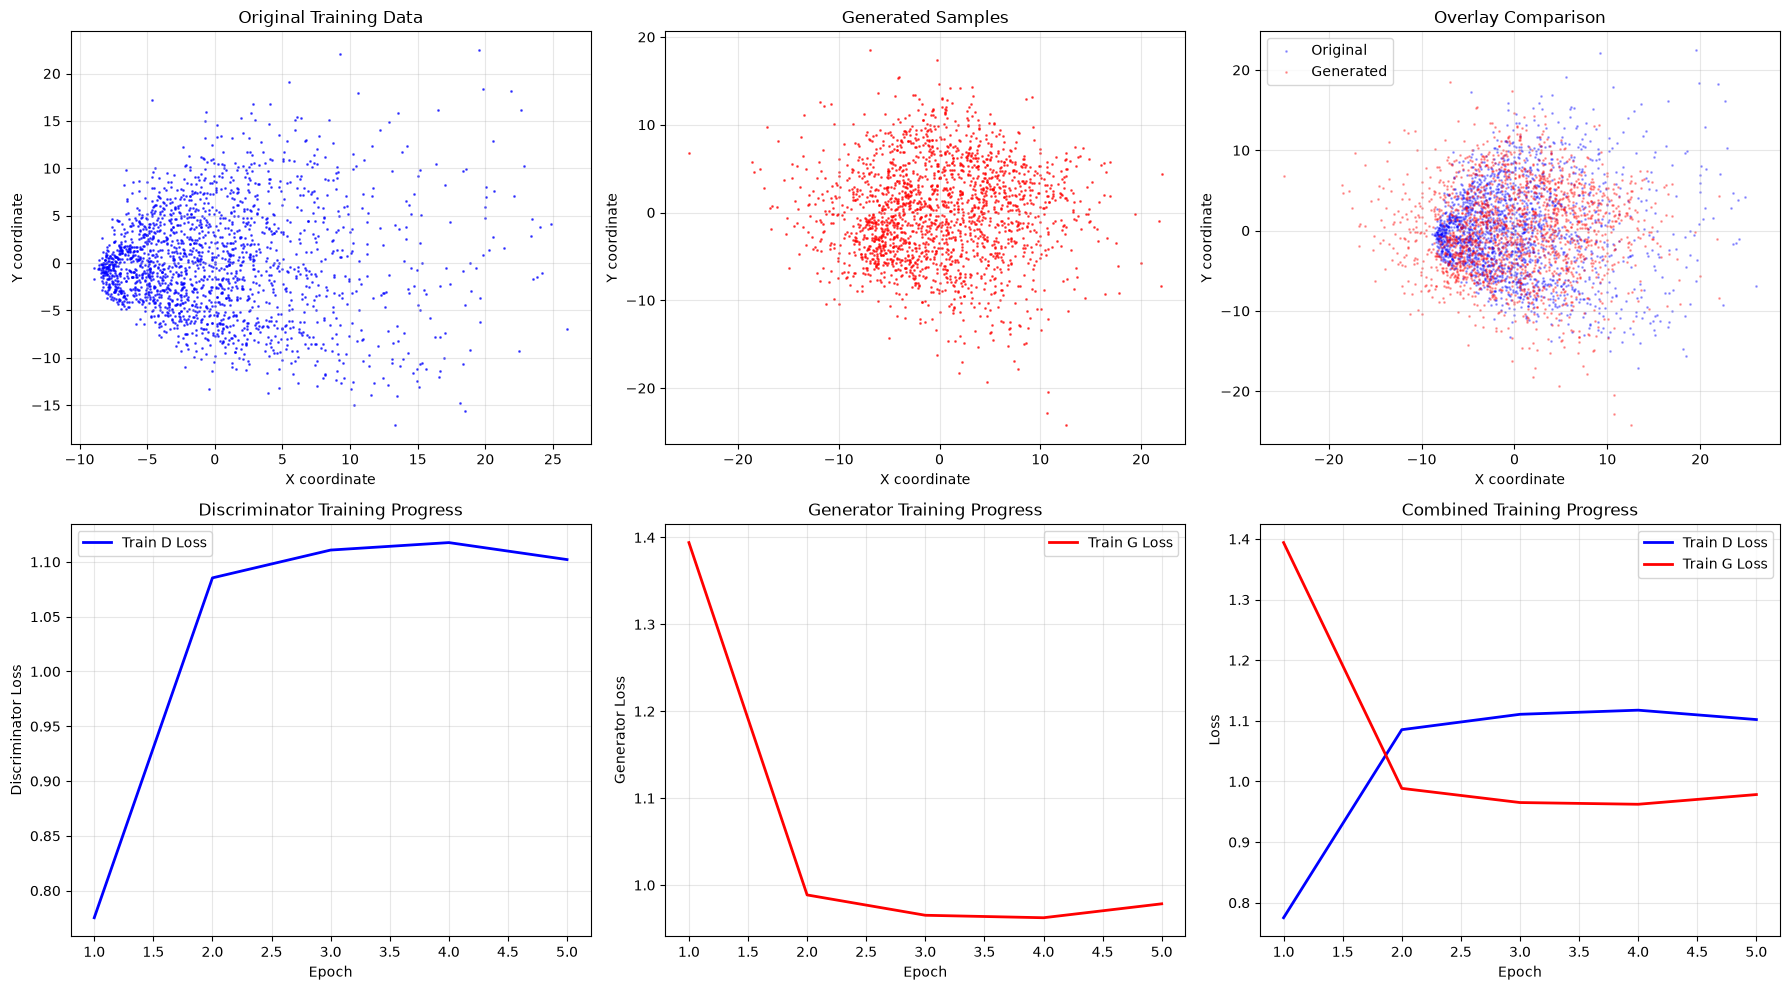

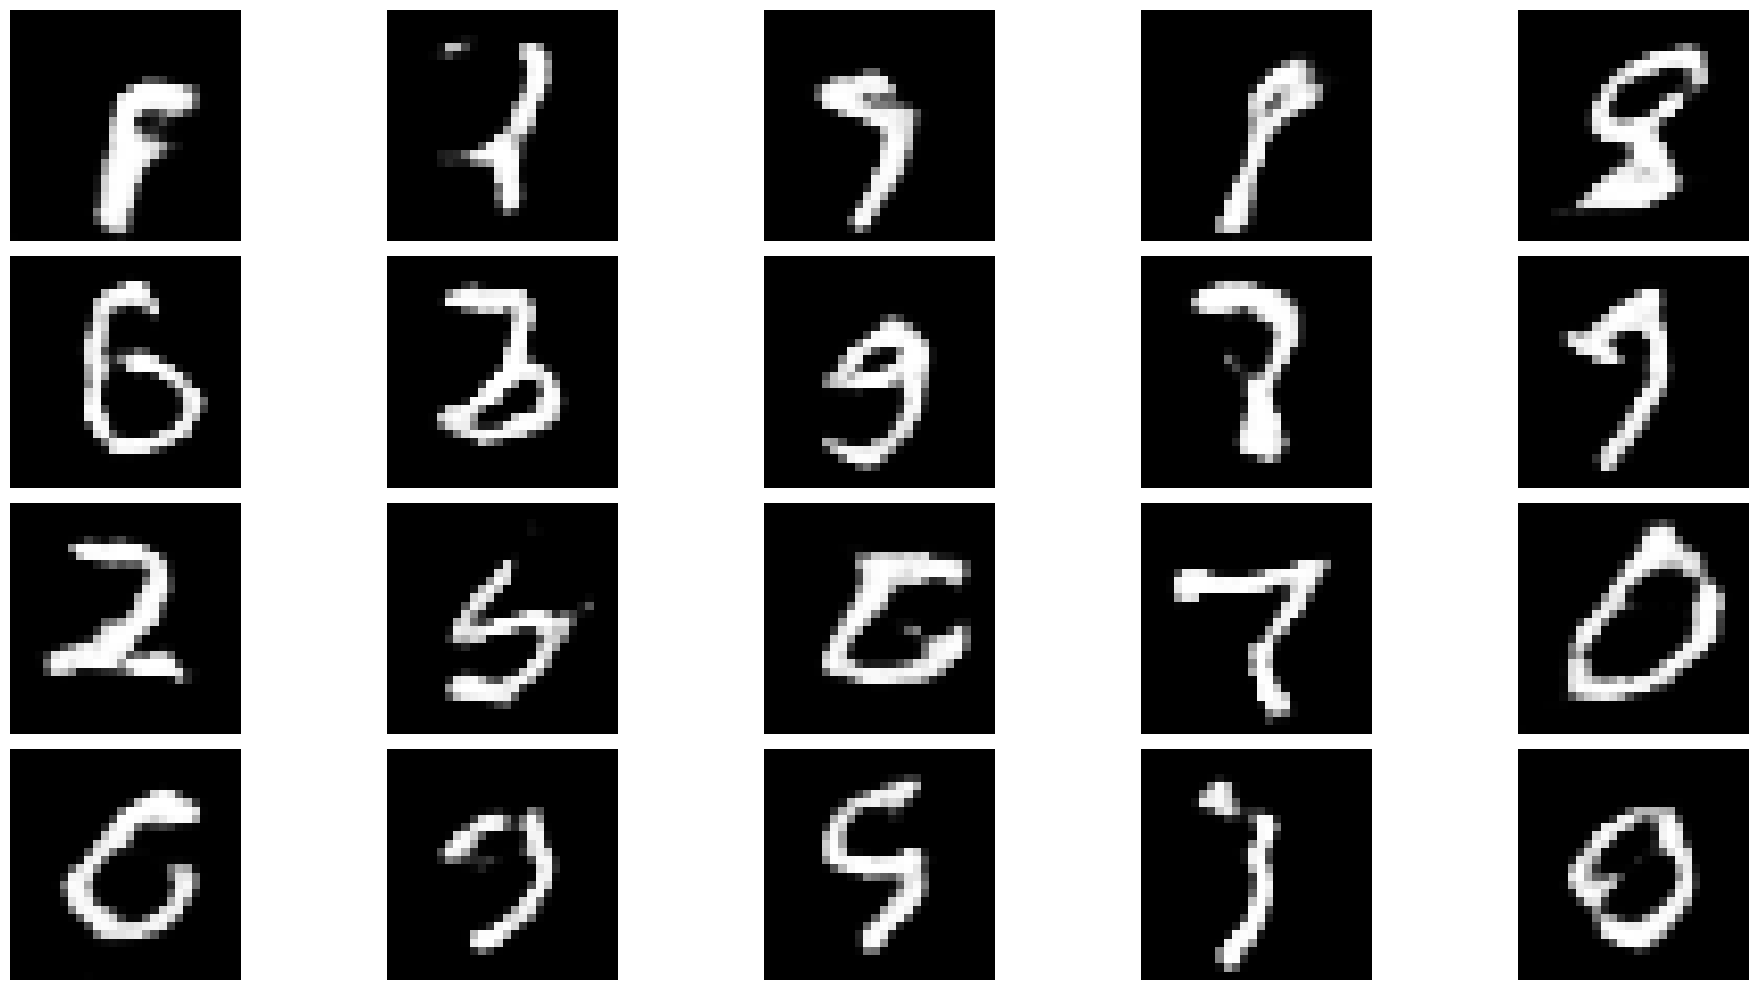

📈 Epoch 5 Summary:
   Train D Loss: 1.1021, Val D Loss: 1.2322
   Train G Loss: 0.9785, Val G Loss: 0.6511

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.115417	G_loss: 1.660102
Epoch: 6 [6400/60000 (11%)]	D_loss: 1.048061	G_loss: 0.759034
Epoch: 6 [12800/60000 (21%)]	D_loss: 1.191111	G_loss: 1.041010
Epoch: 6 [19200/60000 (32%)]	D_loss: 1.385367	G_loss: 1.846508
Epoch: 6 [25600/60000 (43%)]	D_loss: 1.143051	G_loss: 0.946453
Epoch: 6 [32000/60000 (53%)]	D_loss: 1.111126	G_loss: 0.932790
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.993781	G_loss: 1.095891
Epoch: 6 [44800/60000 (75%)]	D_loss: 1.102149	G_loss: 0.873653
Epoch: 6 [51200/60000 (85%)]	D_loss: 1.087205	G_loss: 1.068218
Epoch: 6 [57600/60000 (96%)]	D_loss: 1.097756	G_loss: 0.908756
====> Epoch: 6 Train D_loss: 1.1051, Train G_loss: 0.9849
====> Epoch: 6 Val D_loss: 1.2160, Val G_loss: 0.7027
📈 Epoch 6 Summary:
   Train D Loss: 1.1051, Val D Loss: 1.2160
   Train G Loss: 0.9849, Val G Loss: 0

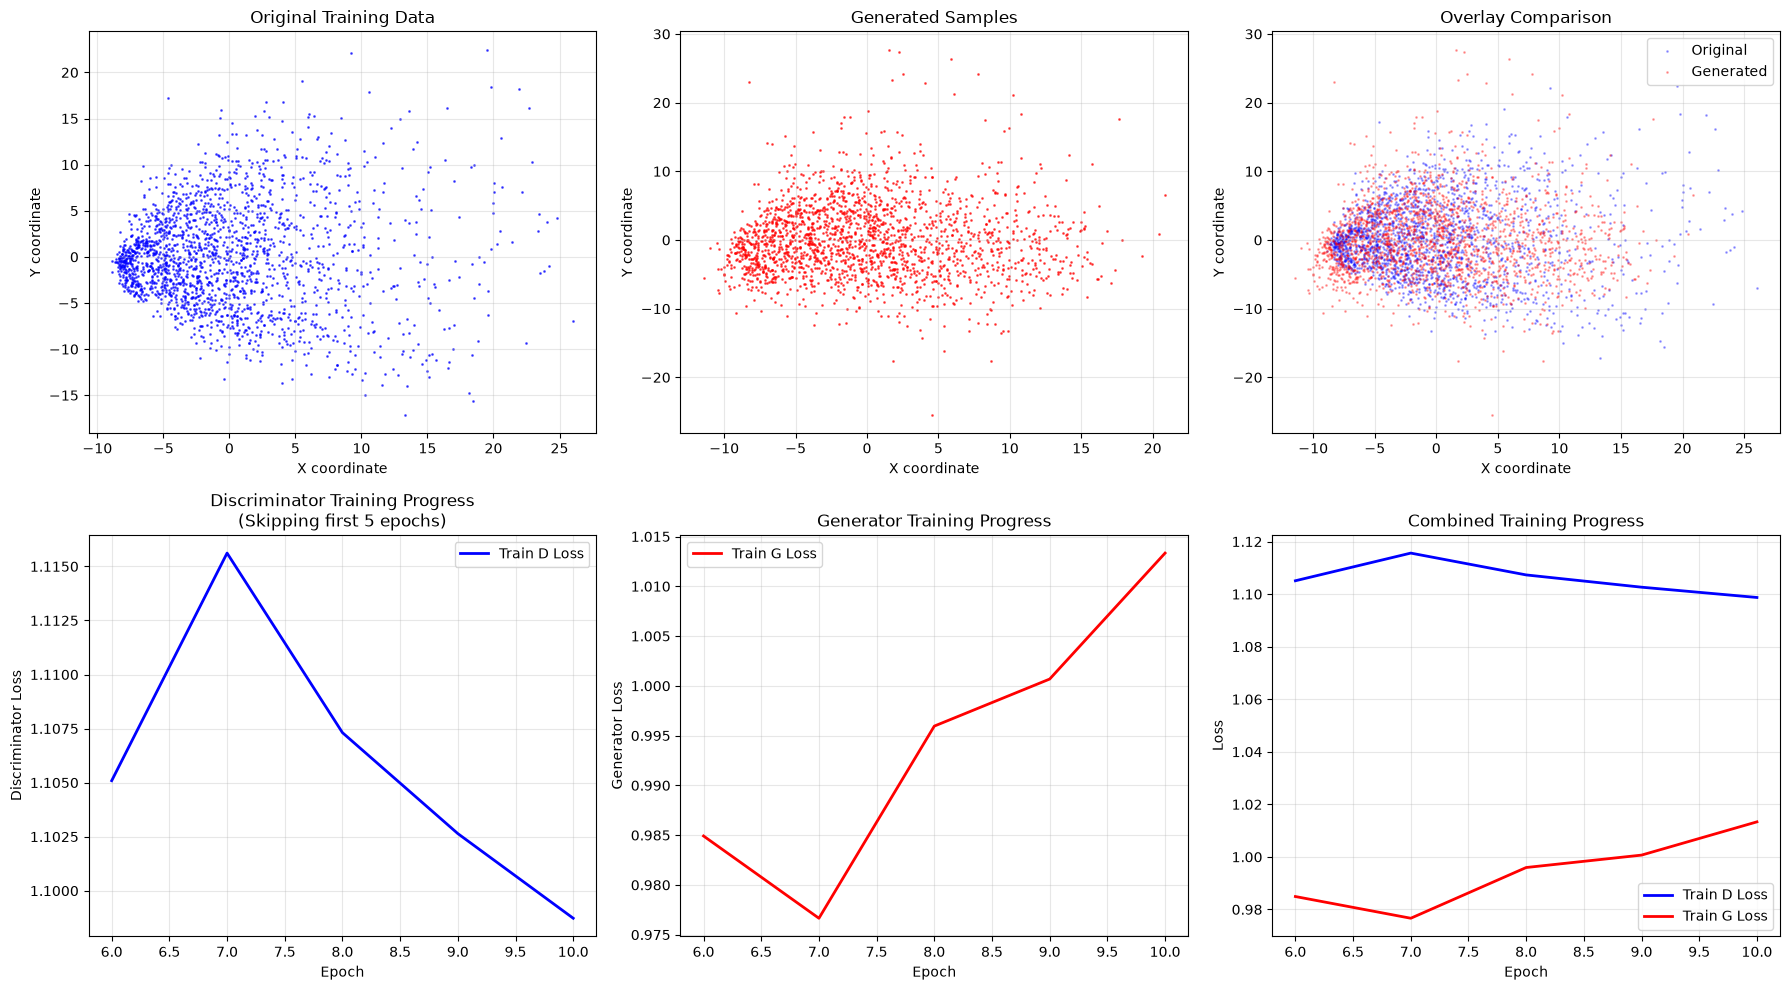

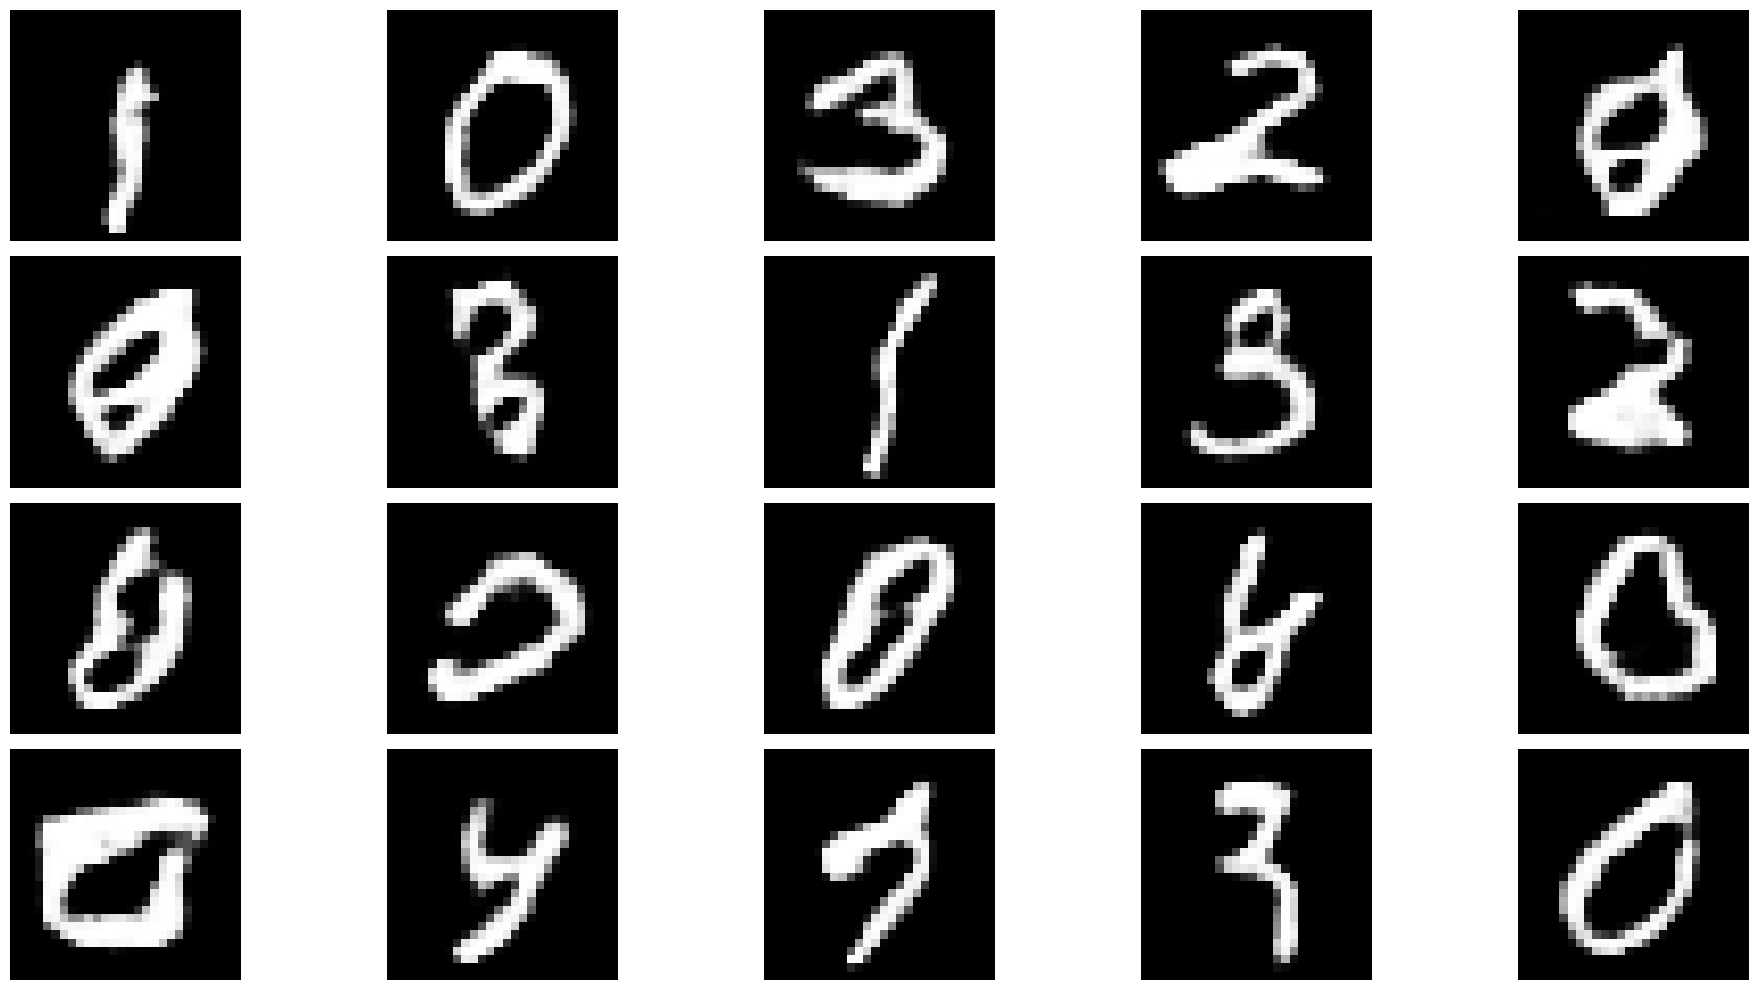

📈 Epoch 10 Summary:
   Train D Loss: 1.0987, Val D Loss: 1.2261
   Train G Loss: 1.0133, Val G Loss: 1.1110

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 1.116034	G_loss: 0.674778
Epoch: 11 [6400/60000 (11%)]	D_loss: 1.337919	G_loss: 0.512723
Epoch: 11 [12800/60000 (21%)]	D_loss: 1.137065	G_loss: 1.143665
Epoch: 11 [19200/60000 (32%)]	D_loss: 1.033528	G_loss: 1.281785
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.287282	G_loss: 0.426265
Epoch: 11 [32000/60000 (53%)]	D_loss: 1.085468	G_loss: 1.108905
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.048555	G_loss: 0.845861
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.000582	G_loss: 1.158911
Epoch: 11 [51200/60000 (85%)]	D_loss: 1.038372	G_loss: 1.205651
Epoch: 11 [57600/60000 (96%)]	D_loss: 1.130239	G_loss: 0.533418
====> Epoch: 11 Train D_loss: 1.0893, Train G_loss: 1.0263
====> Epoch: 11 Val D_loss: 1.2981, Val G_loss: 1.3055
📈 Epoch 11 Summary:
   Train D Loss: 1.0893, Val D Loss: 1.2981
   Train G Loss: 1.0263

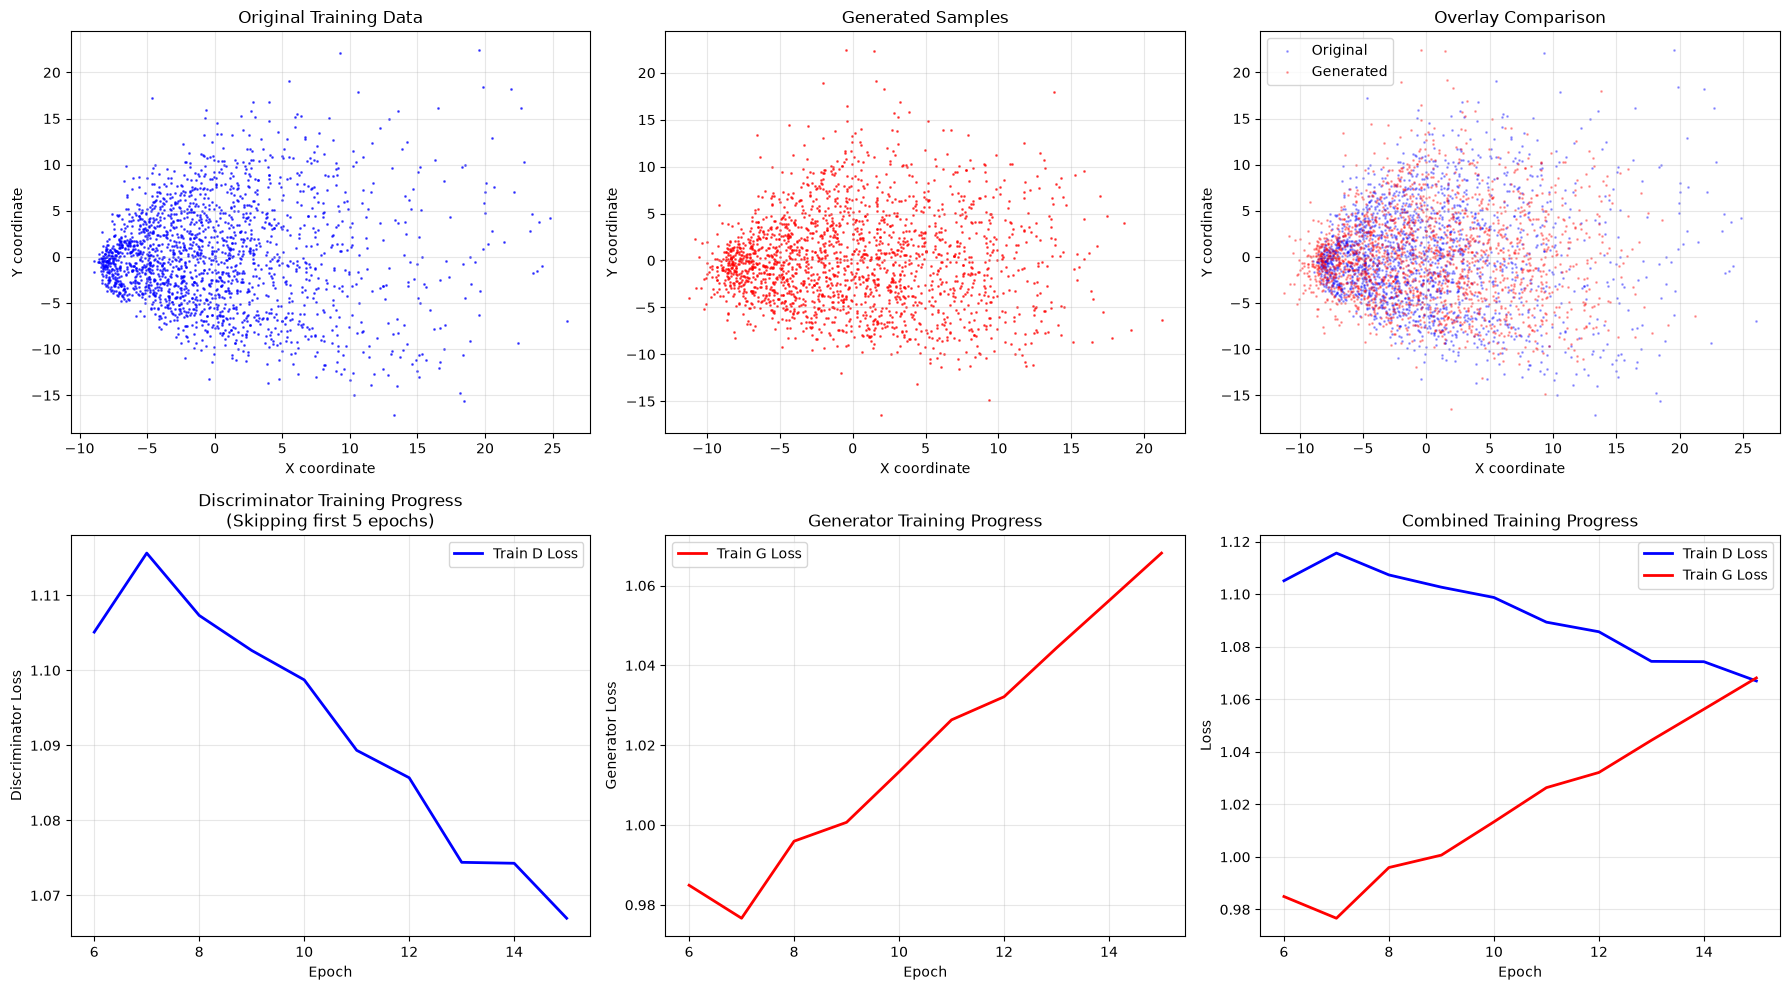

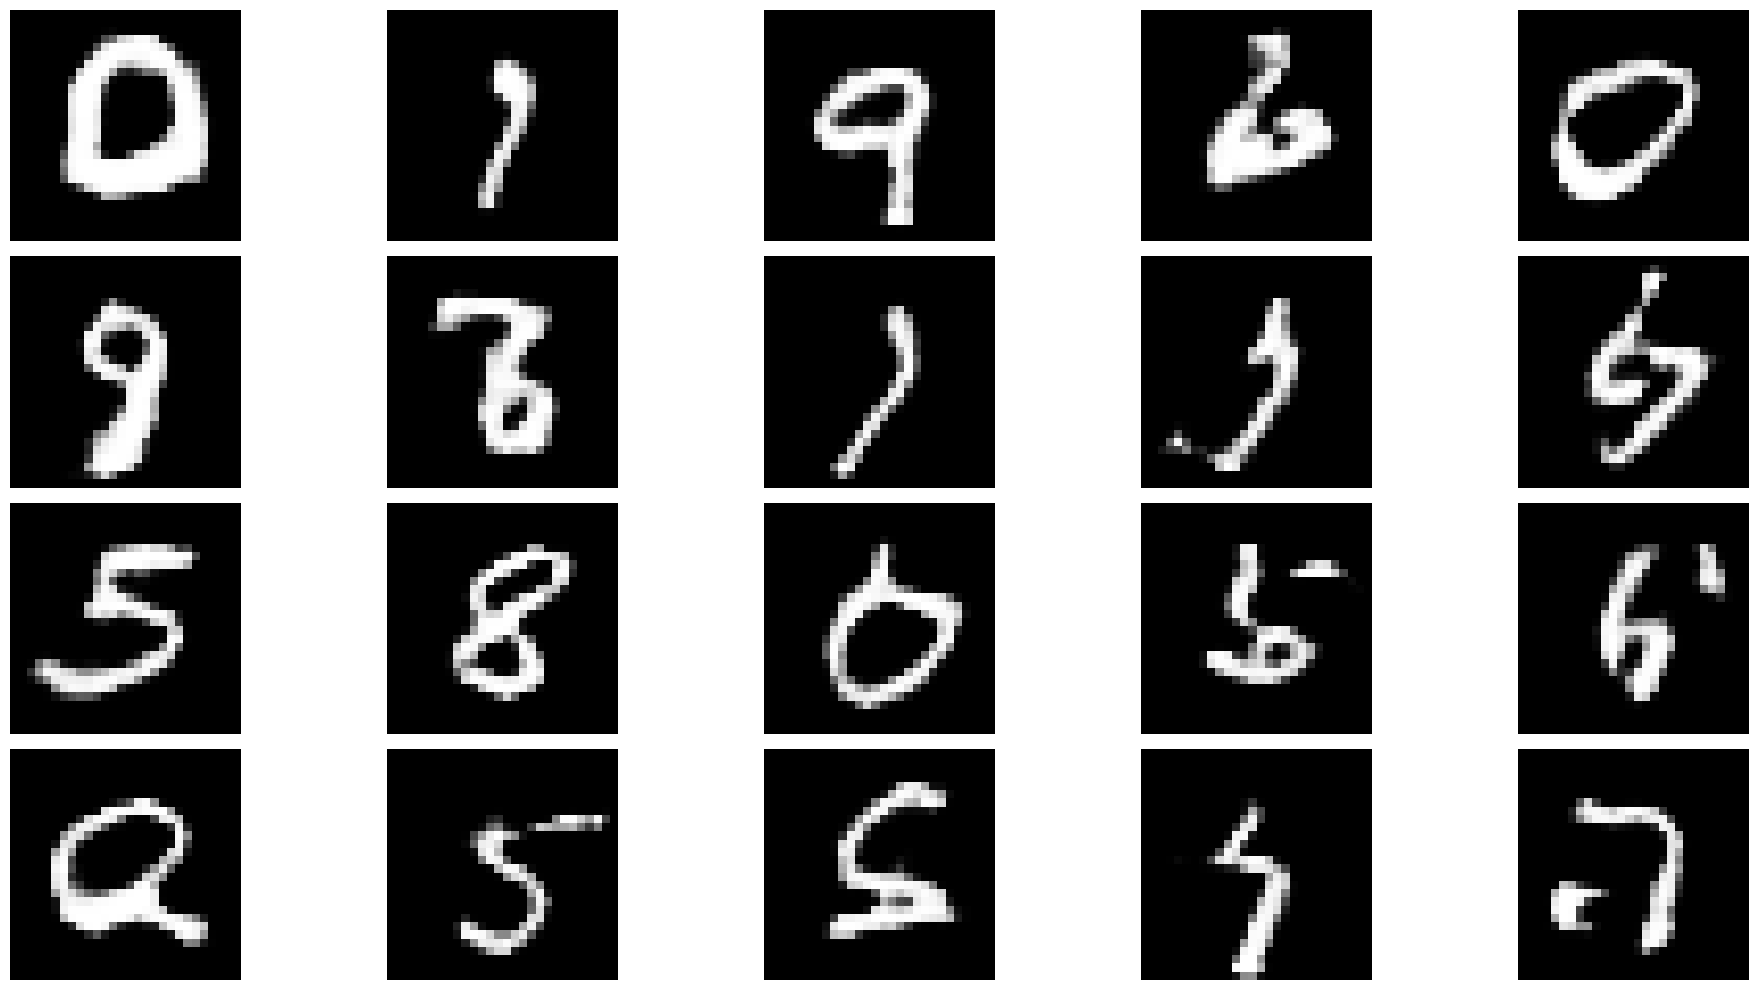

📈 Epoch 15 Summary:
   Train D Loss: 1.0670, Val D Loss: 1.1798
   Train G Loss: 1.0681, Val G Loss: 0.9842

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 1.026618	G_loss: 1.311816
Epoch: 16 [6400/60000 (11%)]	D_loss: 1.193405	G_loss: 1.579702
Epoch: 16 [12800/60000 (21%)]	D_loss: 1.051446	G_loss: 0.661096
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.944950	G_loss: 0.959713
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.084054	G_loss: 0.802837
Epoch: 16 [32000/60000 (53%)]	D_loss: 1.074143	G_loss: 1.115199
Epoch: 16 [38400/60000 (64%)]	D_loss: 1.123723	G_loss: 1.762769
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.969857	G_loss: 0.939740
Epoch: 16 [51200/60000 (85%)]	D_loss: 1.093661	G_loss: 1.153033
Epoch: 16 [57600/60000 (96%)]	D_loss: 1.321436	G_loss: 1.543946
====> Epoch: 16 Train D_loss: 1.0586, Train G_loss: 1.0822
====> Epoch: 16 Val D_loss: 1.4251, Val G_loss: 1.5981
📈 Epoch 16 Summary:
   Train D Loss: 1.0586, Val D Loss: 1.4251
   Train G Loss: 1.0822

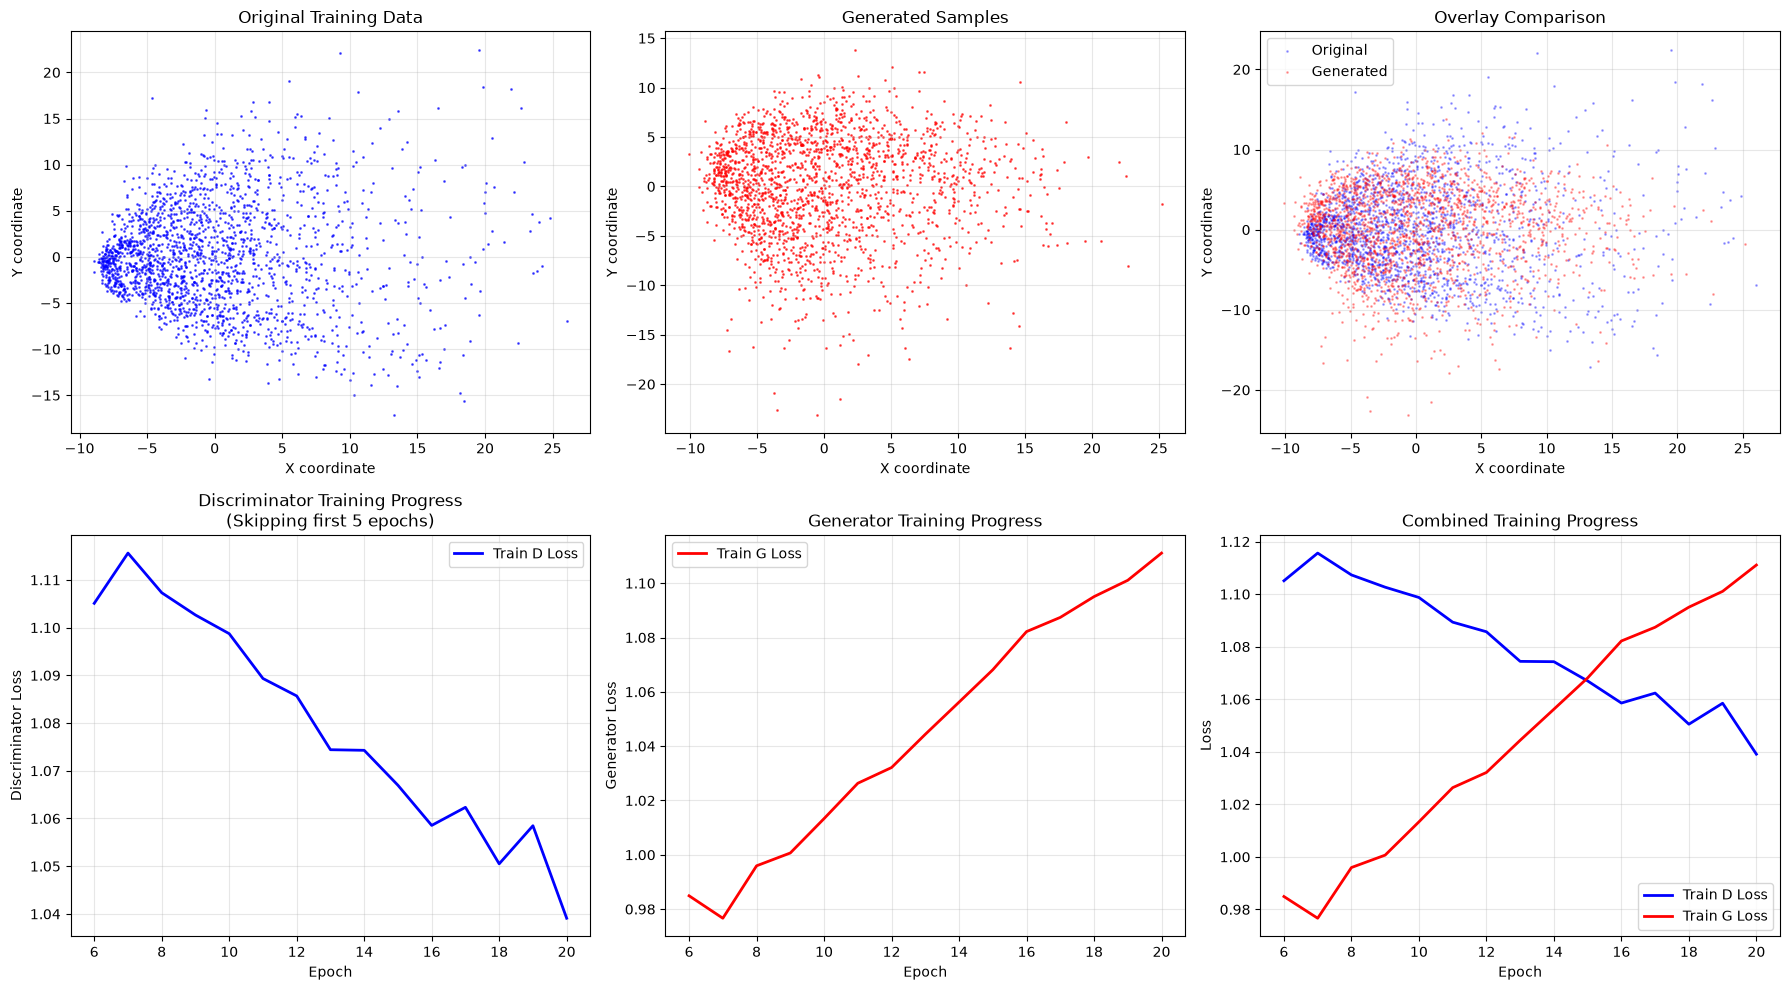

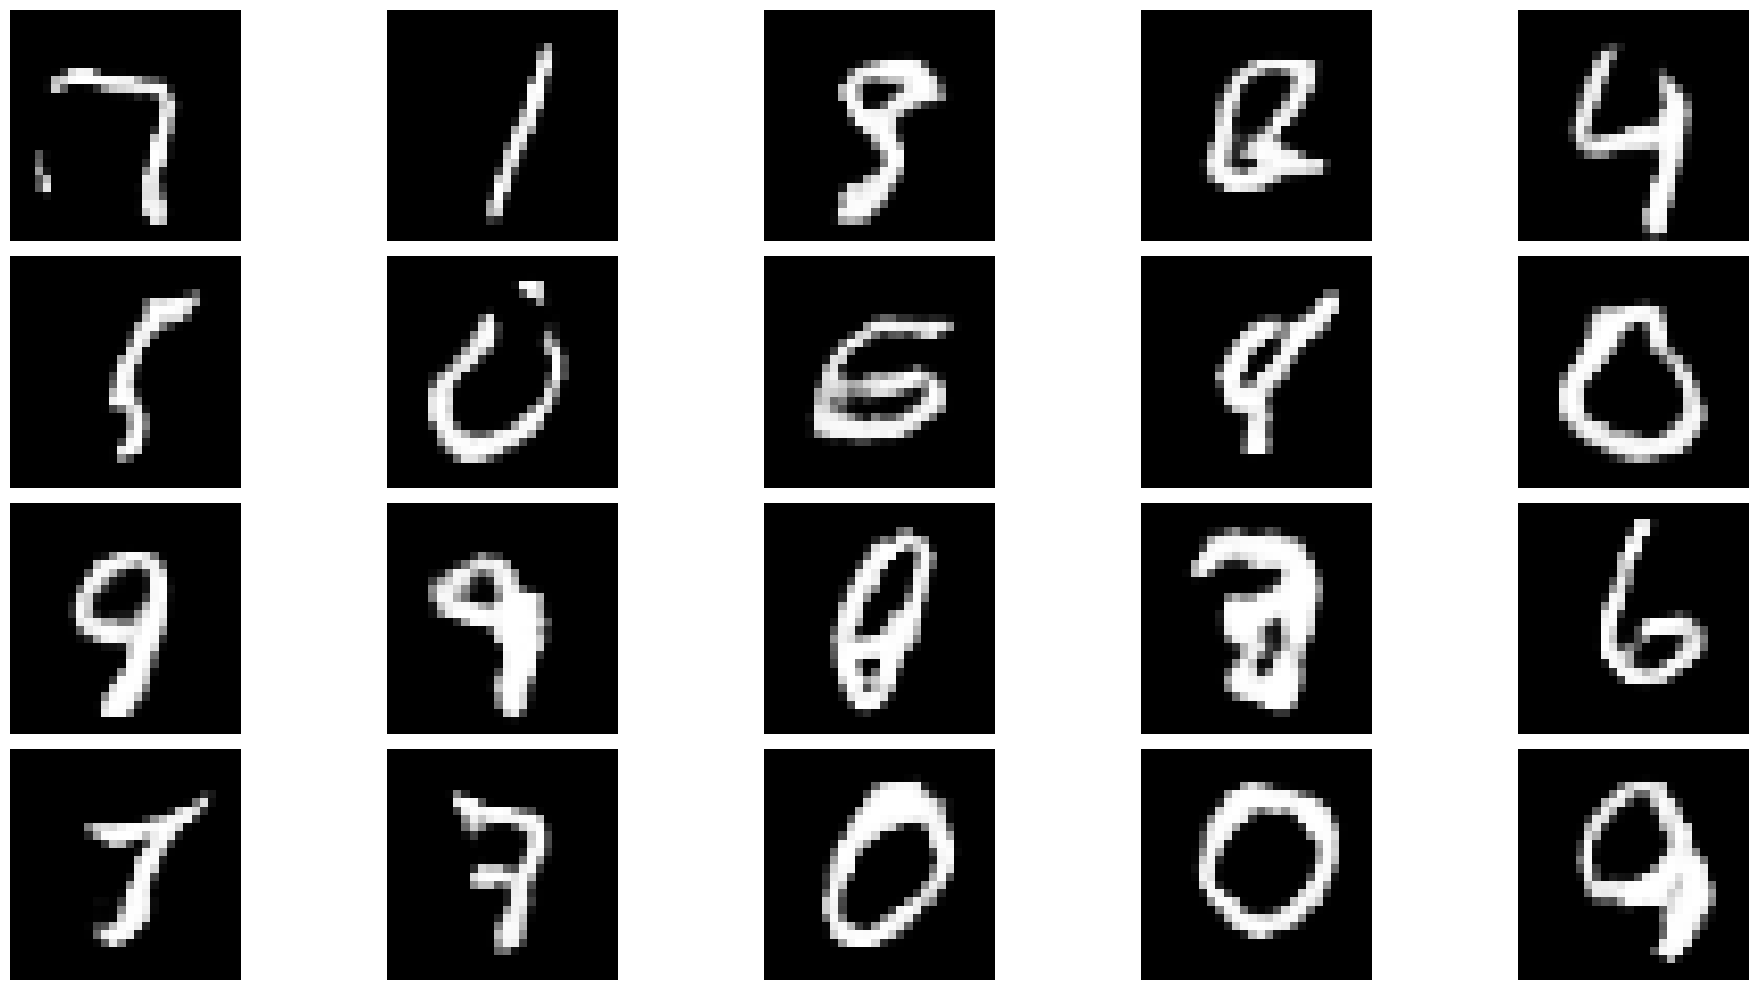

📈 Epoch 20 Summary:
   Train D Loss: 1.0391, Val D Loss: 1.1737
   Train G Loss: 1.1111, Val G Loss: 0.9193

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.973273	G_loss: 0.959530
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.954879	G_loss: 1.526681
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.935635	G_loss: 1.432266
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.997253	G_loss: 1.054449
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.968799	G_loss: 1.257346
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.966607	G_loss: 1.258710
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.906061	G_loss: 1.285671
Epoch: 21 [44800/60000 (75%)]	D_loss: 1.071973	G_loss: 0.973975
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.976966	G_loss: 1.331300
Epoch: 21 [57600/60000 (96%)]	D_loss: 1.033457	G_loss: 1.100847
====> Epoch: 21 Train D_loss: 1.0351, Train G_loss: 1.1186
====> Epoch: 21 Val D_loss: 1.1819, Val G_loss: 1.1454
📈 Epoch 21 Summary:
   Train D Loss: 1.0351, Val D Loss: 1.1819
   Train G Loss: 1.1186

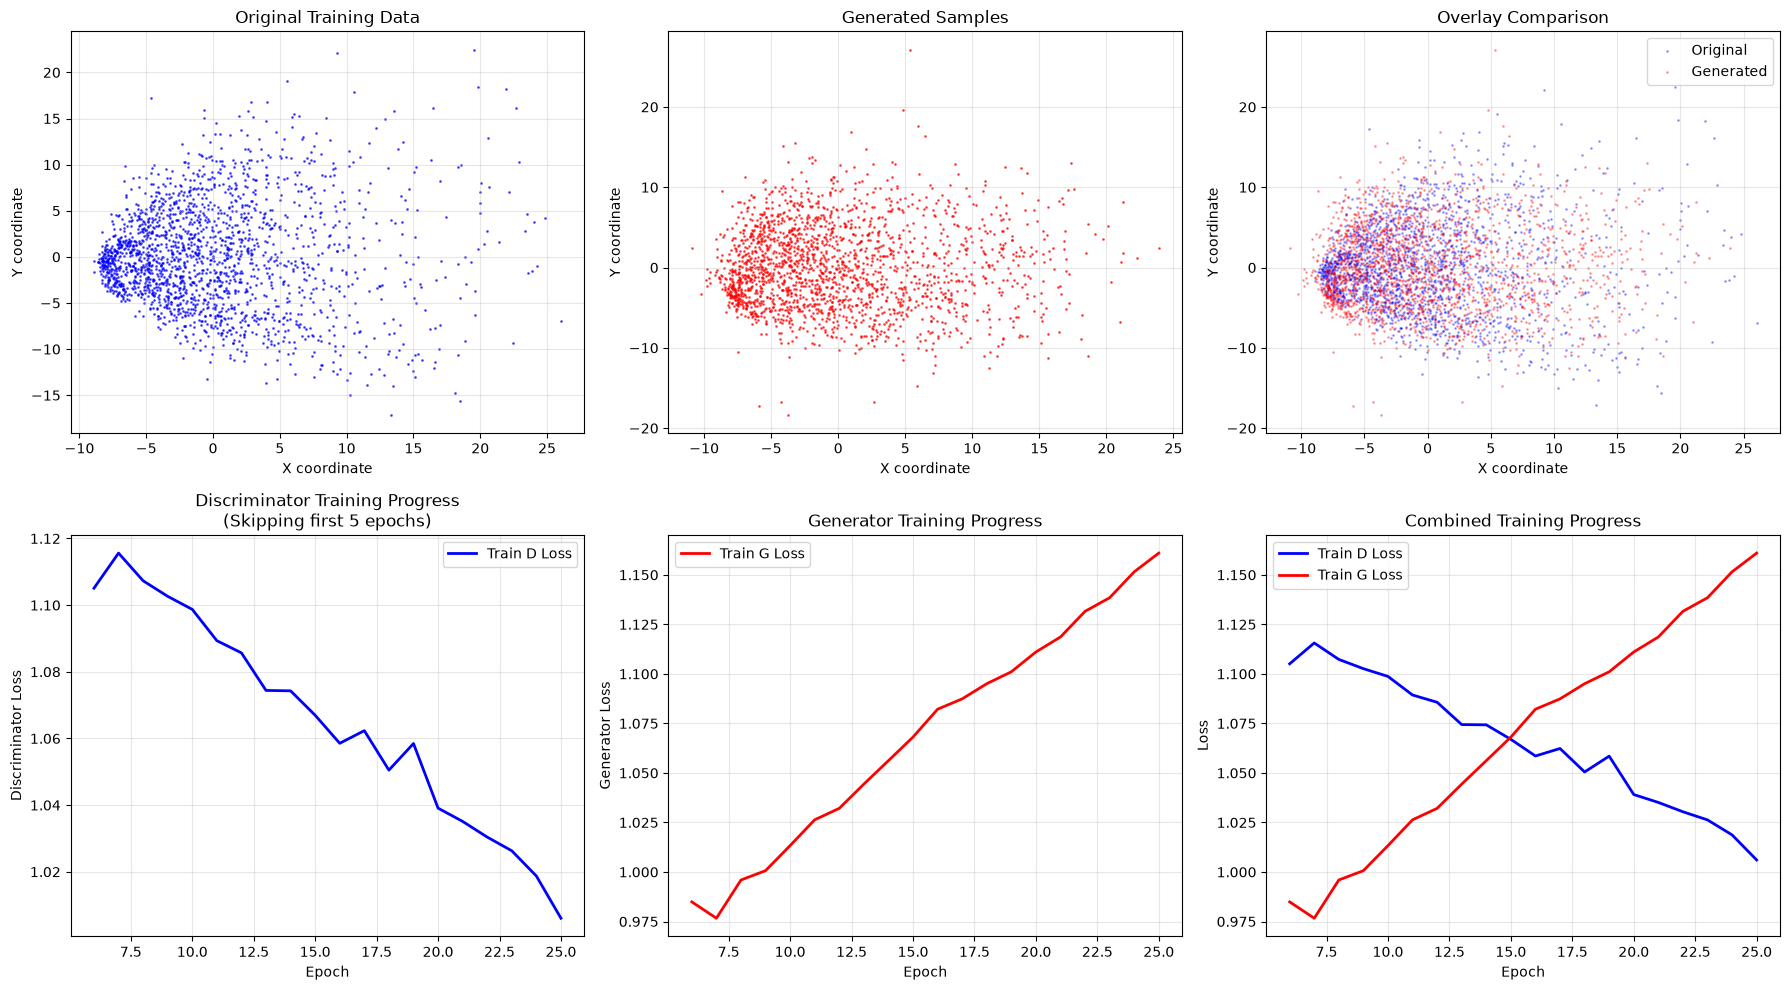

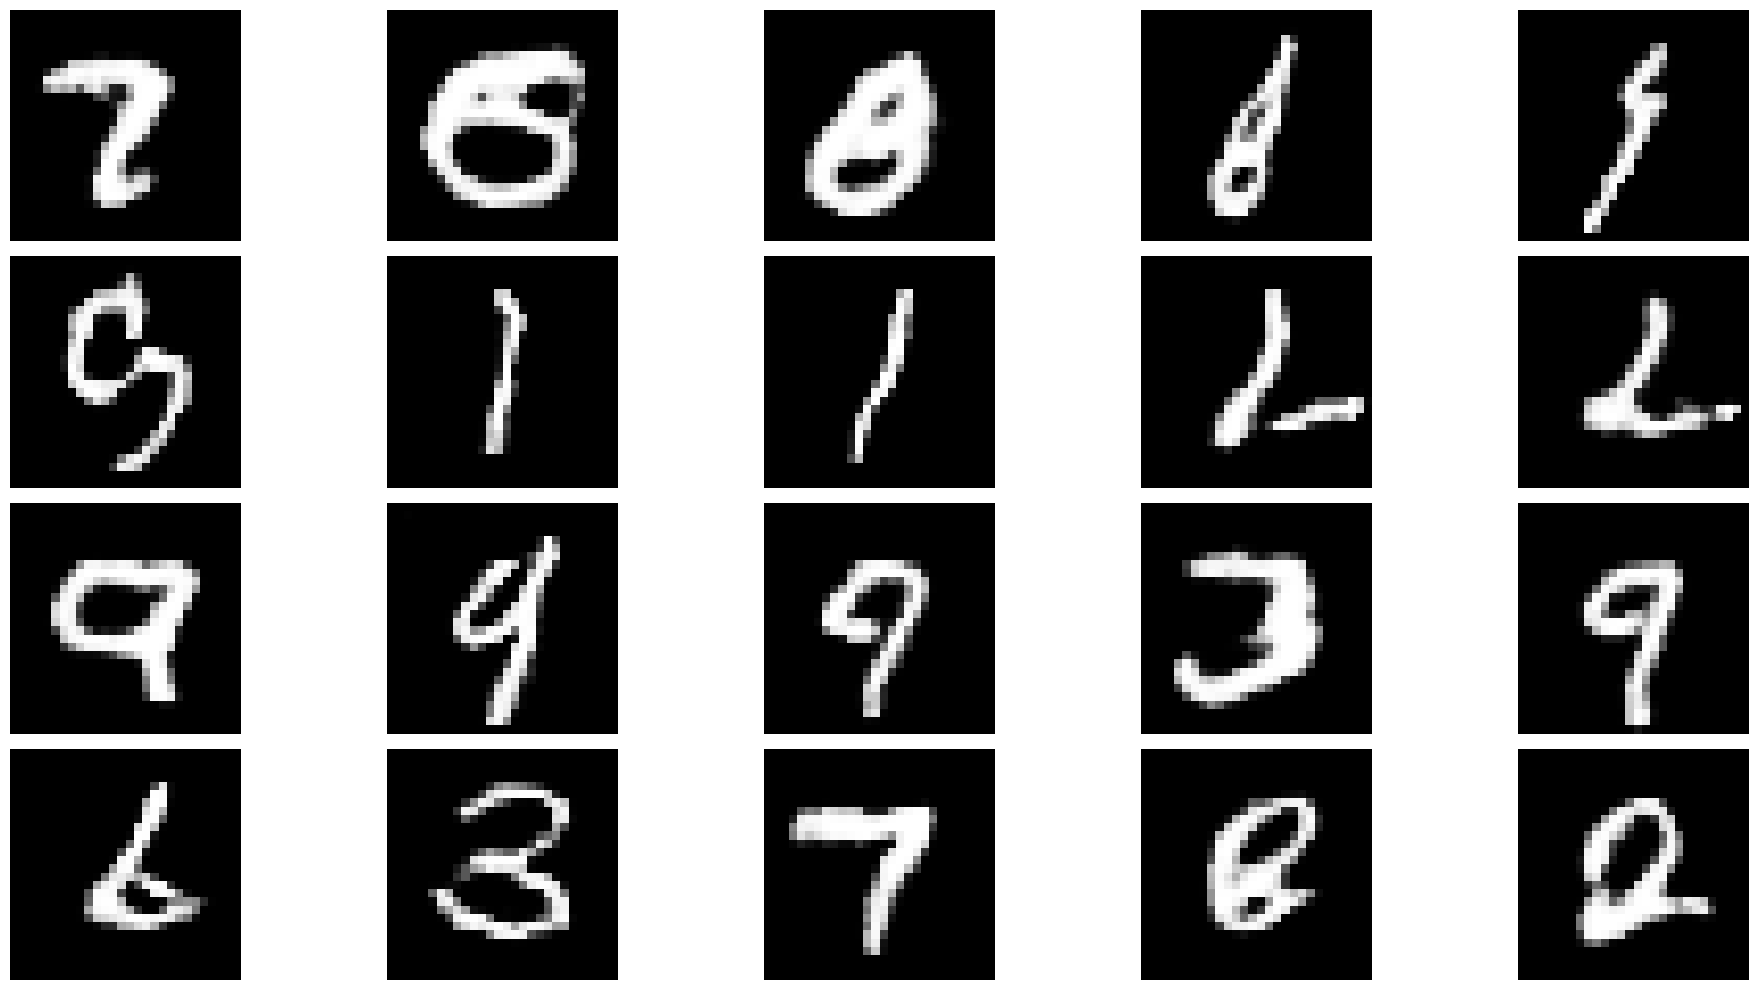

📈 Epoch 25 Summary:
   Train D Loss: 1.0061, Val D Loss: 1.1672
   Train G Loss: 1.1610, Val G Loss: 1.0552

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 1.015593	G_loss: 1.011364
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.884956	G_loss: 0.998909
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.926287	G_loss: 1.244925
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.948798	G_loss: 1.480851
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.932342	G_loss: 1.209673
Epoch: 26 [32000/60000 (53%)]	D_loss: 1.045417	G_loss: 0.934311
Epoch: 26 [38400/60000 (64%)]	D_loss: 0.929575	G_loss: 0.865414
Epoch: 26 [44800/60000 (75%)]	D_loss: 1.125419	G_loss: 0.874148
Epoch: 26 [51200/60000 (85%)]	D_loss: 1.034543	G_loss: 1.315702
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.978733	G_loss: 1.338720
====> Epoch: 26 Train D_loss: 1.0034, Train G_loss: 1.1682
====> Epoch: 26 Val D_loss: 1.3410, Val G_loss: 0.4982
📈 Epoch 26 Summary:
   Train D Loss: 1.0034, Val D Loss: 1.3410
   Train G Loss: 1.1682

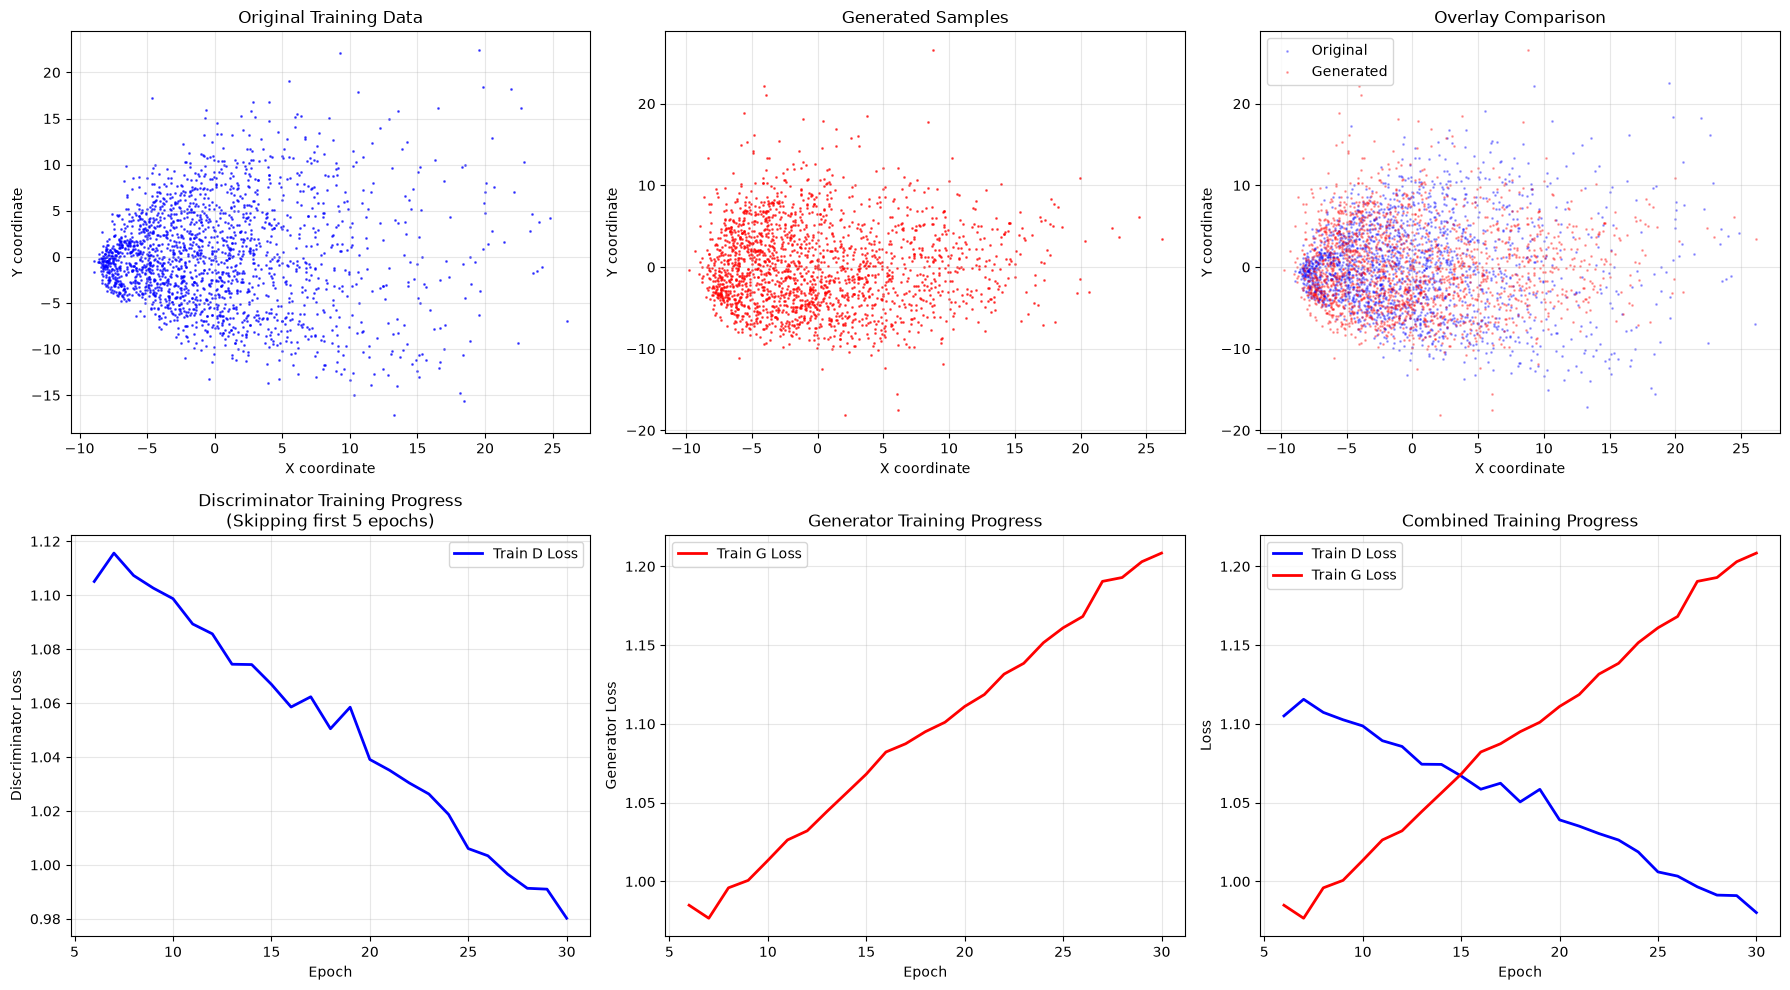

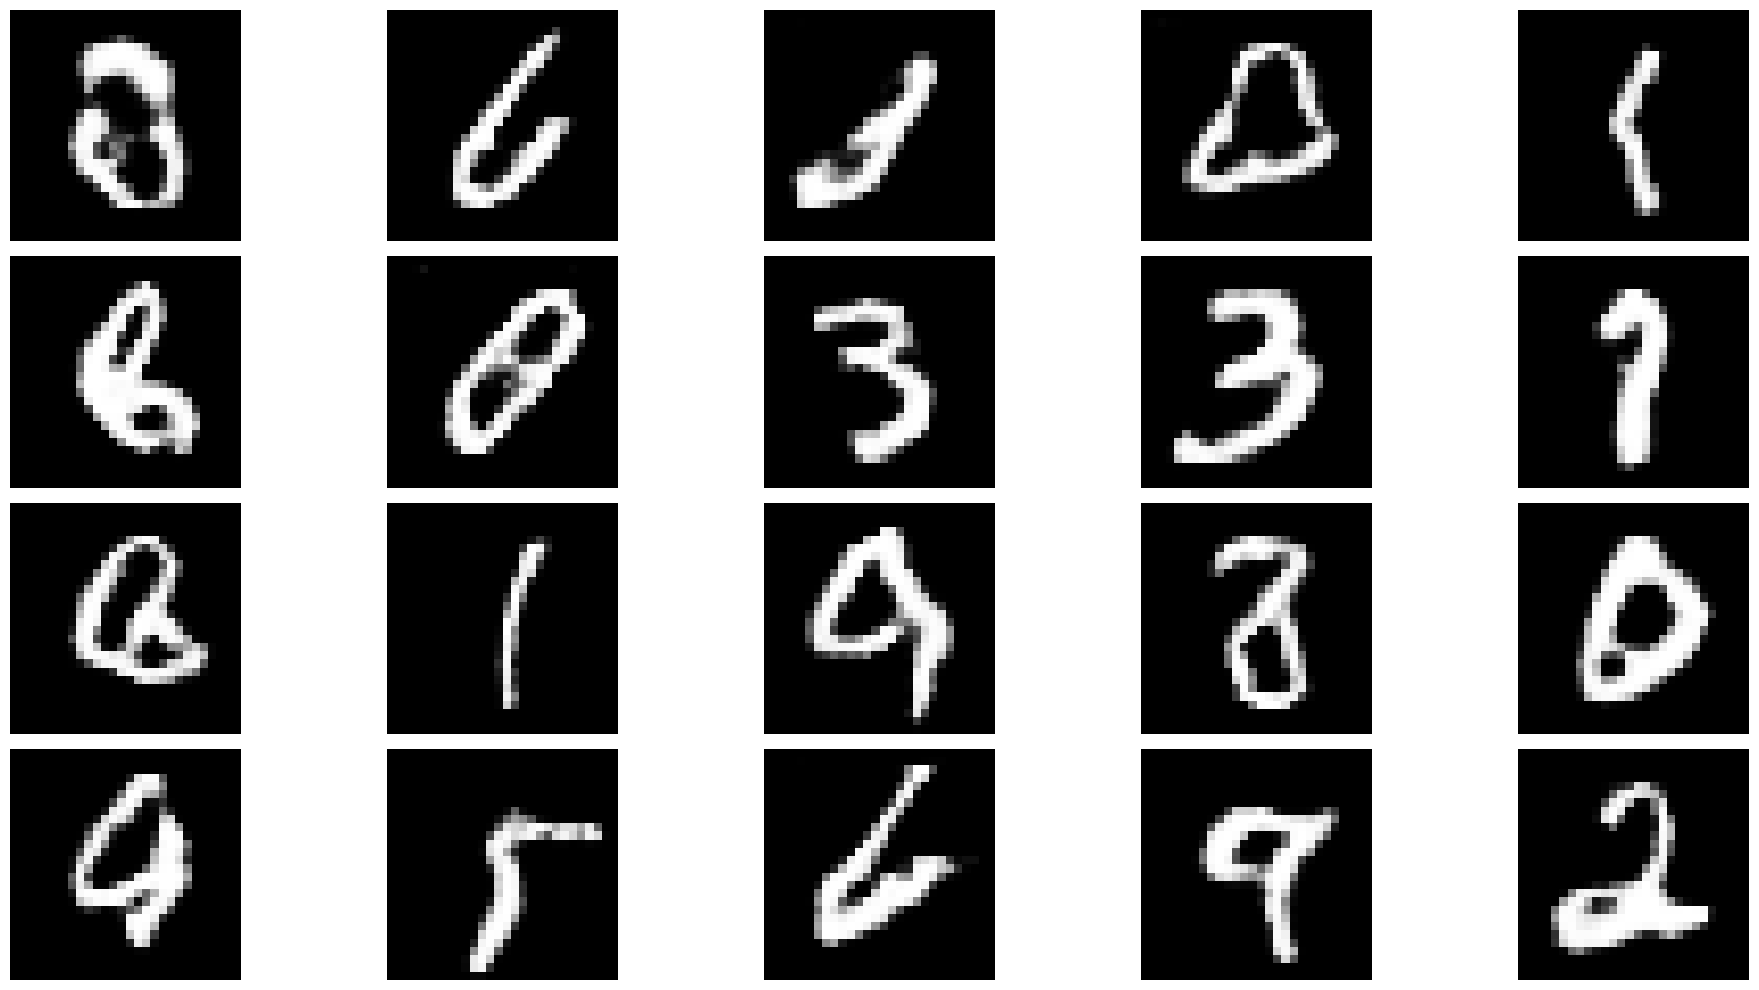

📈 Epoch 30 Summary:
   Train D Loss: 0.9802, Val D Loss: 1.1583
   Train G Loss: 1.2084, Val G Loss: 1.2218

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.949924	G_loss: 0.892519
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.996400	G_loss: 1.335487
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.902865	G_loss: 1.298480
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.883131	G_loss: 1.218355
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.968368	G_loss: 1.548000
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.975634	G_loss: 0.803033
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.882397	G_loss: 1.210918
Epoch: 31 [44800/60000 (75%)]	D_loss: 1.009478	G_loss: 1.302551
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.991556	G_loss: 1.478347
Epoch: 31 [57600/60000 (96%)]	D_loss: 1.009000	G_loss: 1.270689
====> Epoch: 31 Train D_loss: 0.9763, Train G_loss: 1.2214
====> Epoch: 31 Val D_loss: 1.1933, Val G_loss: 1.4021
📈 Epoch 31 Summary:
   Train D Loss: 0.9763, Val D Loss: 1.1933
   Train G Loss: 1.2214

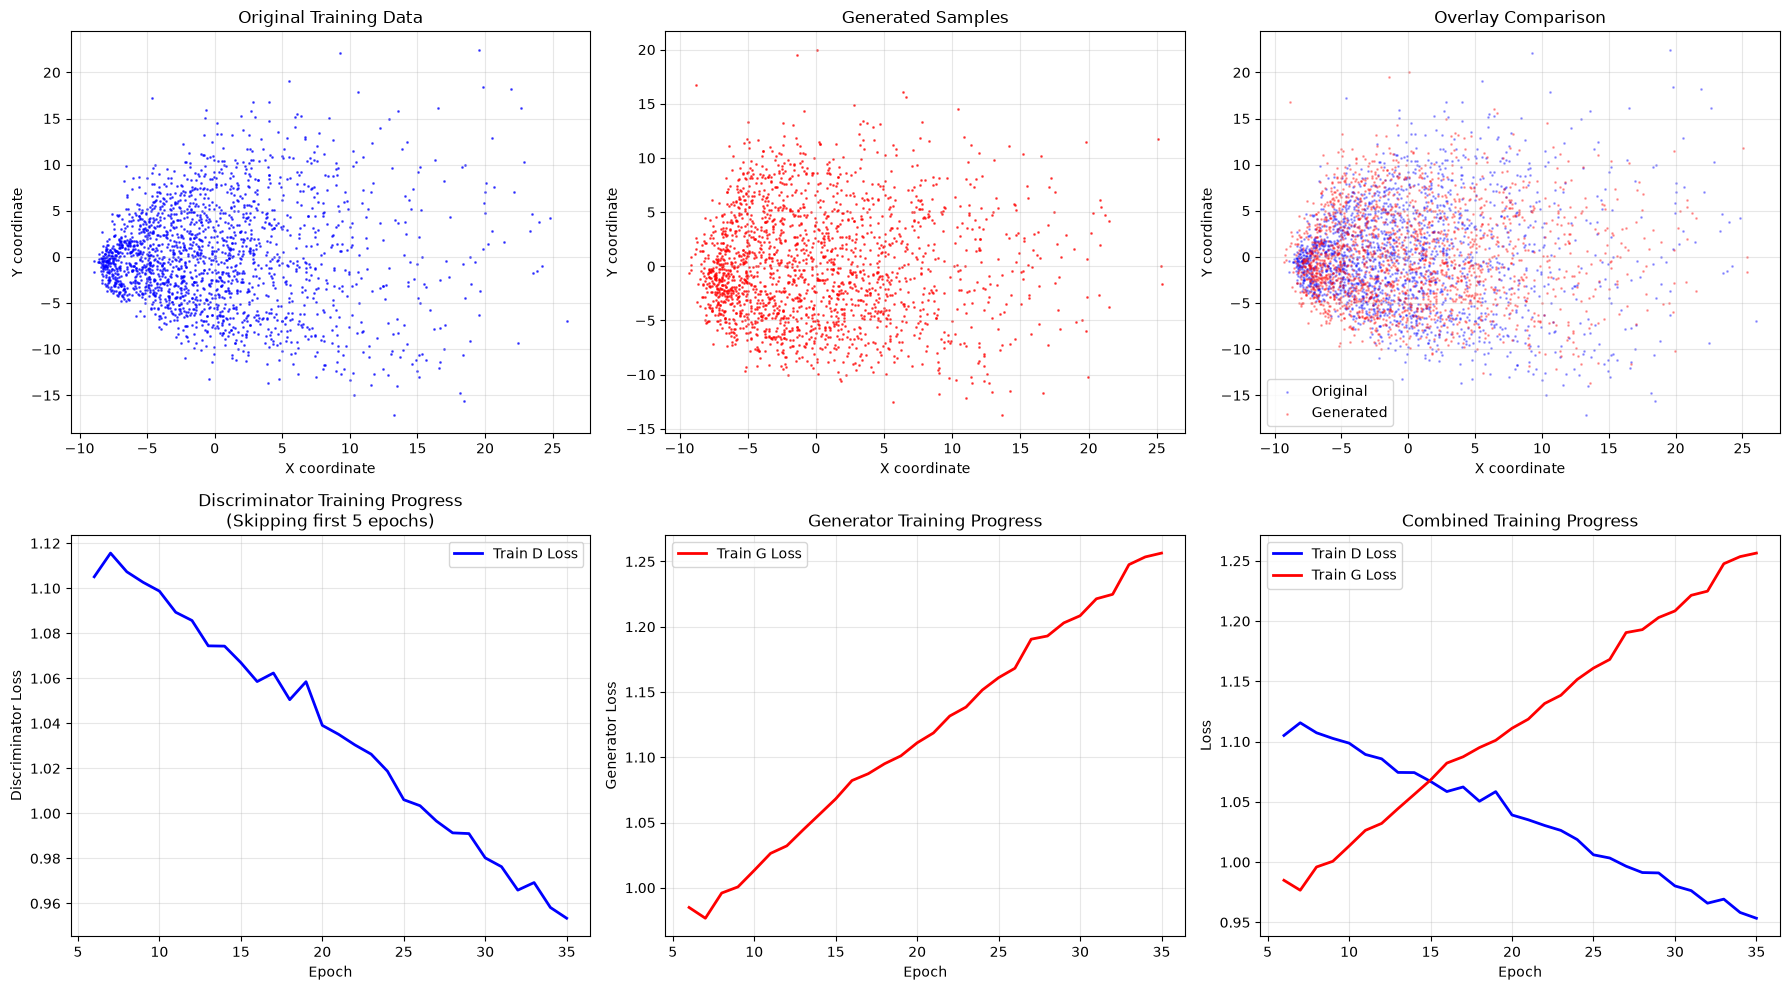

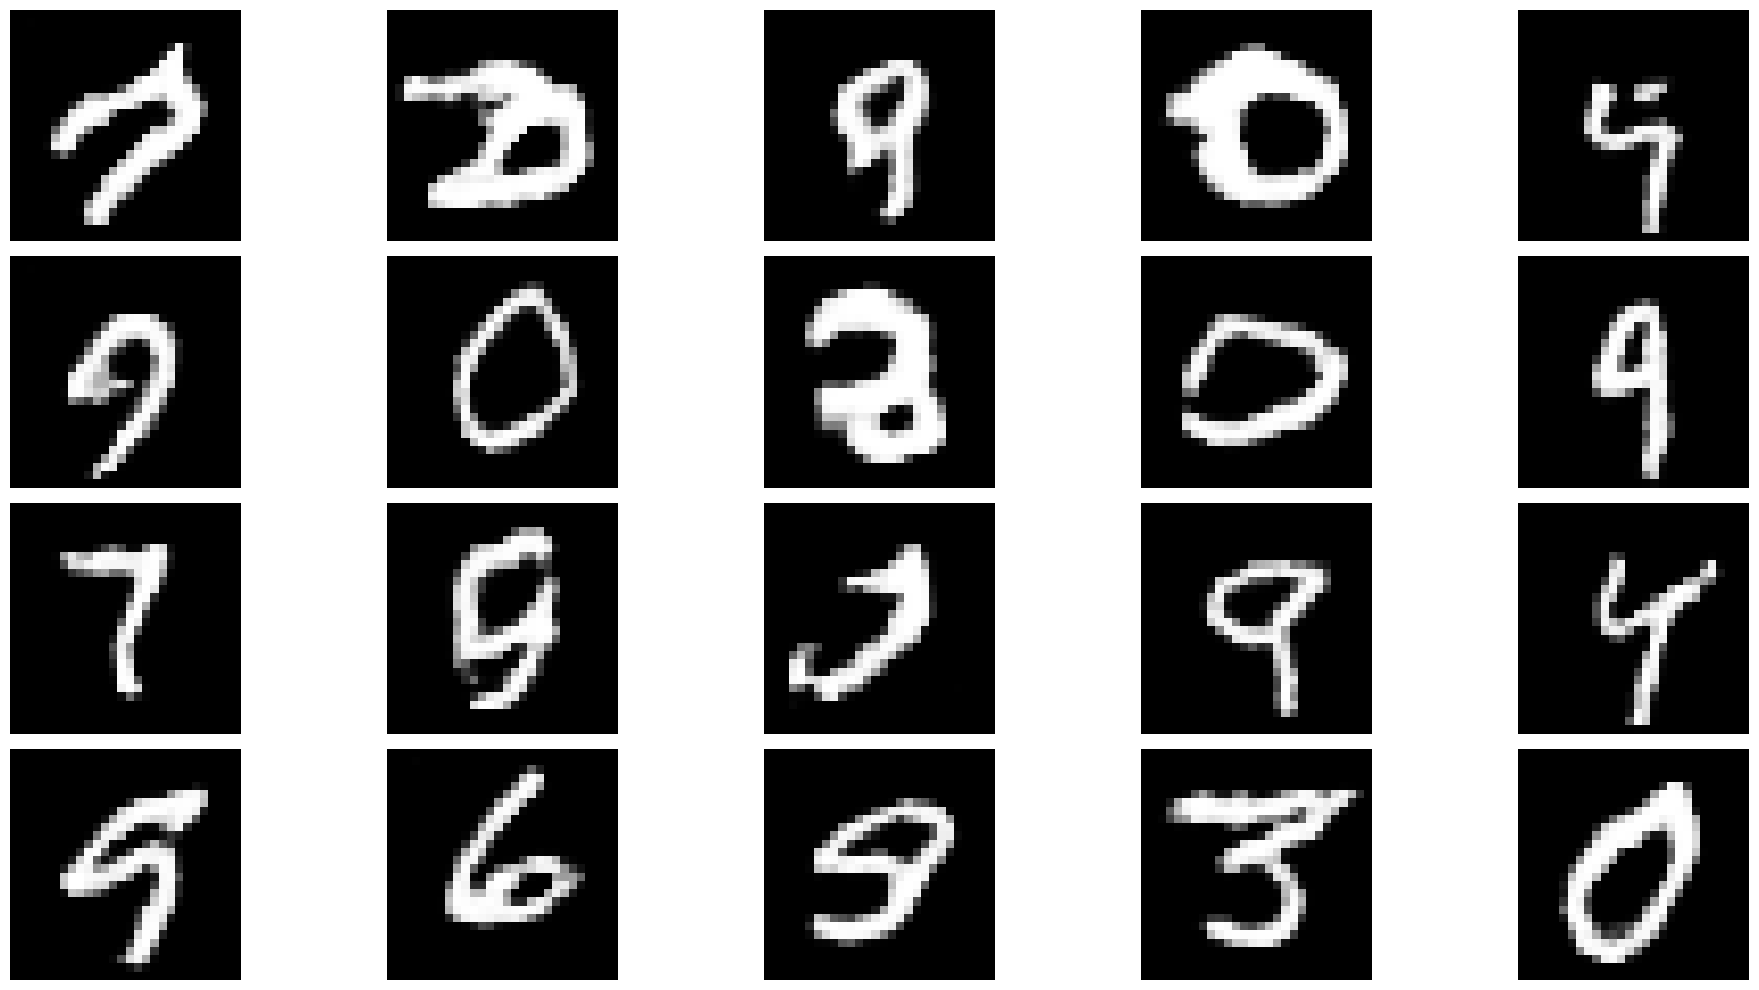

📈 Epoch 35 Summary:
   Train D Loss: 0.9534, Val D Loss: 1.1116
   Train G Loss: 1.2564, Val G Loss: 1.2069

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.967513	G_loss: 1.472363
Epoch: 36 [6400/60000 (11%)]	D_loss: 1.168806	G_loss: 0.686110
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.848735	G_loss: 1.591538
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.863628	G_loss: 1.126621
Epoch: 36 [25600/60000 (43%)]	D_loss: 0.929069	G_loss: 0.995892
Epoch: 36 [32000/60000 (53%)]	D_loss: 1.052953	G_loss: 0.832107
Epoch: 36 [38400/60000 (64%)]	D_loss: 1.175511	G_loss: 2.146186
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.946877	G_loss: 1.325090
Epoch: 36 [51200/60000 (85%)]	D_loss: 0.920421	G_loss: 1.838871
Epoch: 36 [57600/60000 (96%)]	D_loss: 1.173538	G_loss: 1.736480
====> Epoch: 36 Train D_loss: 0.9424, Train G_loss: 1.2670
====> Epoch: 36 Val D_loss: 1.1905, Val G_loss: 1.5267
📈 Epoch 36 Summary:
   Train D Loss: 0.9424, Val D Loss: 1.1905
   Train G Loss: 1.2670

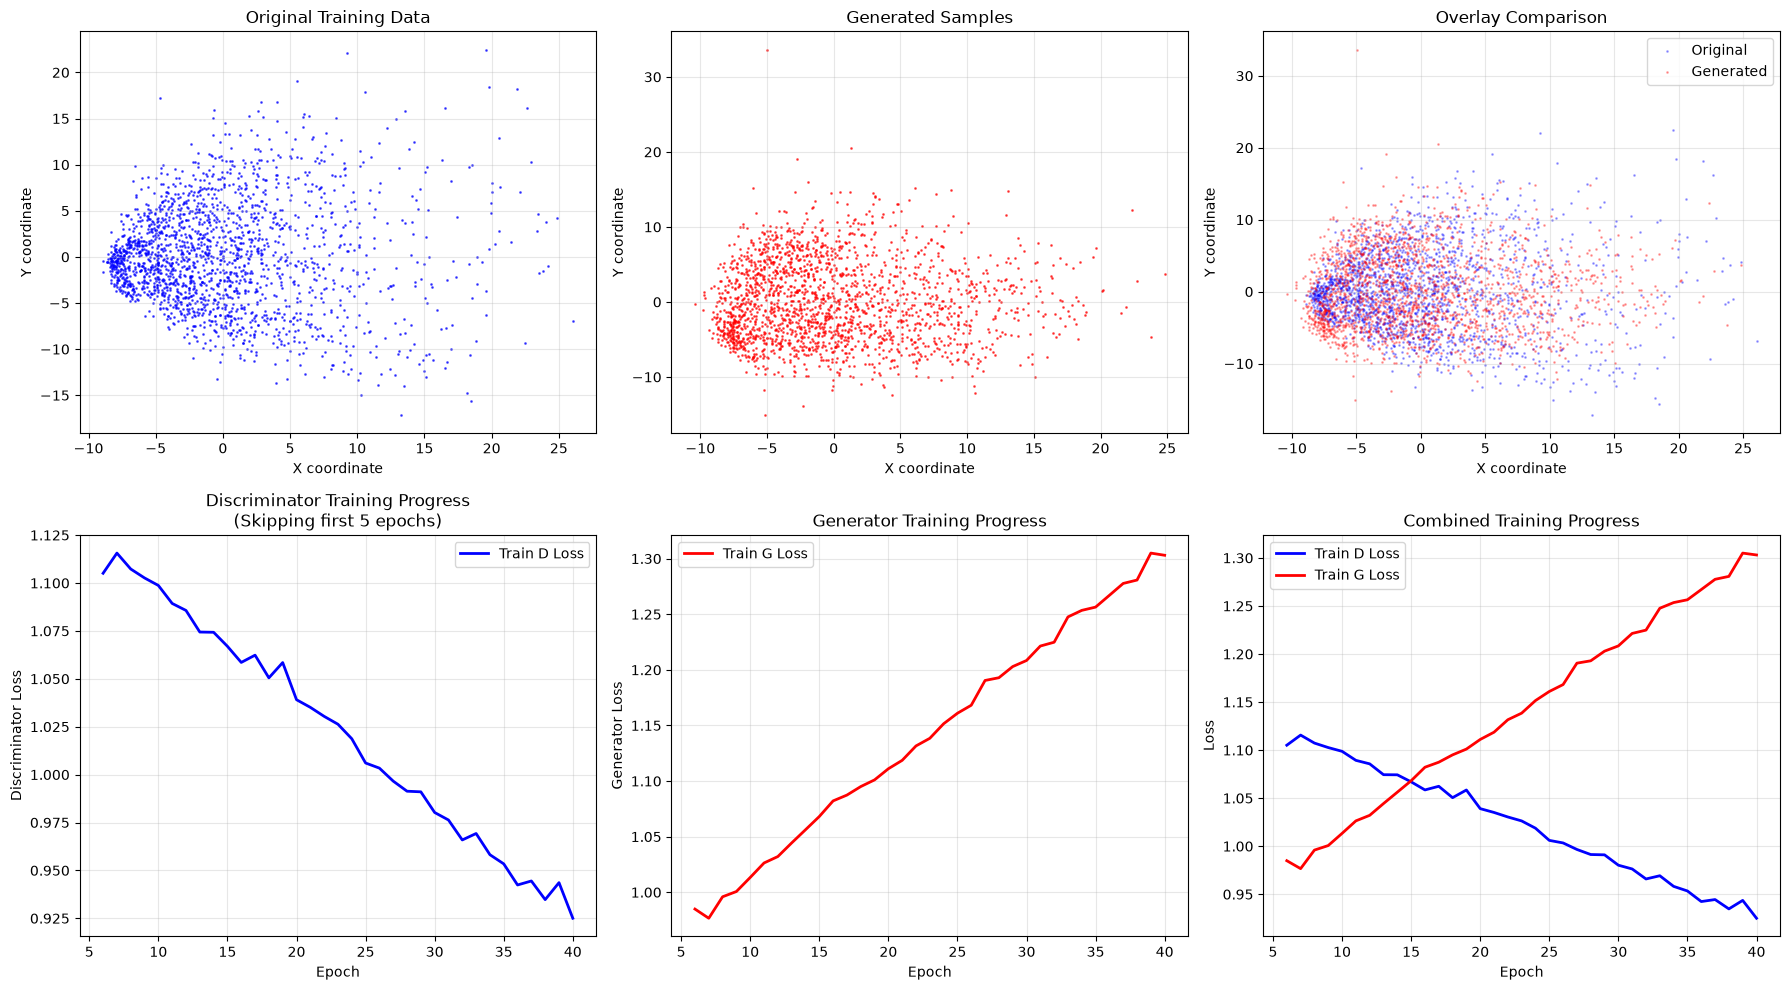

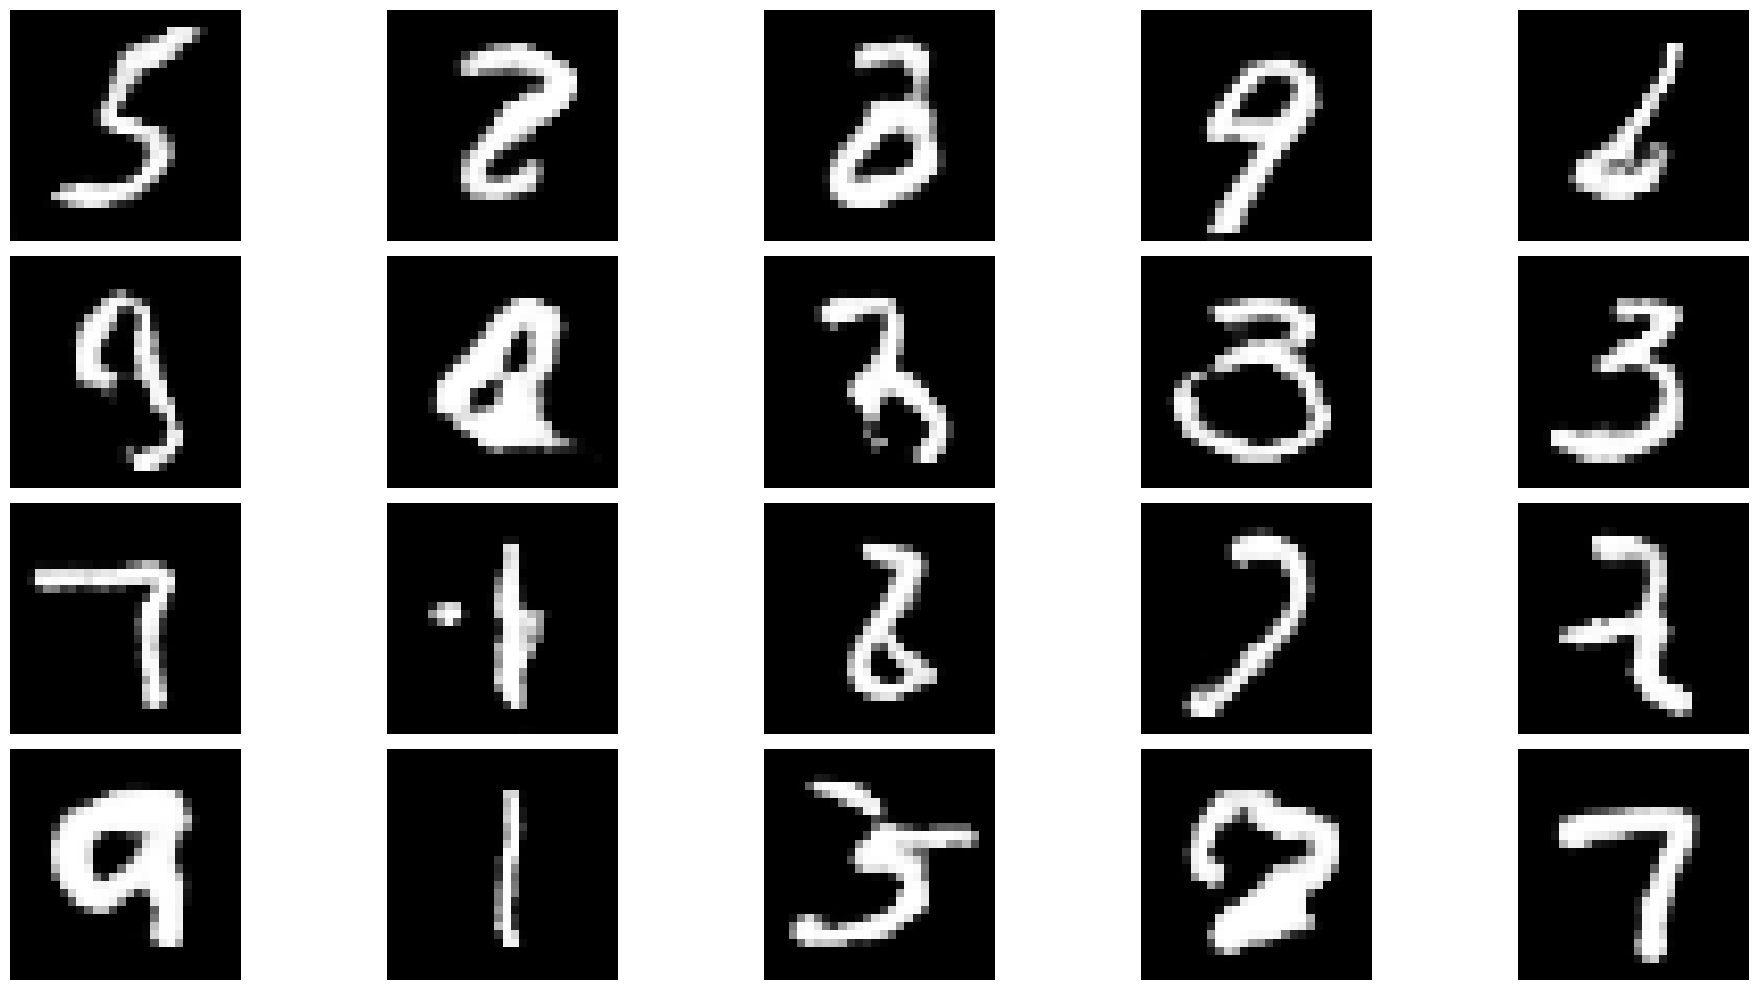

📈 Epoch 40 Summary:
   Train D Loss: 0.9250, Val D Loss: 1.0947
   Train G Loss: 1.3030, Val G Loss: 1.2744

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.887929	G_loss: 1.498399
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.837347	G_loss: 1.309292
Epoch: 41 [12800/60000 (21%)]	D_loss: 1.112480	G_loss: 2.097161
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.911579	G_loss: 1.289076
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.916608	G_loss: 1.379184
Epoch: 41 [32000/60000 (53%)]	D_loss: 1.056383	G_loss: 2.102612
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.855131	G_loss: 1.516856
Epoch: 41 [44800/60000 (75%)]	D_loss: 0.836140	G_loss: 1.444612
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.852873	G_loss: 0.945085
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.792540	G_loss: 1.264816
====> Epoch: 41 Train D_loss: 0.9258, Train G_loss: 1.3111
====> Epoch: 41 Val D_loss: 1.1306, Val G_loss: 0.8215
📈 Epoch 41 Summary:
   Train D Loss: 0.9258, Val D Loss: 1.1306
   Train G Loss: 1.3111

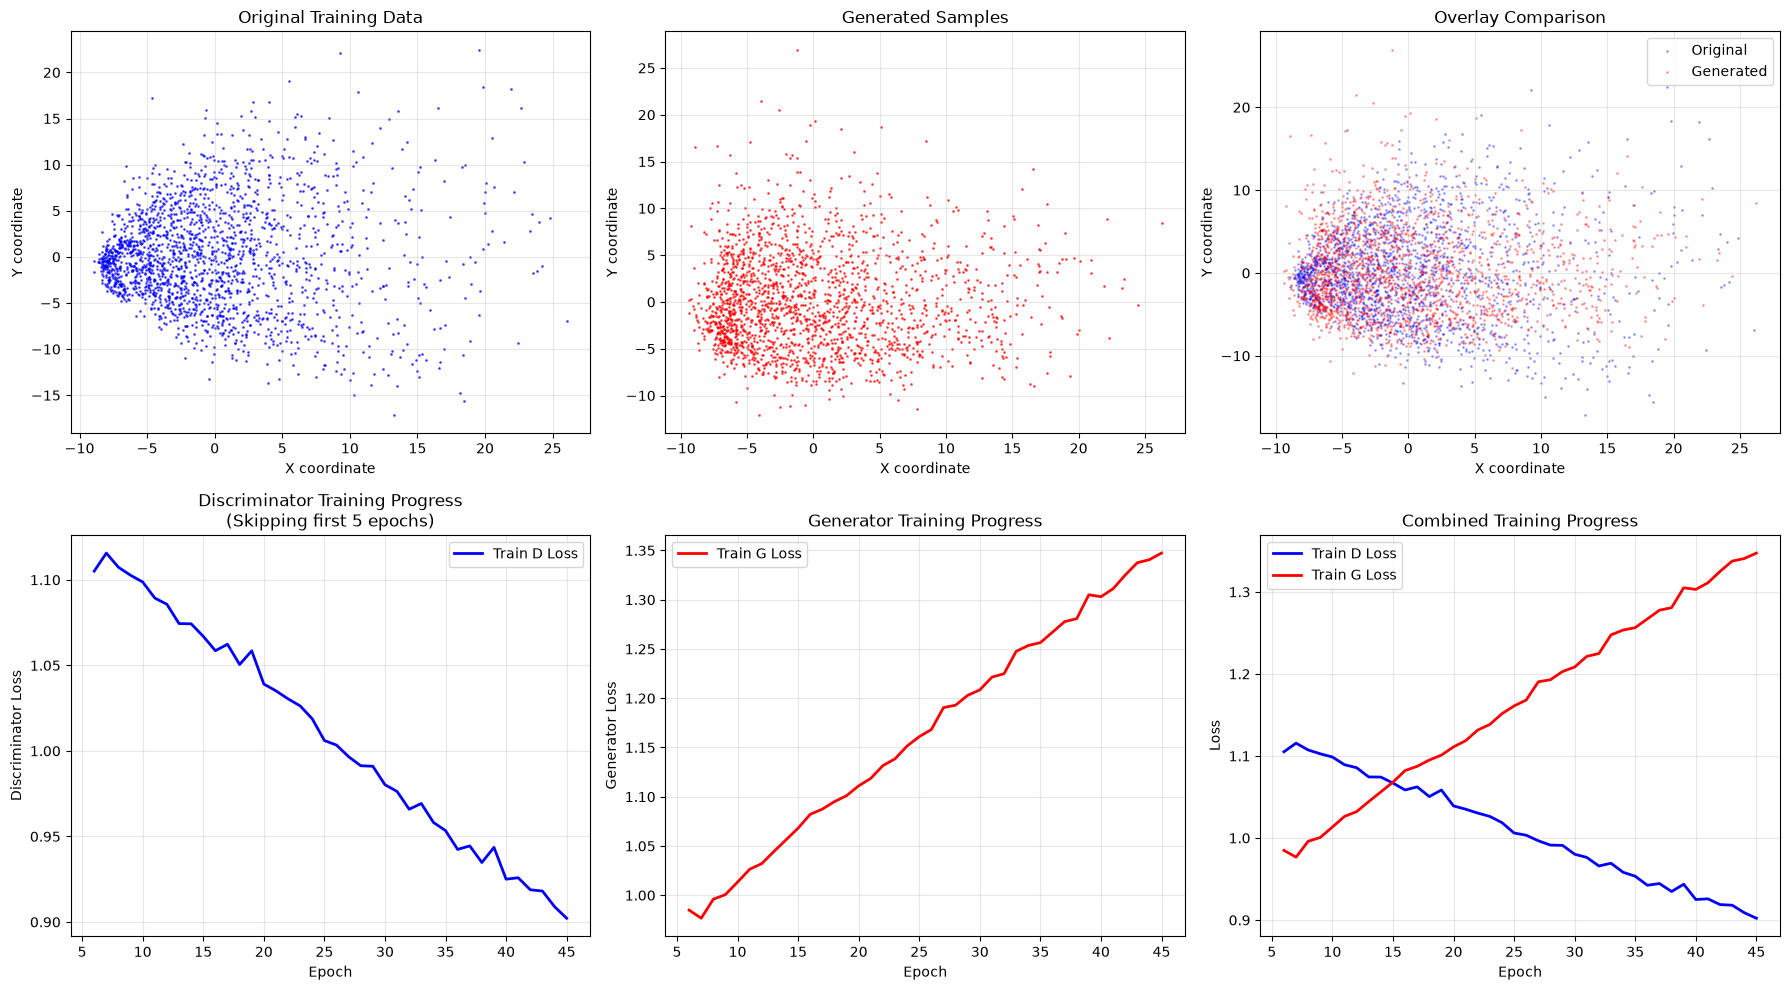

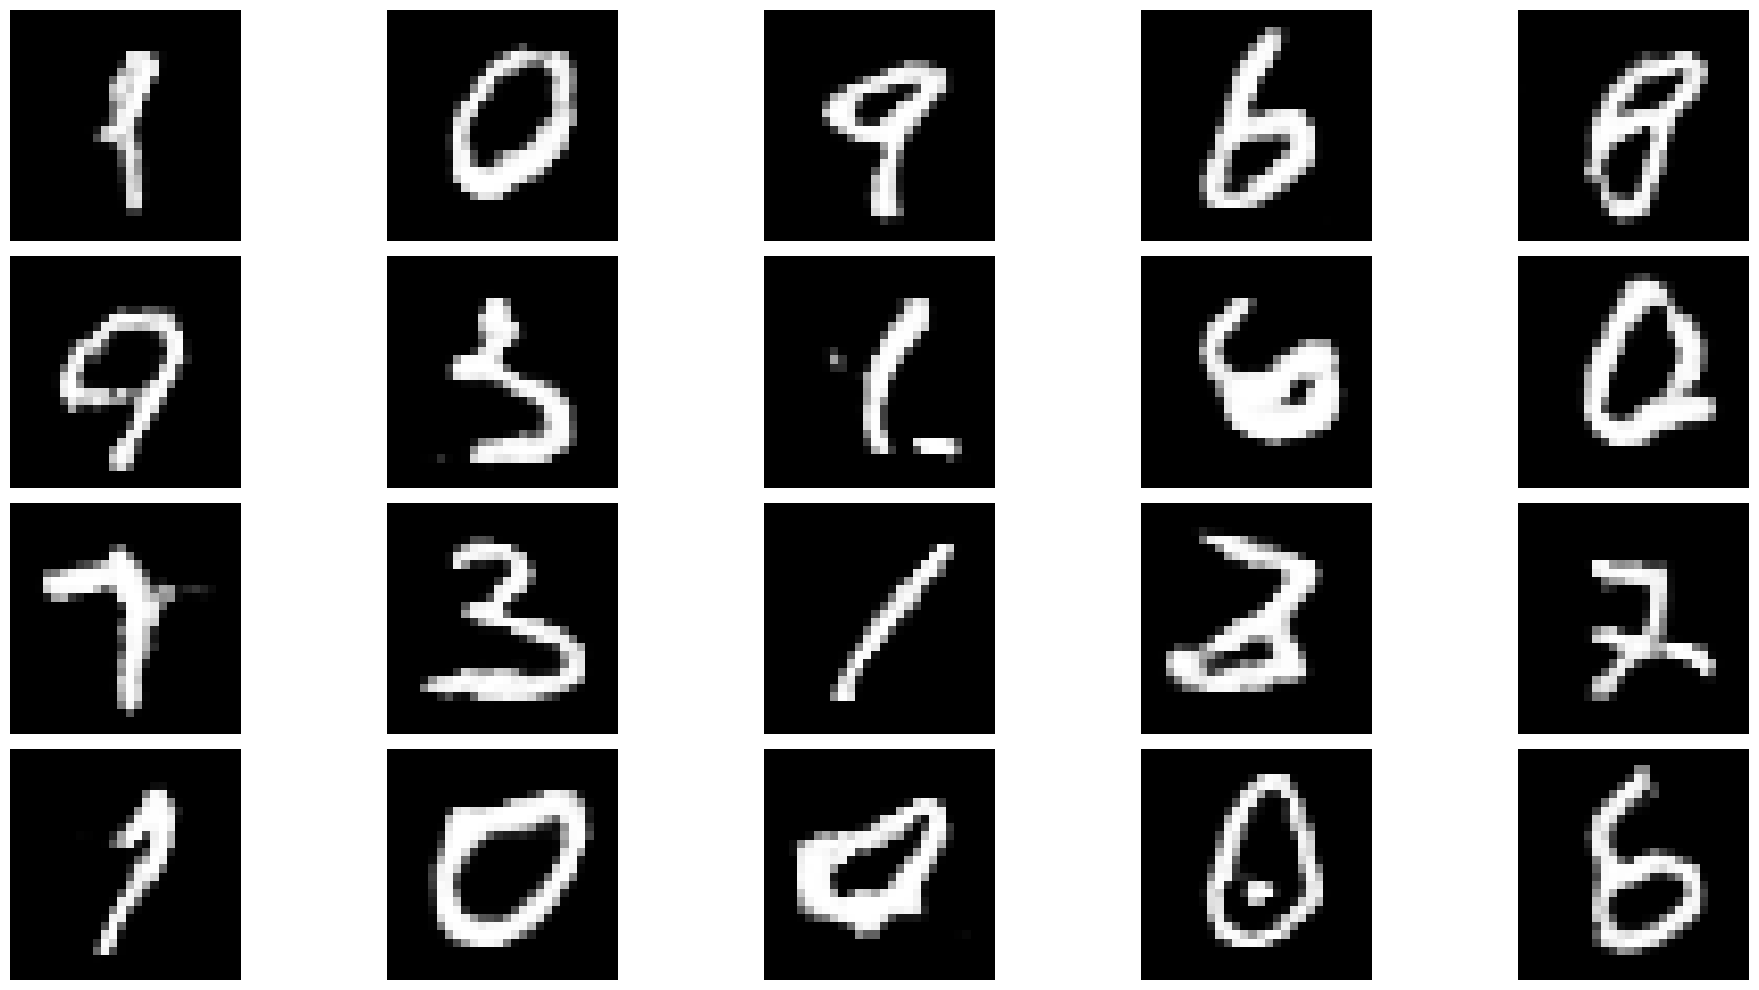

📈 Epoch 45 Summary:
   Train D Loss: 0.9022, Val D Loss: 1.1384
   Train G Loss: 1.3473, Val G Loss: 1.4296

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.794879	G_loss: 1.071153
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.813581	G_loss: 1.169890
Epoch: 46 [12800/60000 (21%)]	D_loss: 0.963961	G_loss: 1.196911
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.813445	G_loss: 1.118725
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.980997	G_loss: 1.867566
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.833210	G_loss: 1.300977
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.844766	G_loss: 1.347103
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.937785	G_loss: 2.099838
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.936445	G_loss: 1.582205
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.889050	G_loss: 1.701239
====> Epoch: 46 Train D_loss: 0.9015, Train G_loss: 1.3645
====> Epoch: 46 Val D_loss: 1.0598, Val G_loss: 1.1797
📈 Epoch 46 Summary:
   Train D Loss: 0.9015, Val D Loss: 1.0598
   Train G Loss: 1.3645

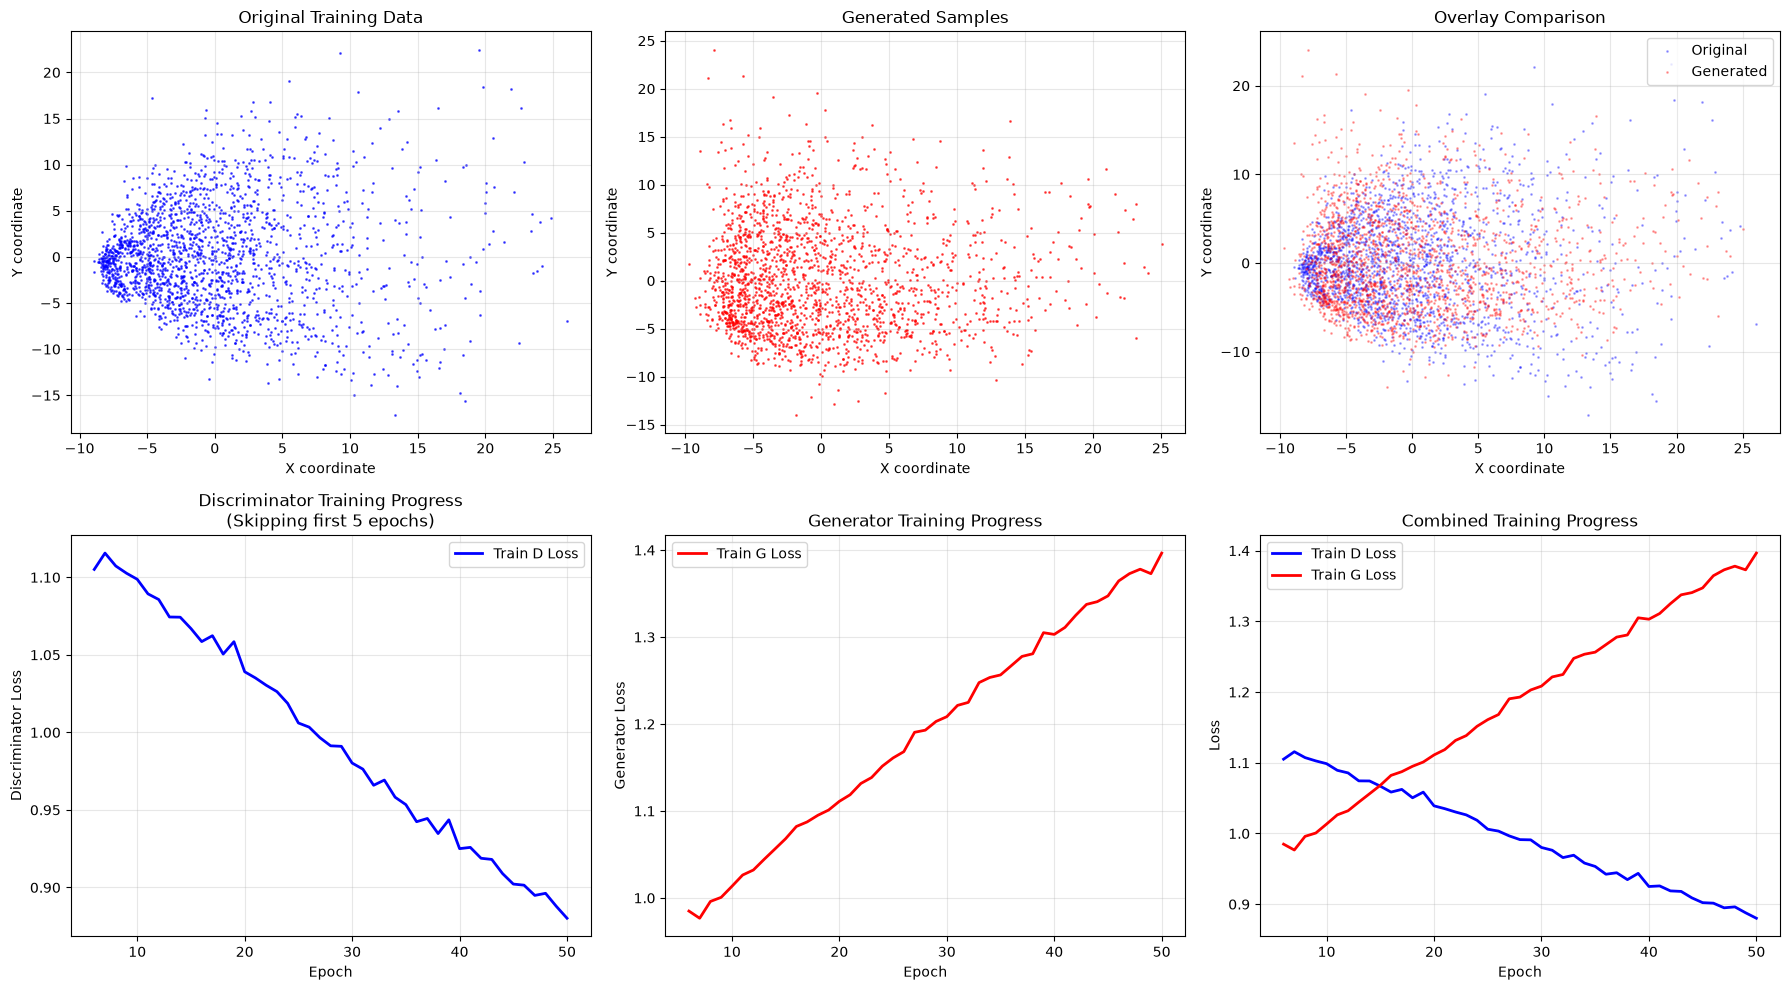

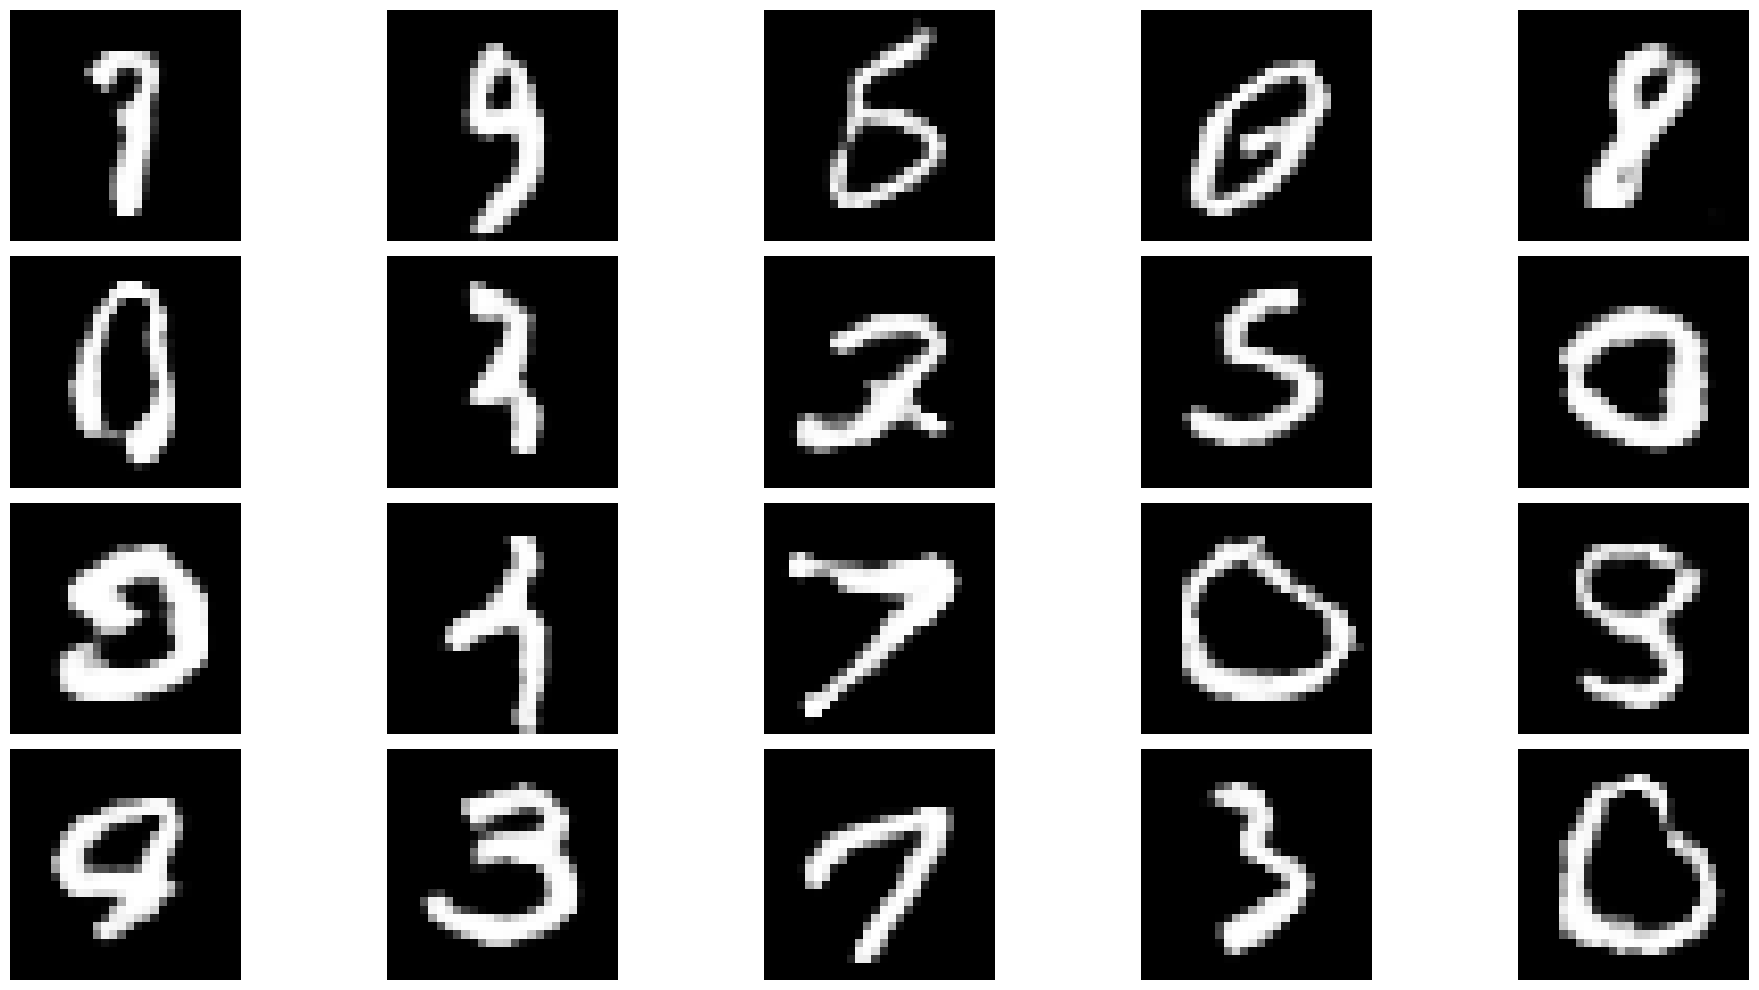

📈 Epoch 50 Summary:
   Train D Loss: 0.8802, Val D Loss: 1.1256
   Train G Loss: 1.3965, Val G Loss: 1.4749

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 0.780887	G_loss: 0.877250
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.811496	G_loss: 2.080817
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.908420	G_loss: 1.383151
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.843455	G_loss: 1.203660
Epoch: 51 [25600/60000 (43%)]	D_loss: 1.042849	G_loss: 2.214871
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.929407	G_loss: 0.987157
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.808271	G_loss: 0.915293
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.894746	G_loss: 0.910166
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.748306	G_loss: 1.173313
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.772840	G_loss: 1.163355
====> Epoch: 51 Train D_loss: 0.8758, Train G_loss: 1.4003
====> Epoch: 51 Val D_loss: 1.5300, Val G_loss: 0.3885
📈 Epoch 51 Summary:
   Train D Loss: 0.8758, Val D Loss: 1.5300
   Train G Loss: 1.4003

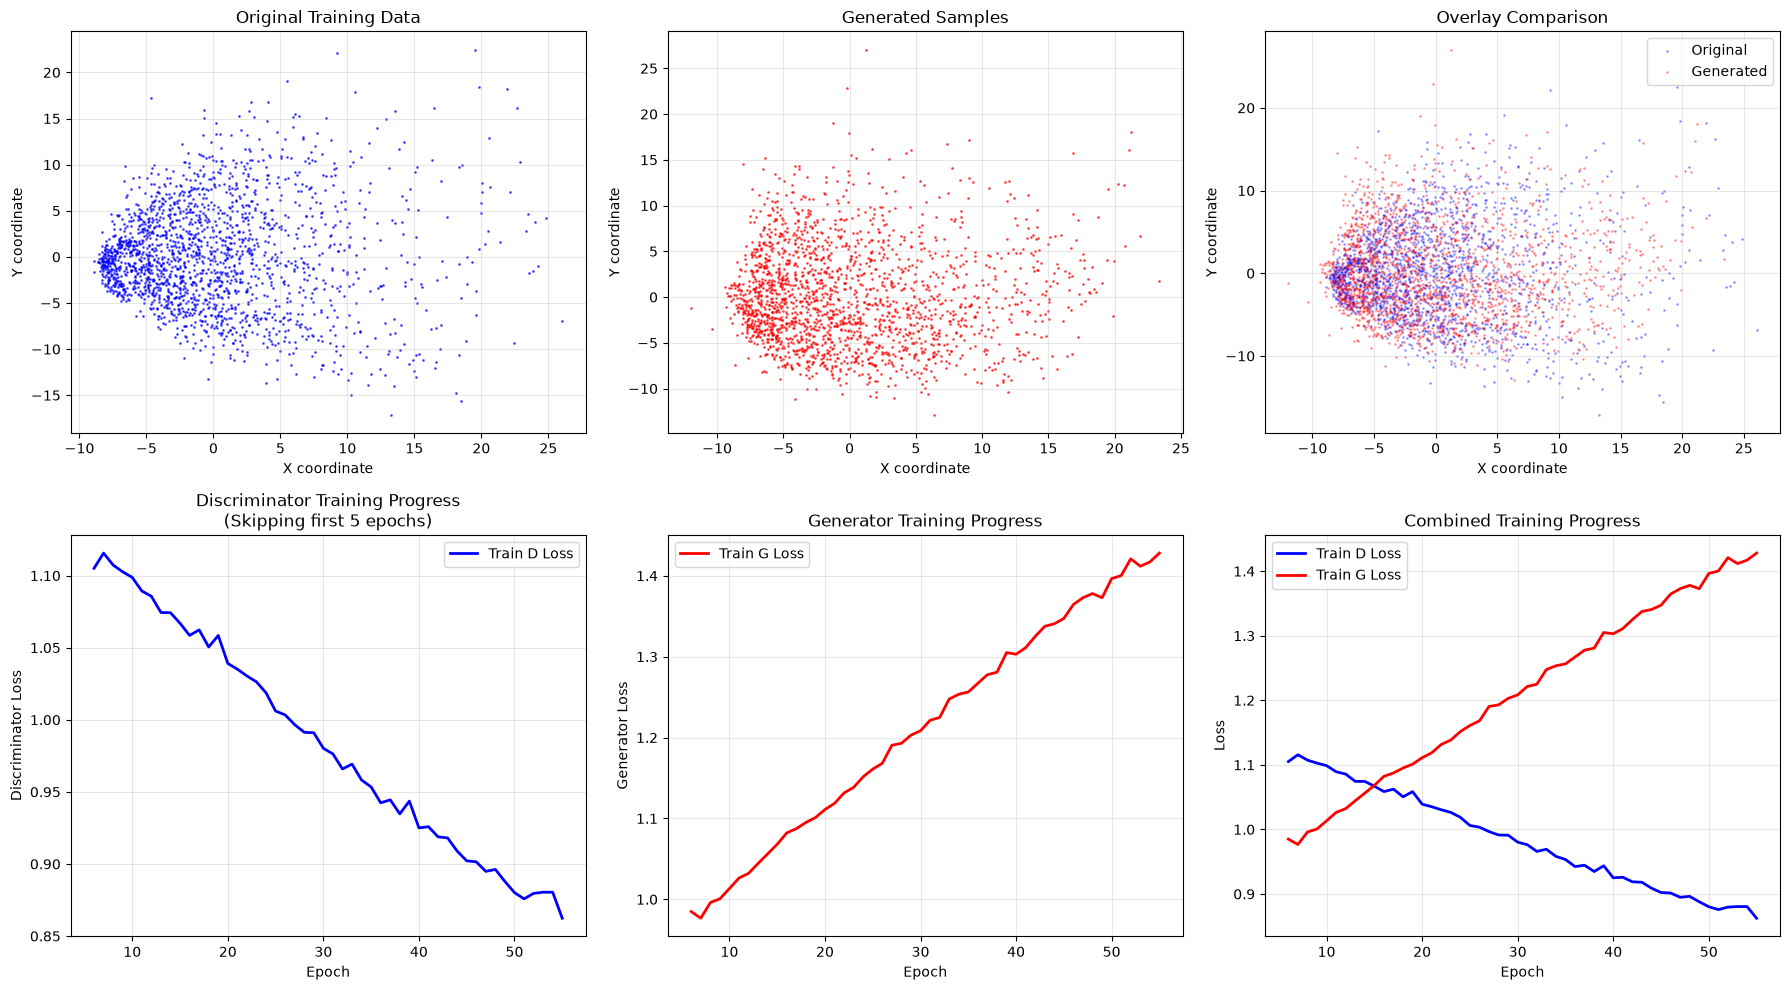

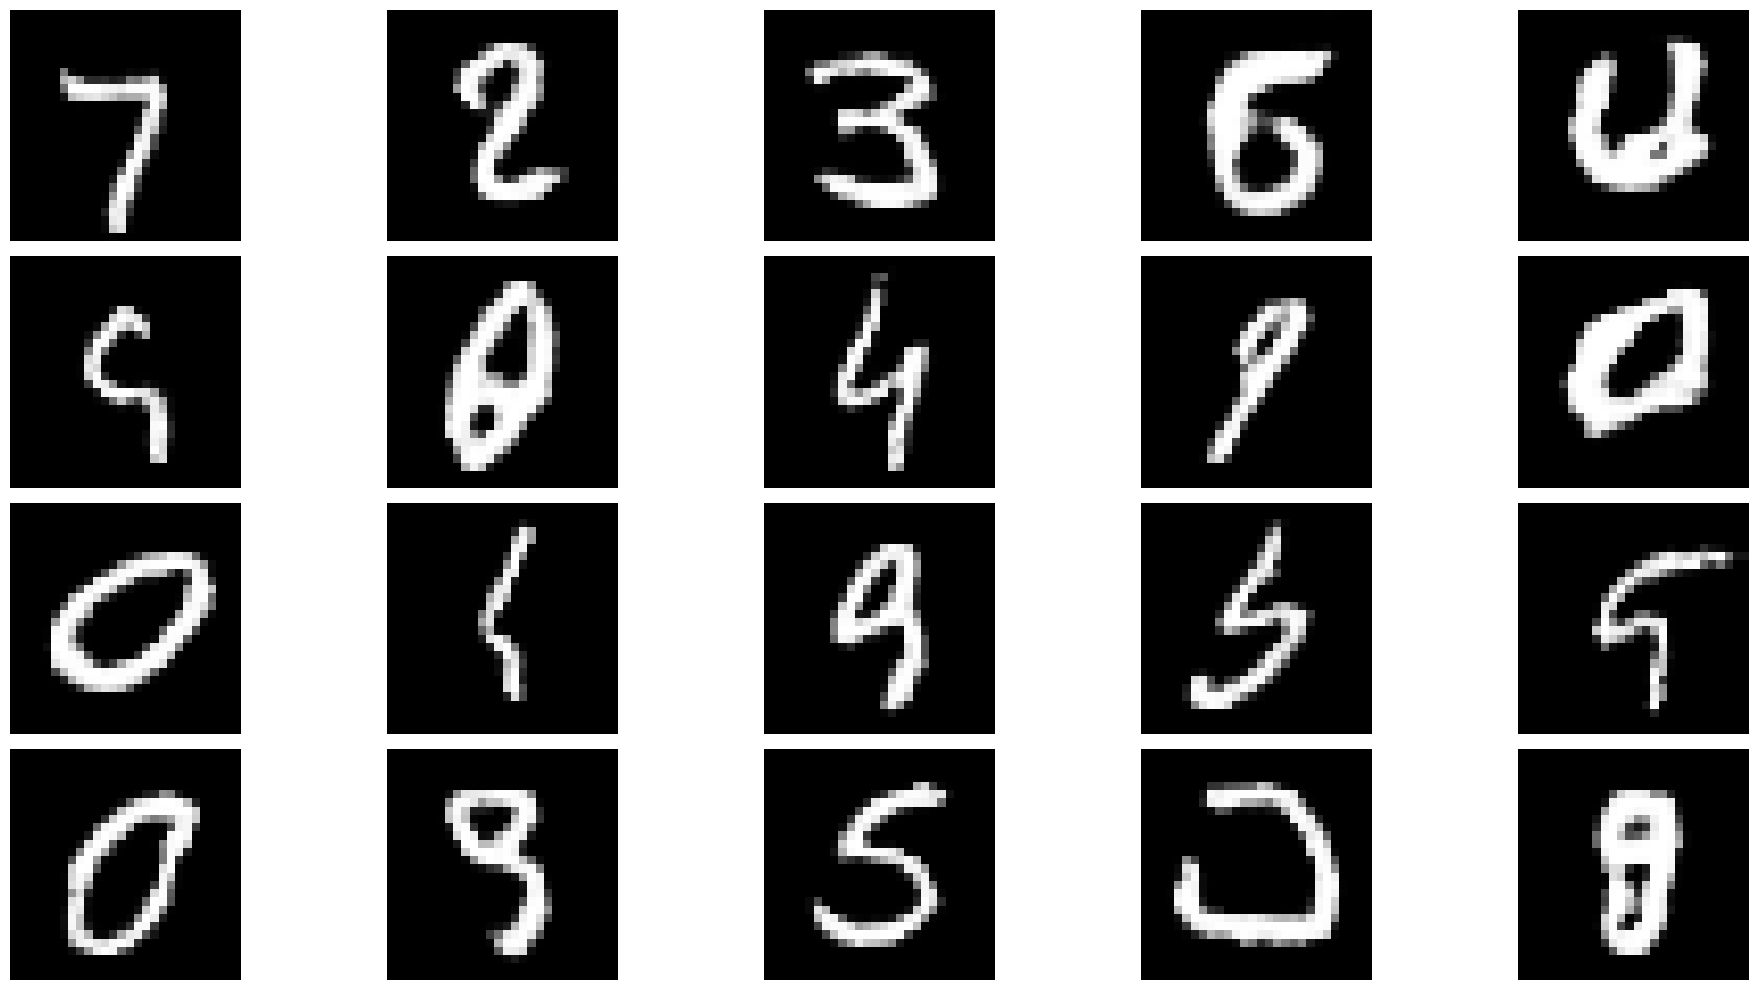

📈 Epoch 55 Summary:
   Train D Loss: 0.8624, Val D Loss: 1.5272
   Train G Loss: 1.4280, Val G Loss: 2.3290

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 1.372009	G_loss: 0.422545
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.749991	G_loss: 1.167689
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.846825	G_loss: 1.076738
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.825654	G_loss: 1.433670
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.791890	G_loss: 0.992757
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.737974	G_loss: 1.459371
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.885576	G_loss: 0.813895
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.881362	G_loss: 1.698105
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.916715	G_loss: 3.060737
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.930031	G_loss: 1.320530
====> Epoch: 56 Train D_loss: 0.8693, Train G_loss: 1.4363
====> Epoch: 56 Val D_loss: 1.0583, Val G_loss: 1.0356
📈 Epoch 56 Summary:
   Train D Loss: 0.8693, Val D Loss: 1.0583
   Train G Loss: 1.4363

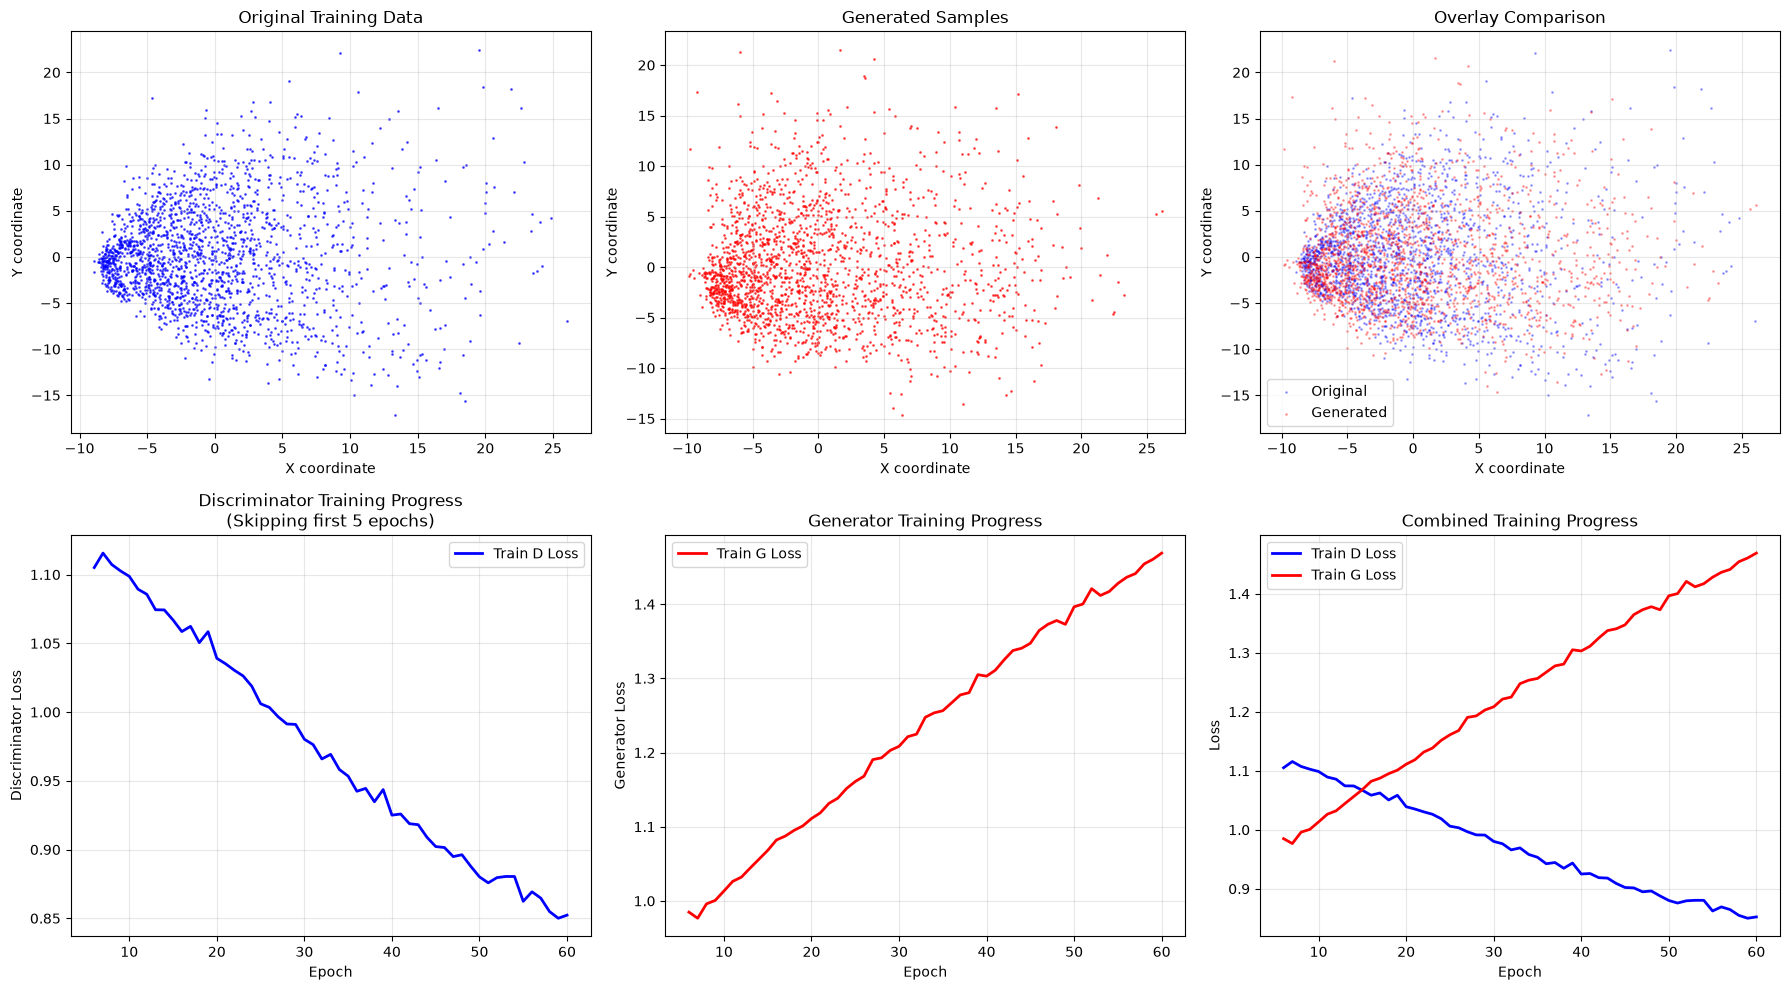

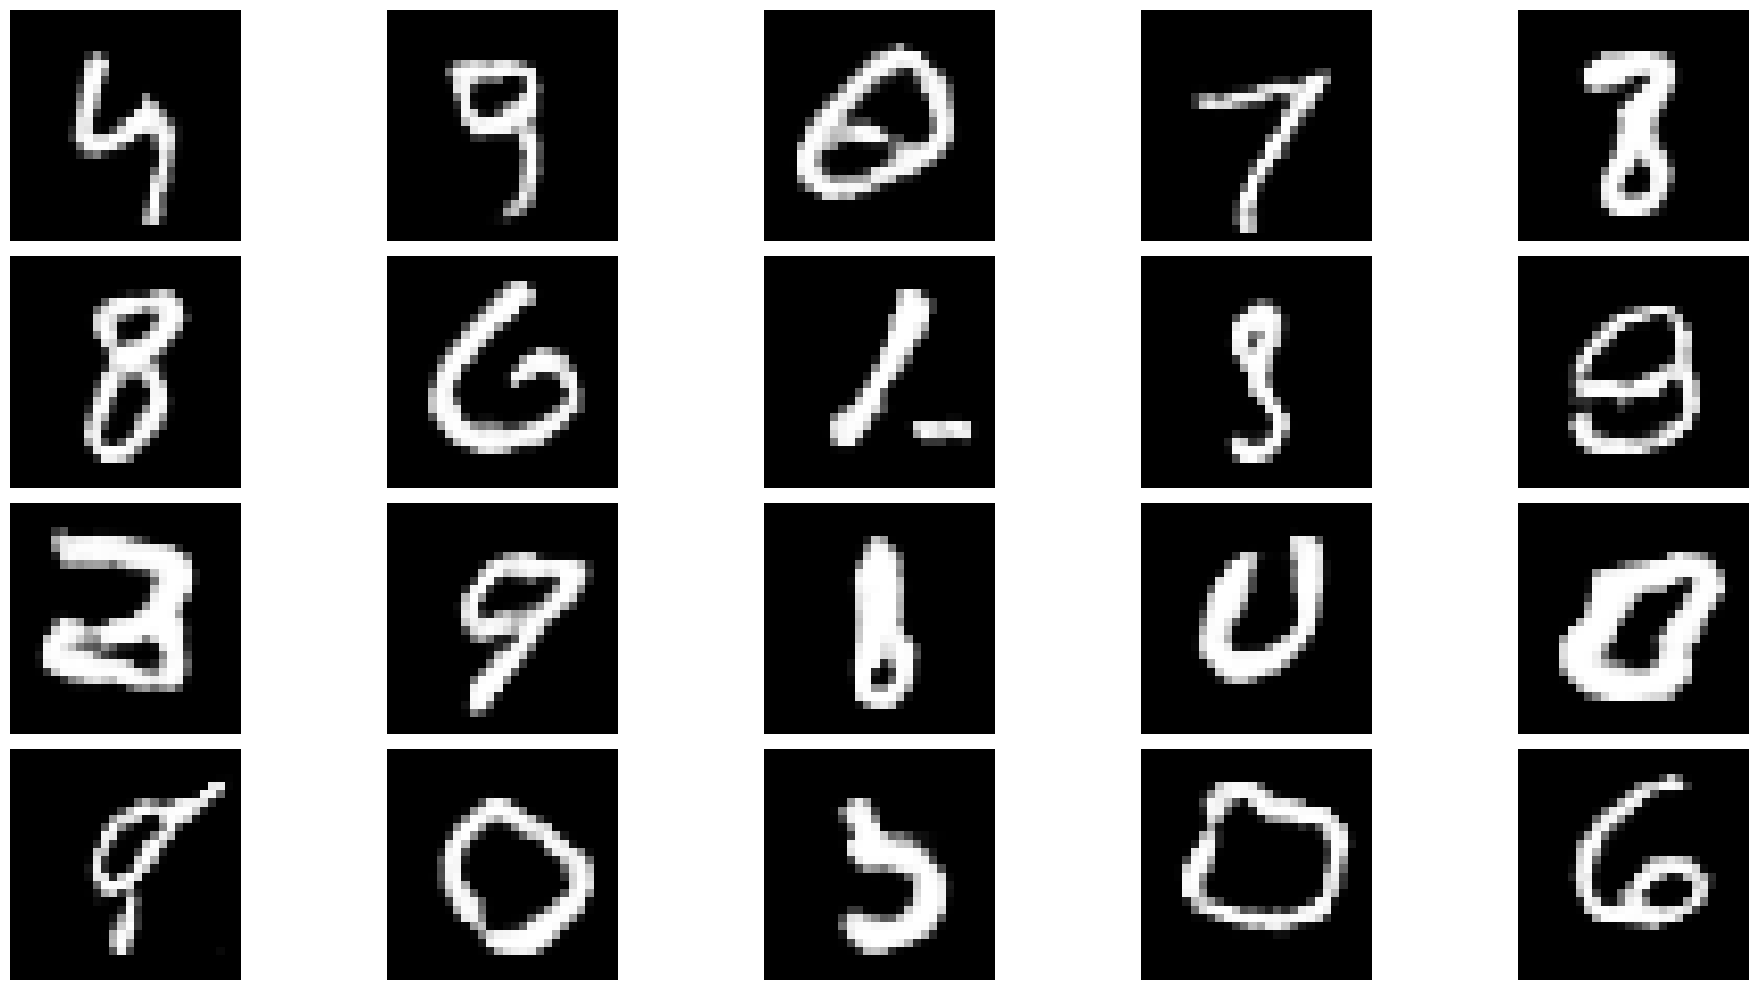

📈 Epoch 60 Summary:
   Train D Loss: 0.8523, Val D Loss: 1.0523
   Train G Loss: 1.4689, Val G Loss: 1.2923

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.857129	G_loss: 1.222612
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.921391	G_loss: 1.756201
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.729977	G_loss: 1.348907
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.844039	G_loss: 0.891904
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.751119	G_loss: 1.247170
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.792615	G_loss: 1.289894
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.872241	G_loss: 1.179227
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.875301	G_loss: 1.987293
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.901893	G_loss: 1.846592
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.841933	G_loss: 1.173302
====> Epoch: 61 Train D_loss: 0.8539, Train G_loss: 1.4766
====> Epoch: 61 Val D_loss: 1.0540, Val G_loss: 1.2309
📈 Epoch 61 Summary:
   Train D Loss: 0.8539, Val D Loss: 1.0540
   Train G Loss: 1.4766

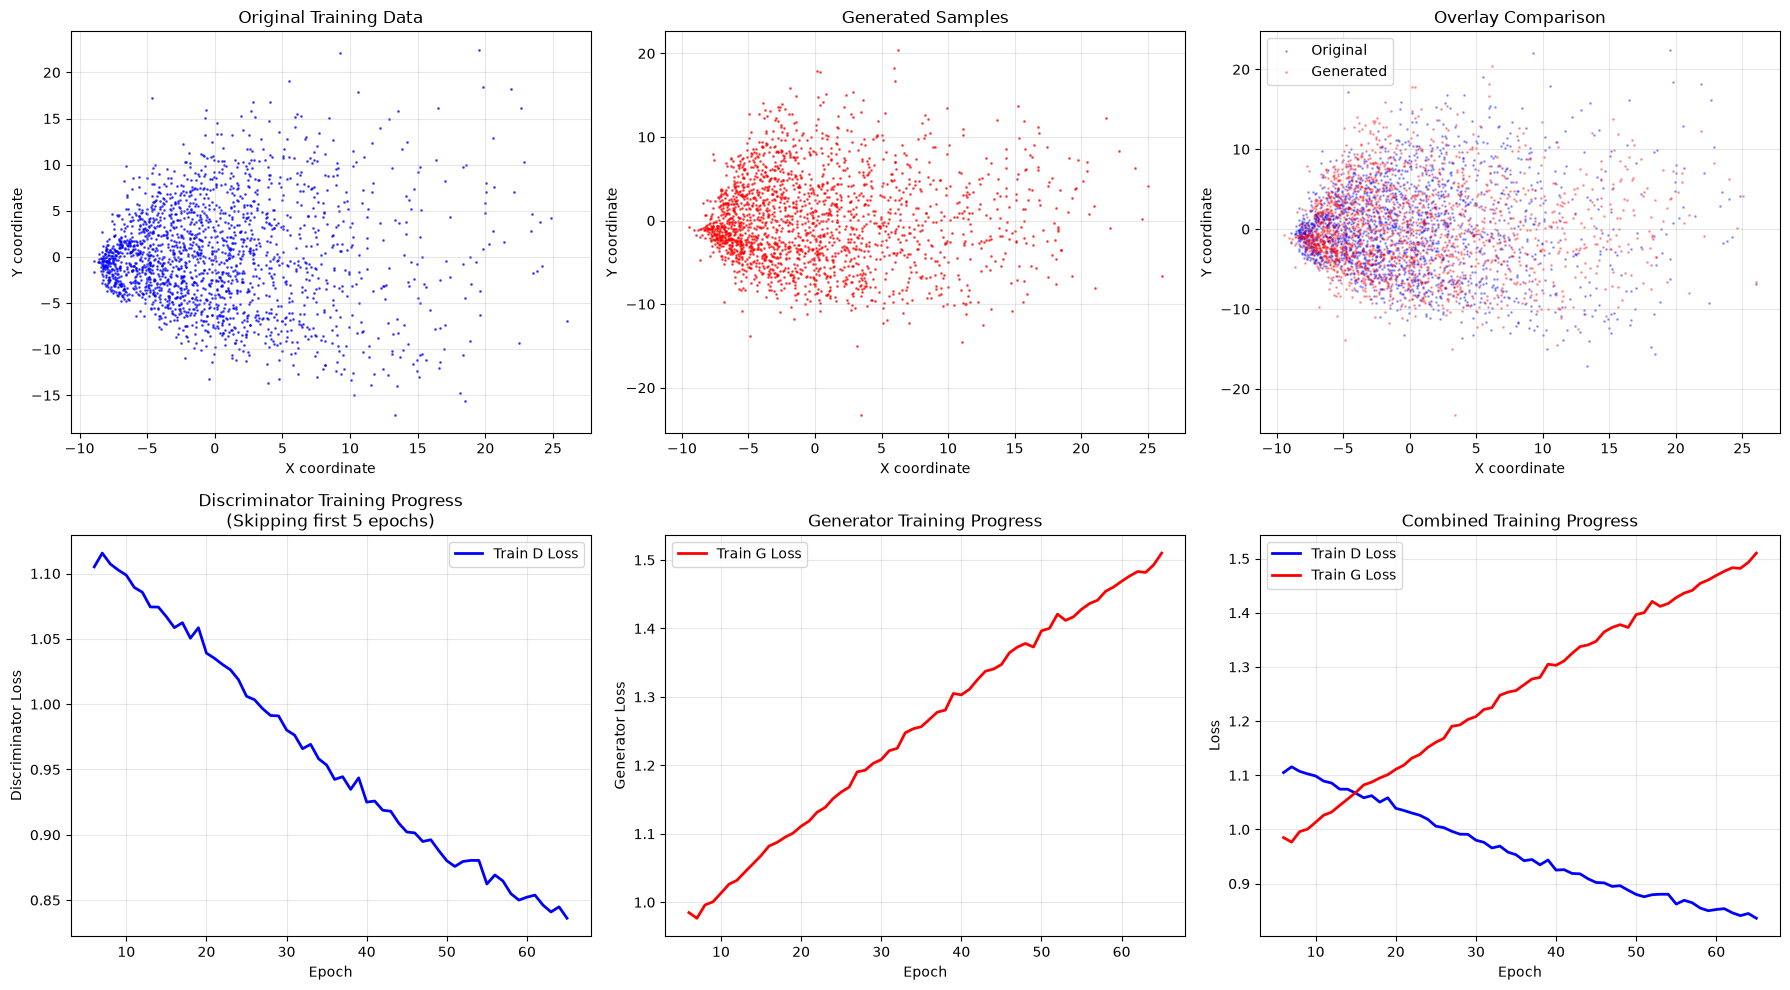

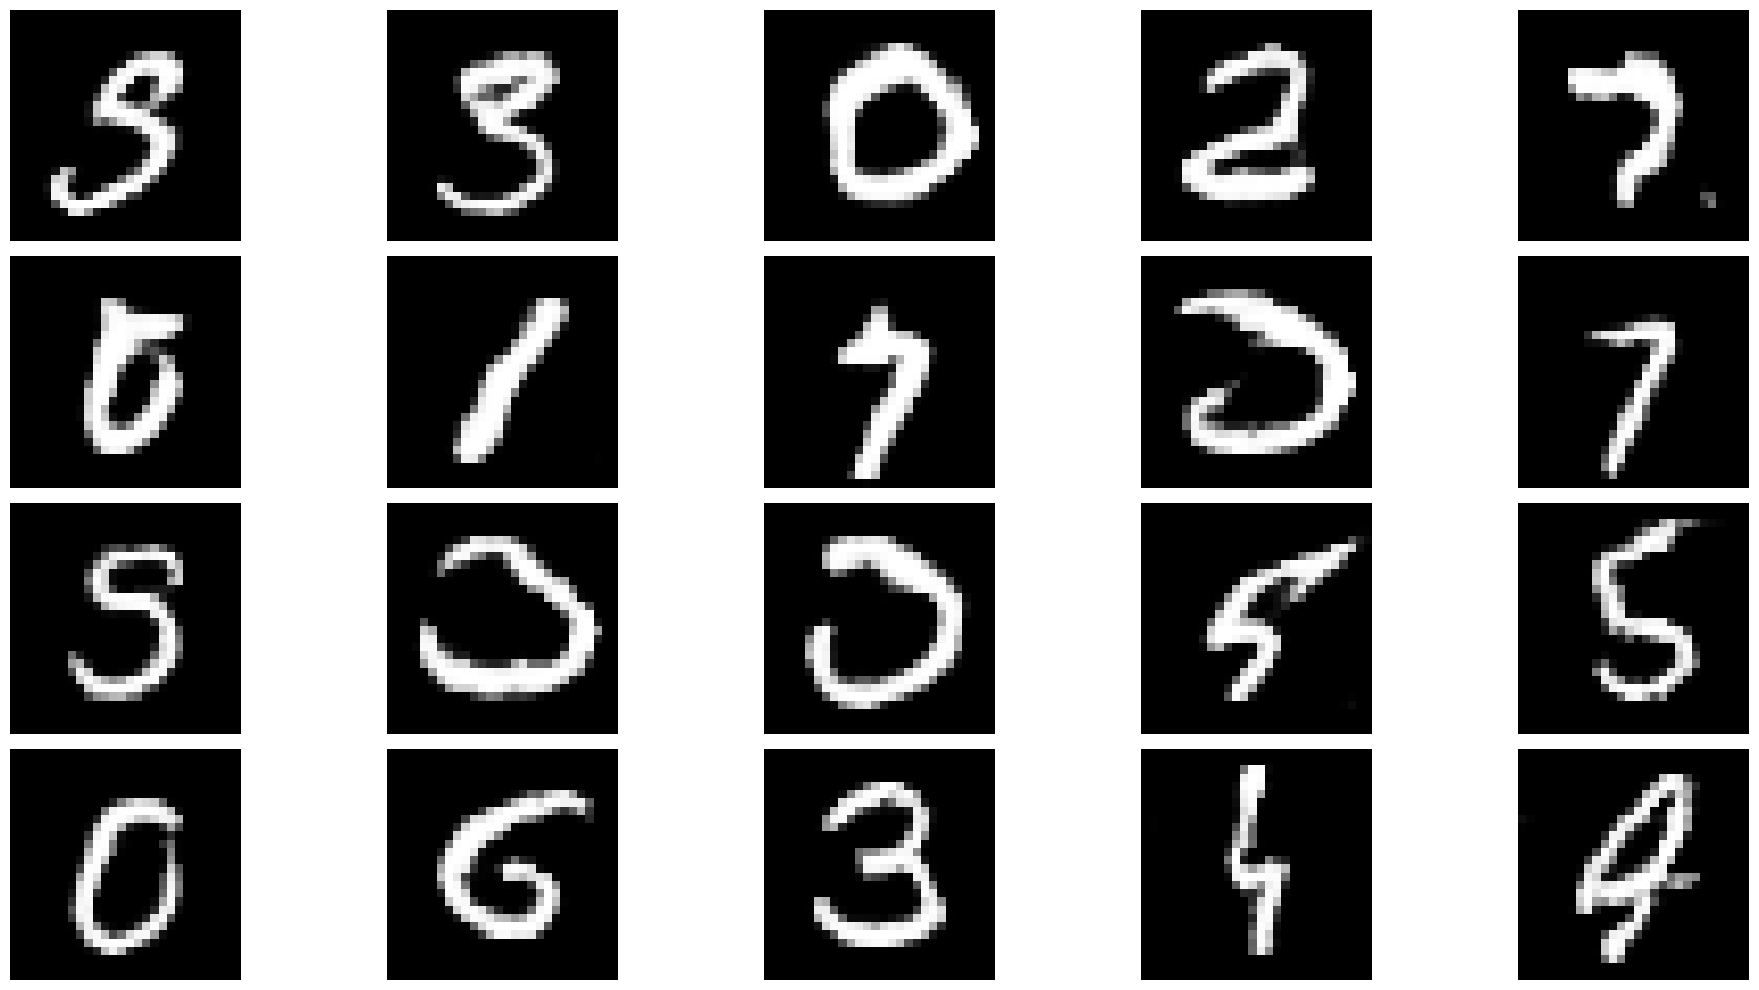

📈 Epoch 65 Summary:
   Train D Loss: 0.8362, Val D Loss: 1.0503
   Train G Loss: 1.5101, Val G Loss: 1.2064

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.600382	G_loss: 1.800205
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.733882	G_loss: 1.251279
Epoch: 66 [12800/60000 (21%)]	D_loss: 1.301091	G_loss: 0.573506
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.808129	G_loss: 2.015477
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.795895	G_loss: 1.673222
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.912300	G_loss: 1.111551
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.749005	G_loss: 0.733475
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.811701	G_loss: 0.853589
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.780478	G_loss: 1.222260
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.934262	G_loss: 1.045147
====> Epoch: 66 Train D_loss: 0.8378, Train G_loss: 1.5124
====> Epoch: 66 Val D_loss: 1.0307, Val G_loss: 1.0565
📈 Epoch 66 Summary:
   Train D Loss: 0.8378, Val D Loss: 1.0307
   Train G Loss: 1.5124

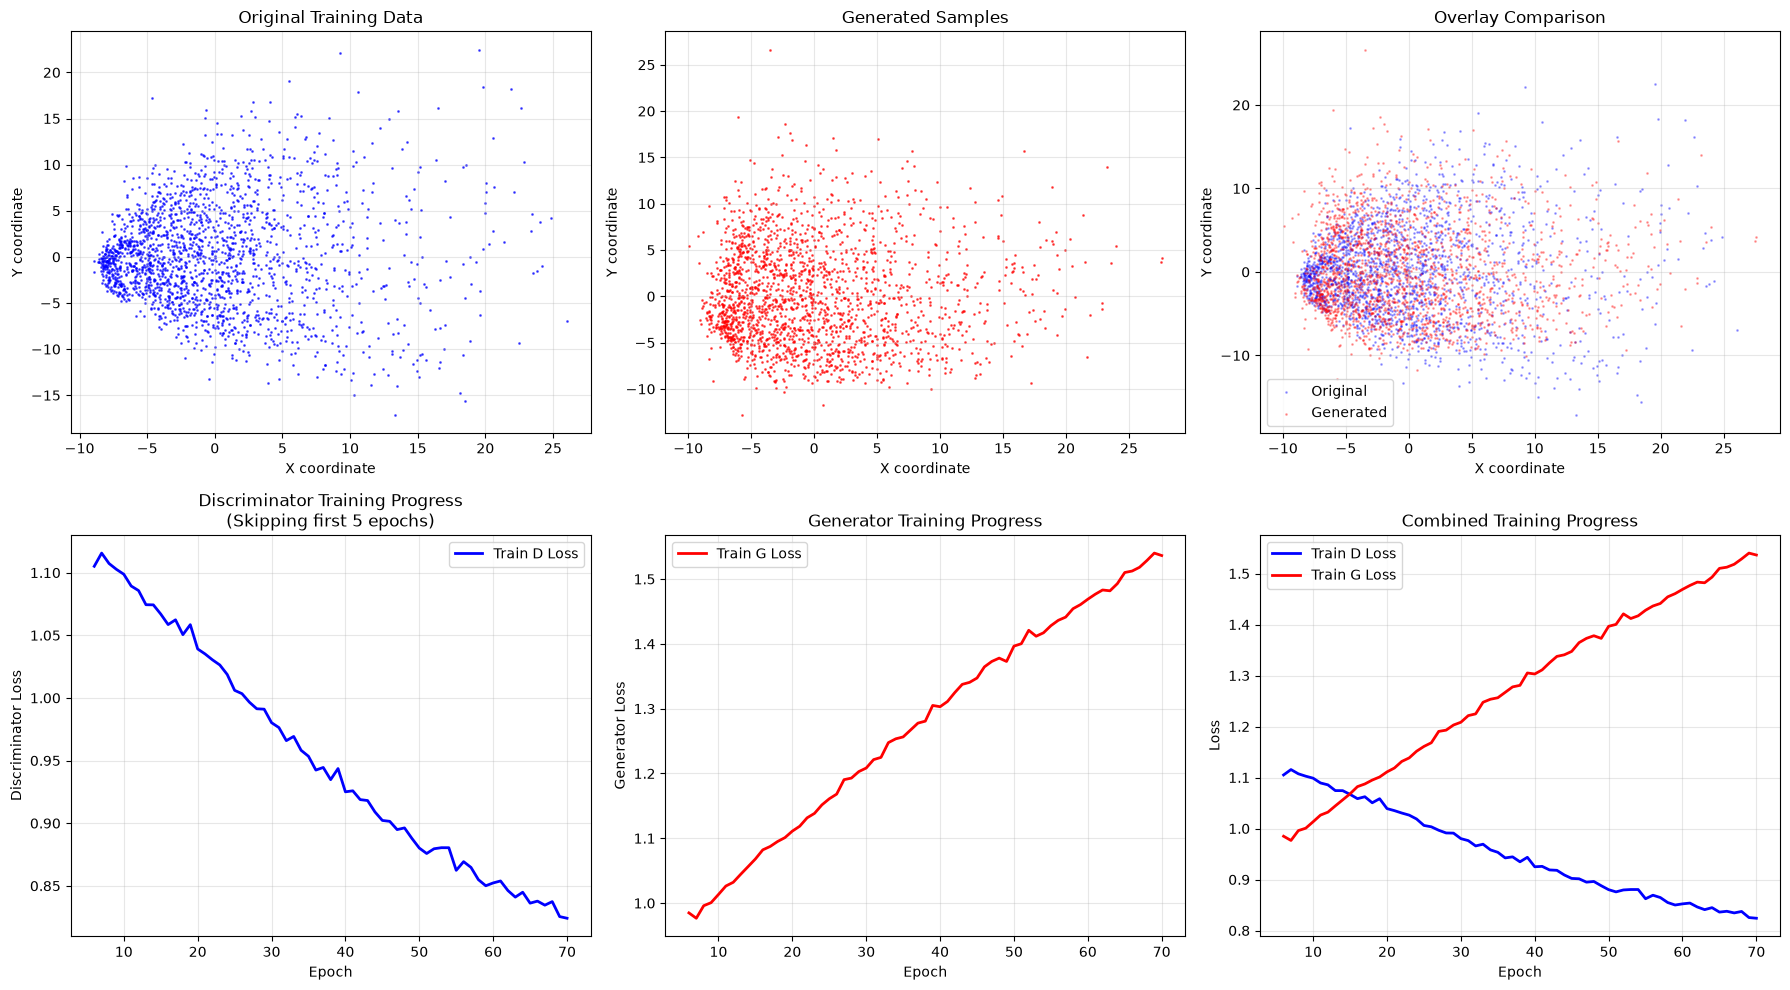

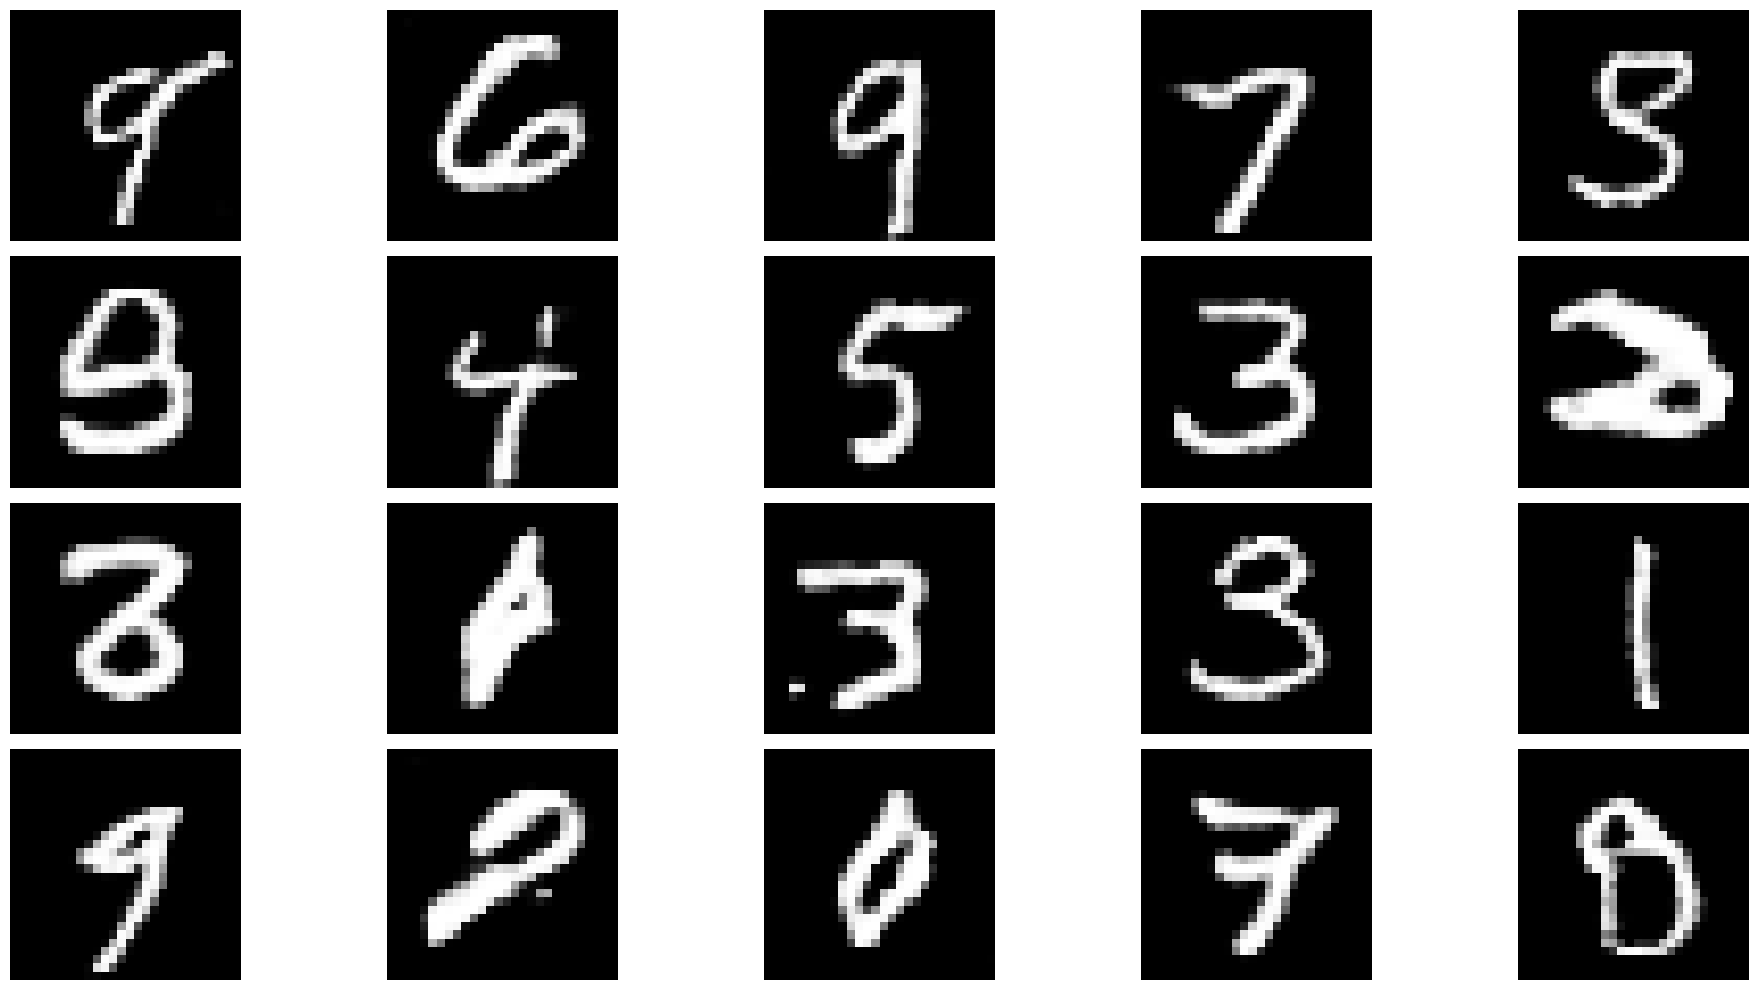

📈 Epoch 70 Summary:
   Train D Loss: 0.8241, Val D Loss: 1.1341
   Train G Loss: 1.5363, Val G Loss: 1.6758

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 0.859499	G_loss: 0.708618
Epoch: 71 [6400/60000 (11%)]	D_loss: 1.001710	G_loss: 1.077056
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.801969	G_loss: 1.829366
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.803912	G_loss: 1.715184
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.861448	G_loss: 1.553097
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.777603	G_loss: 1.196616
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.997651	G_loss: 1.009246
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.733733	G_loss: 1.441079
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.747994	G_loss: 2.242366
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.808603	G_loss: 1.765773
====> Epoch: 71 Train D_loss: 0.8206, Train G_loss: 1.5389
====> Epoch: 71 Val D_loss: 1.0728, Val G_loss: 1.4648
📈 Epoch 71 Summary:
   Train D Loss: 0.8206, Val D Loss: 1.0728
   Train G Loss: 1.5389

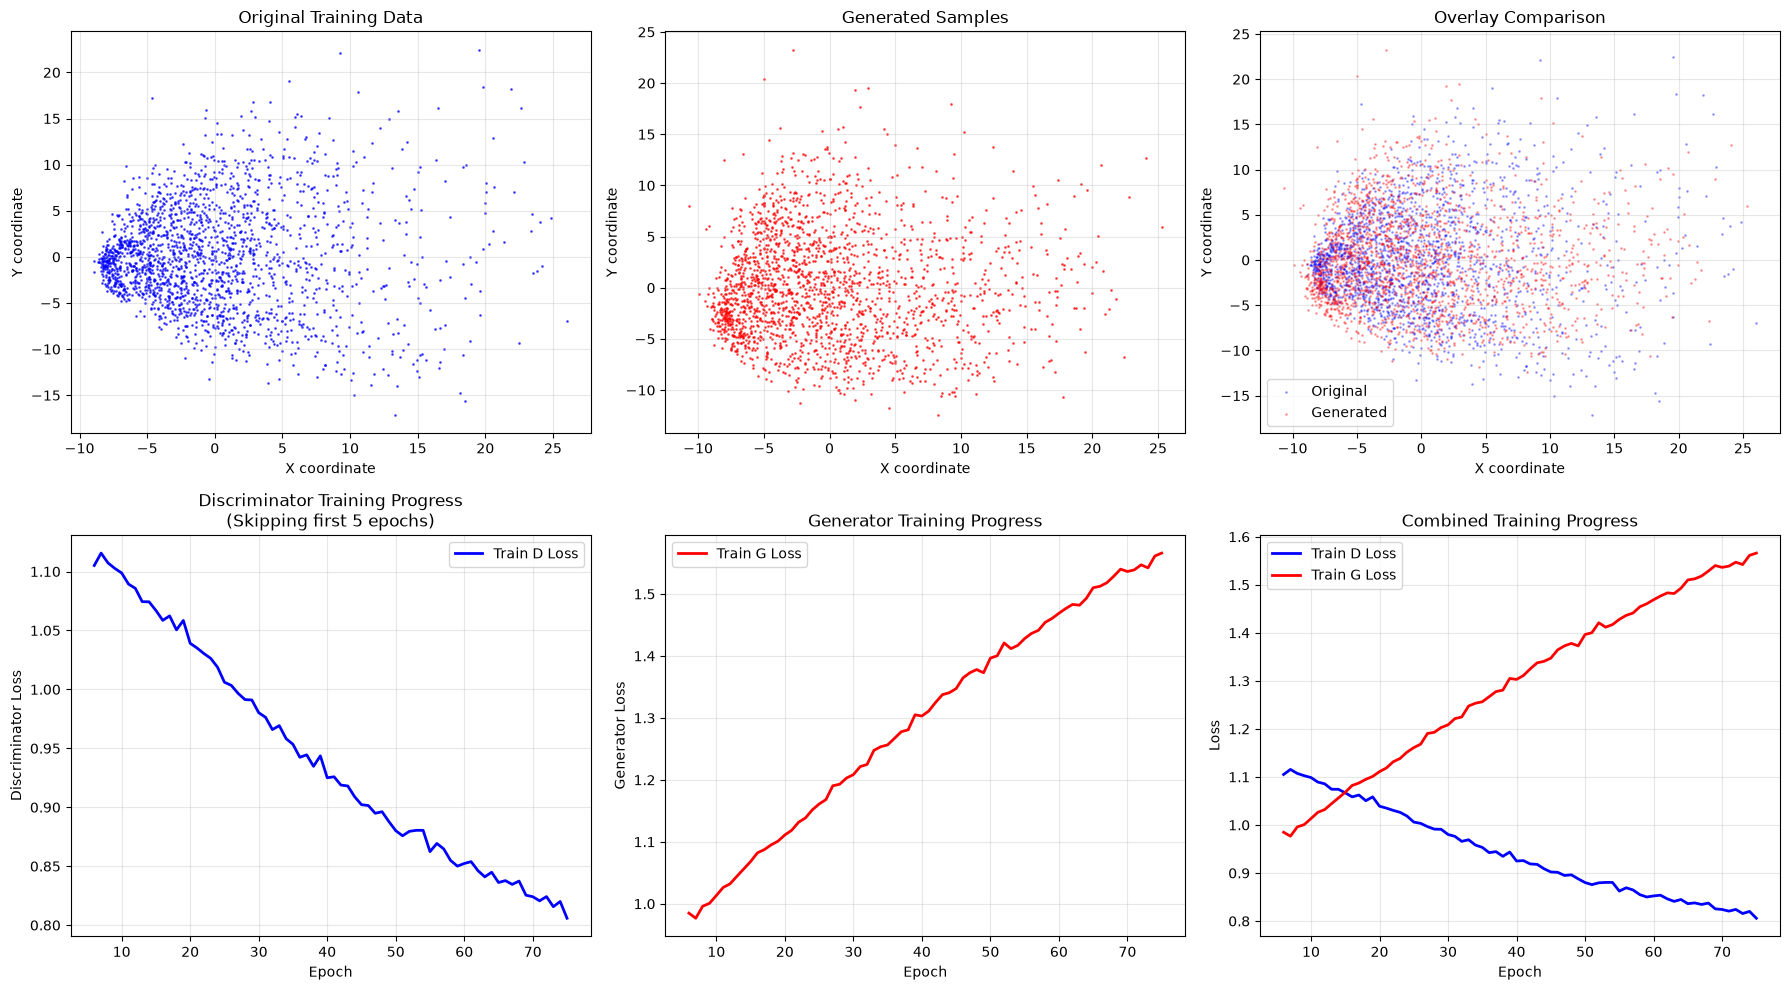

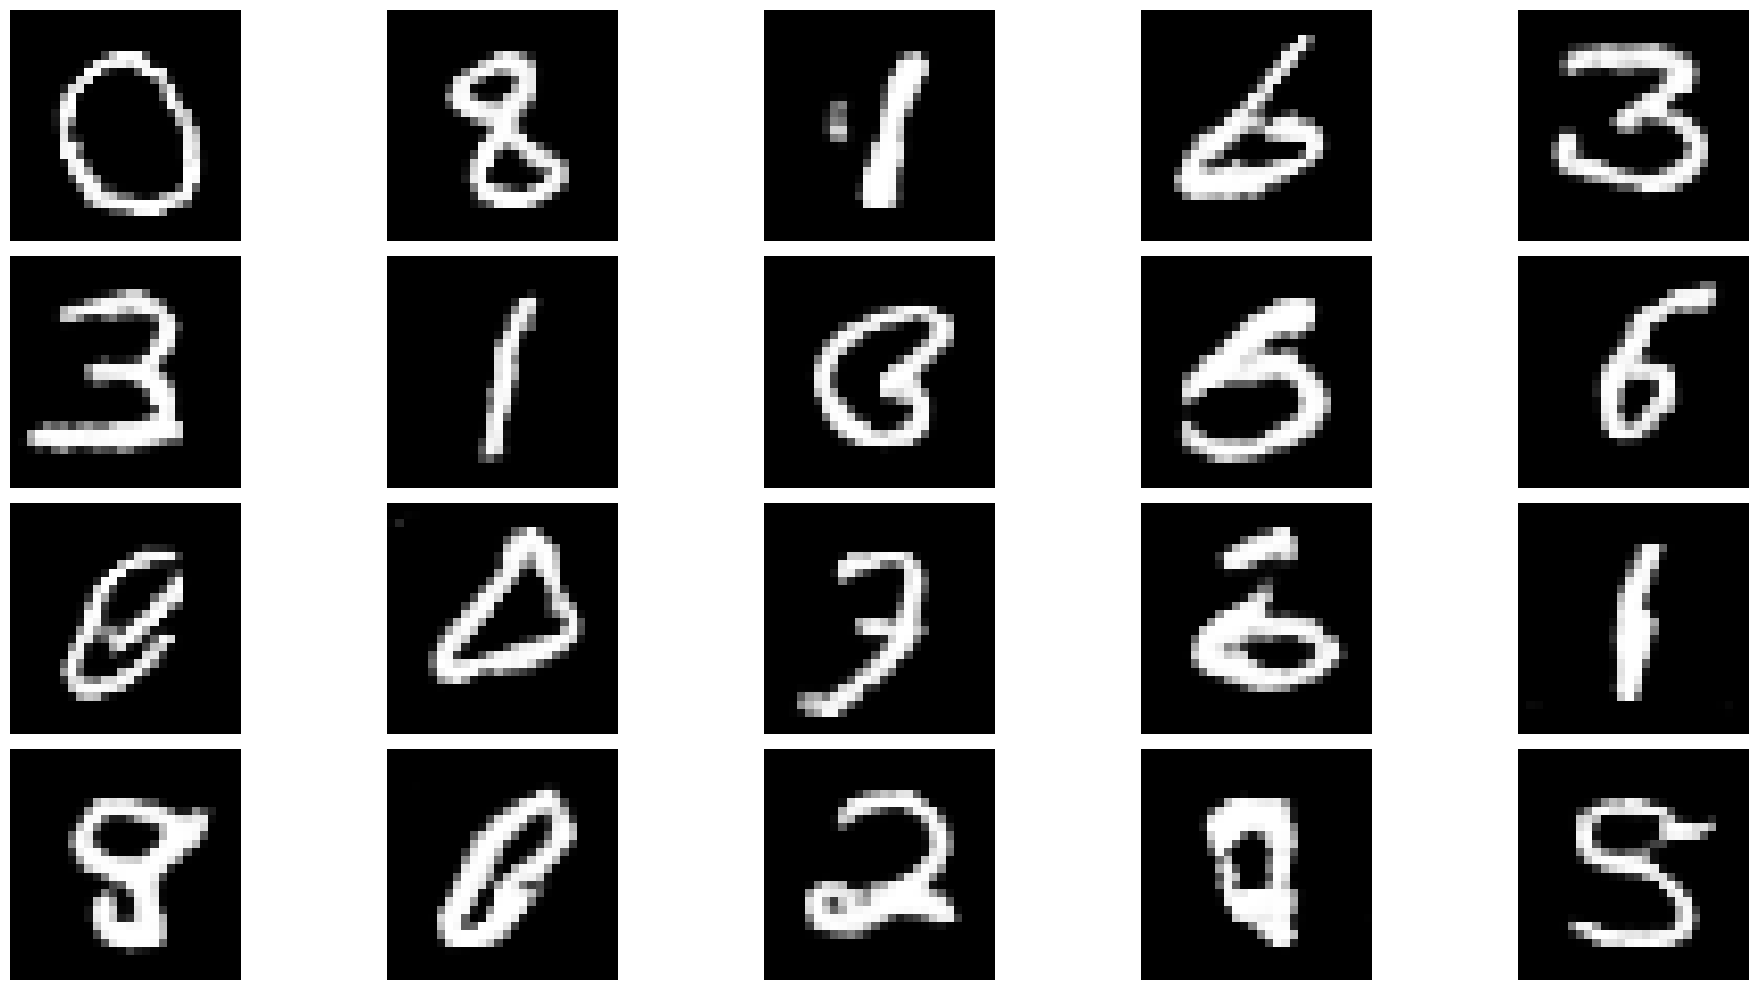

📈 Epoch 75 Summary:
   Train D Loss: 0.8059, Val D Loss: 1.0103
   Train G Loss: 1.5660, Val G Loss: 1.1970

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.802326	G_loss: 1.670757
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.810650	G_loss: 1.429661
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.730295	G_loss: 1.201787
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.817034	G_loss: 0.700793
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.619916	G_loss: 1.282124
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.769586	G_loss: 1.572618
Epoch: 76 [38400/60000 (64%)]	D_loss: 0.800613	G_loss: 1.122227
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.786373	G_loss: 1.429134
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.689135	G_loss: 2.076777
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.823020	G_loss: 1.055485
====> Epoch: 76 Train D_loss: 0.8094, Train G_loss: 1.5634
====> Epoch: 76 Val D_loss: 1.1386, Val G_loss: 1.6682
📈 Epoch 76 Summary:
   Train D Loss: 0.8094, Val D Loss: 1.1386
   Train G Loss: 1.5634

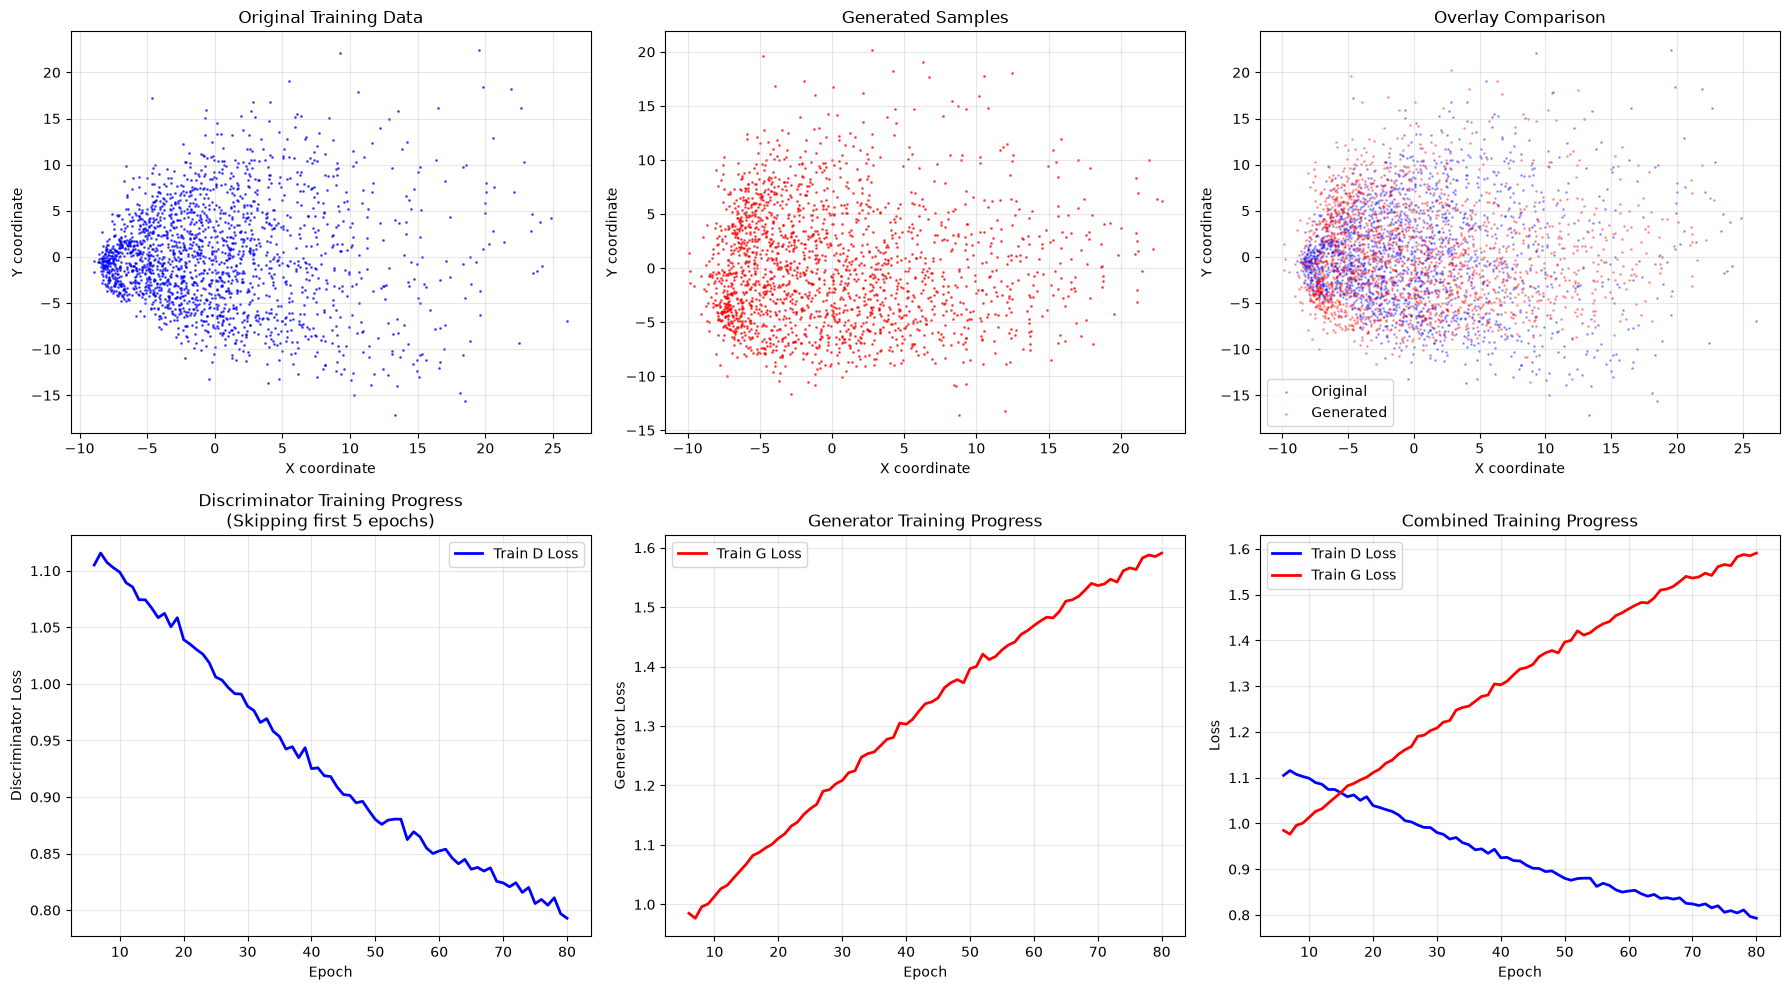

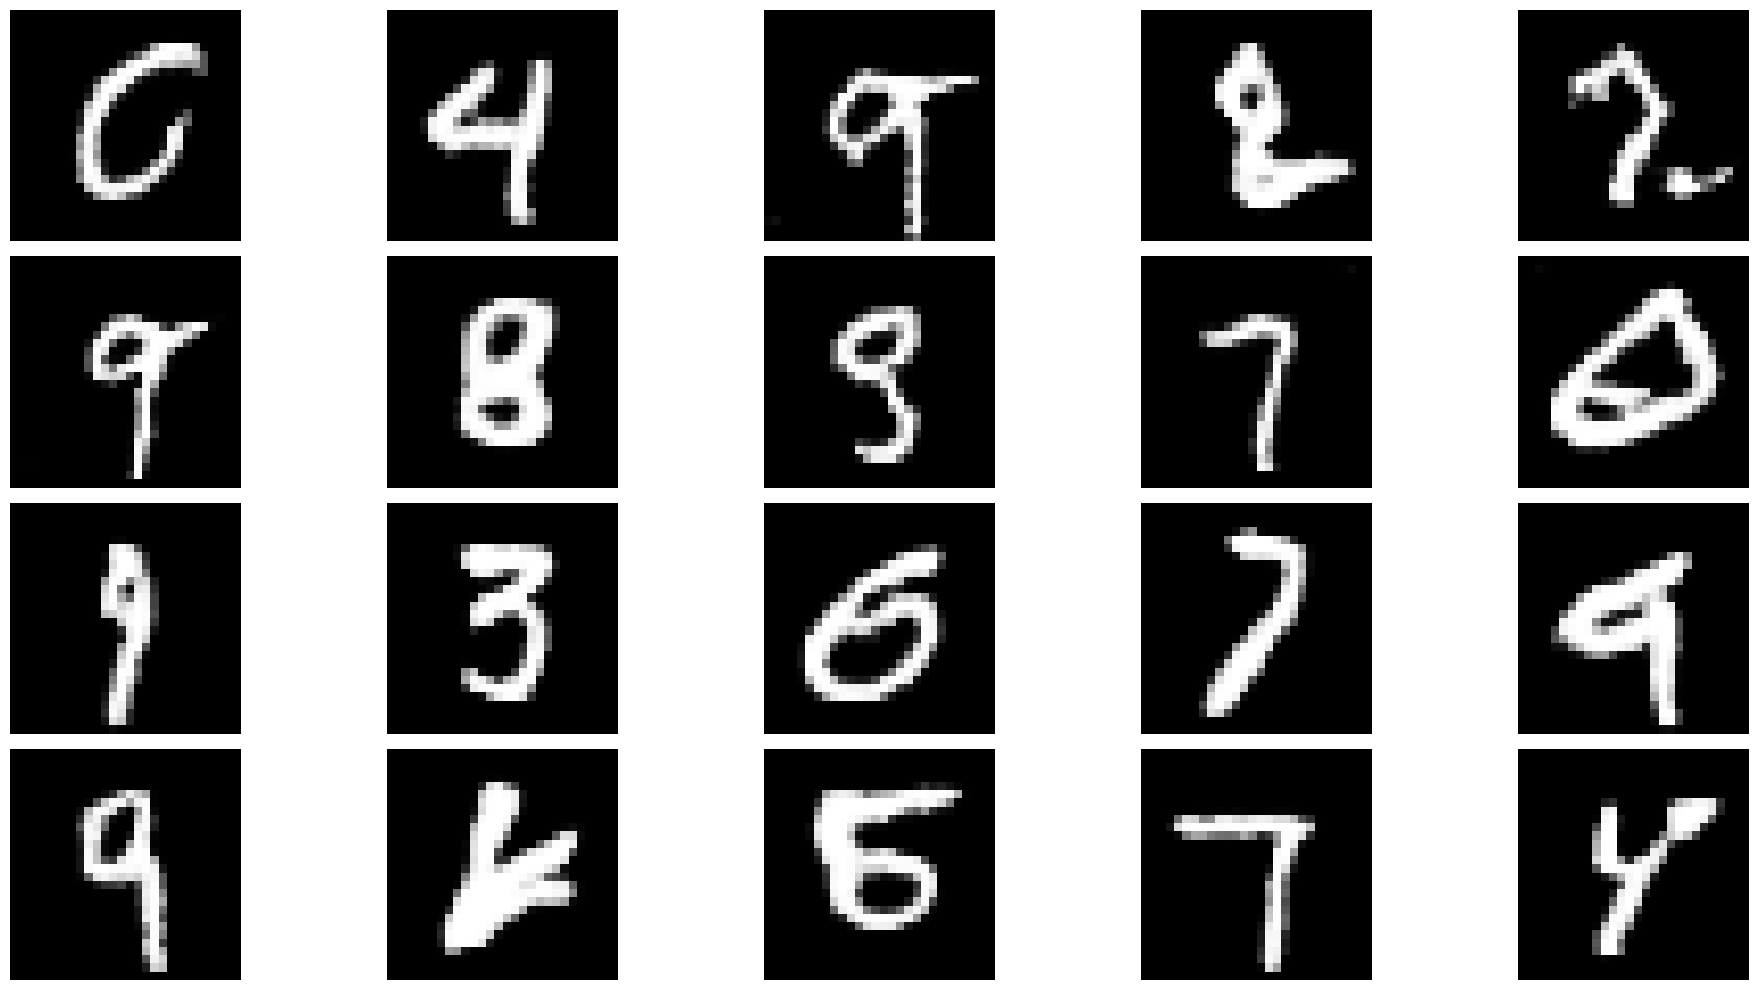

📈 Epoch 80 Summary:
   Train D Loss: 0.7928, Val D Loss: 1.3286
   Train G Loss: 1.5910, Val G Loss: 2.1714

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.992084	G_loss: 0.533026
Epoch: 81 [6400/60000 (11%)]	D_loss: 0.925737	G_loss: 2.394144
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.907737	G_loss: 2.368640
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.593292	G_loss: 2.028553
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.798982	G_loss: 2.397326
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.713215	G_loss: 1.629934
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.937164	G_loss: 2.350467
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.781167	G_loss: 2.233658
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.819417	G_loss: 1.479187
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.904993	G_loss: 2.331410
====> Epoch: 81 Train D_loss: 0.7983, Train G_loss: 1.5948
====> Epoch: 81 Val D_loss: 1.0485, Val G_loss: 0.9853
📈 Epoch 81 Summary:
   Train D Loss: 0.7983, Val D Loss: 1.0485
   Train G Loss: 1.5948

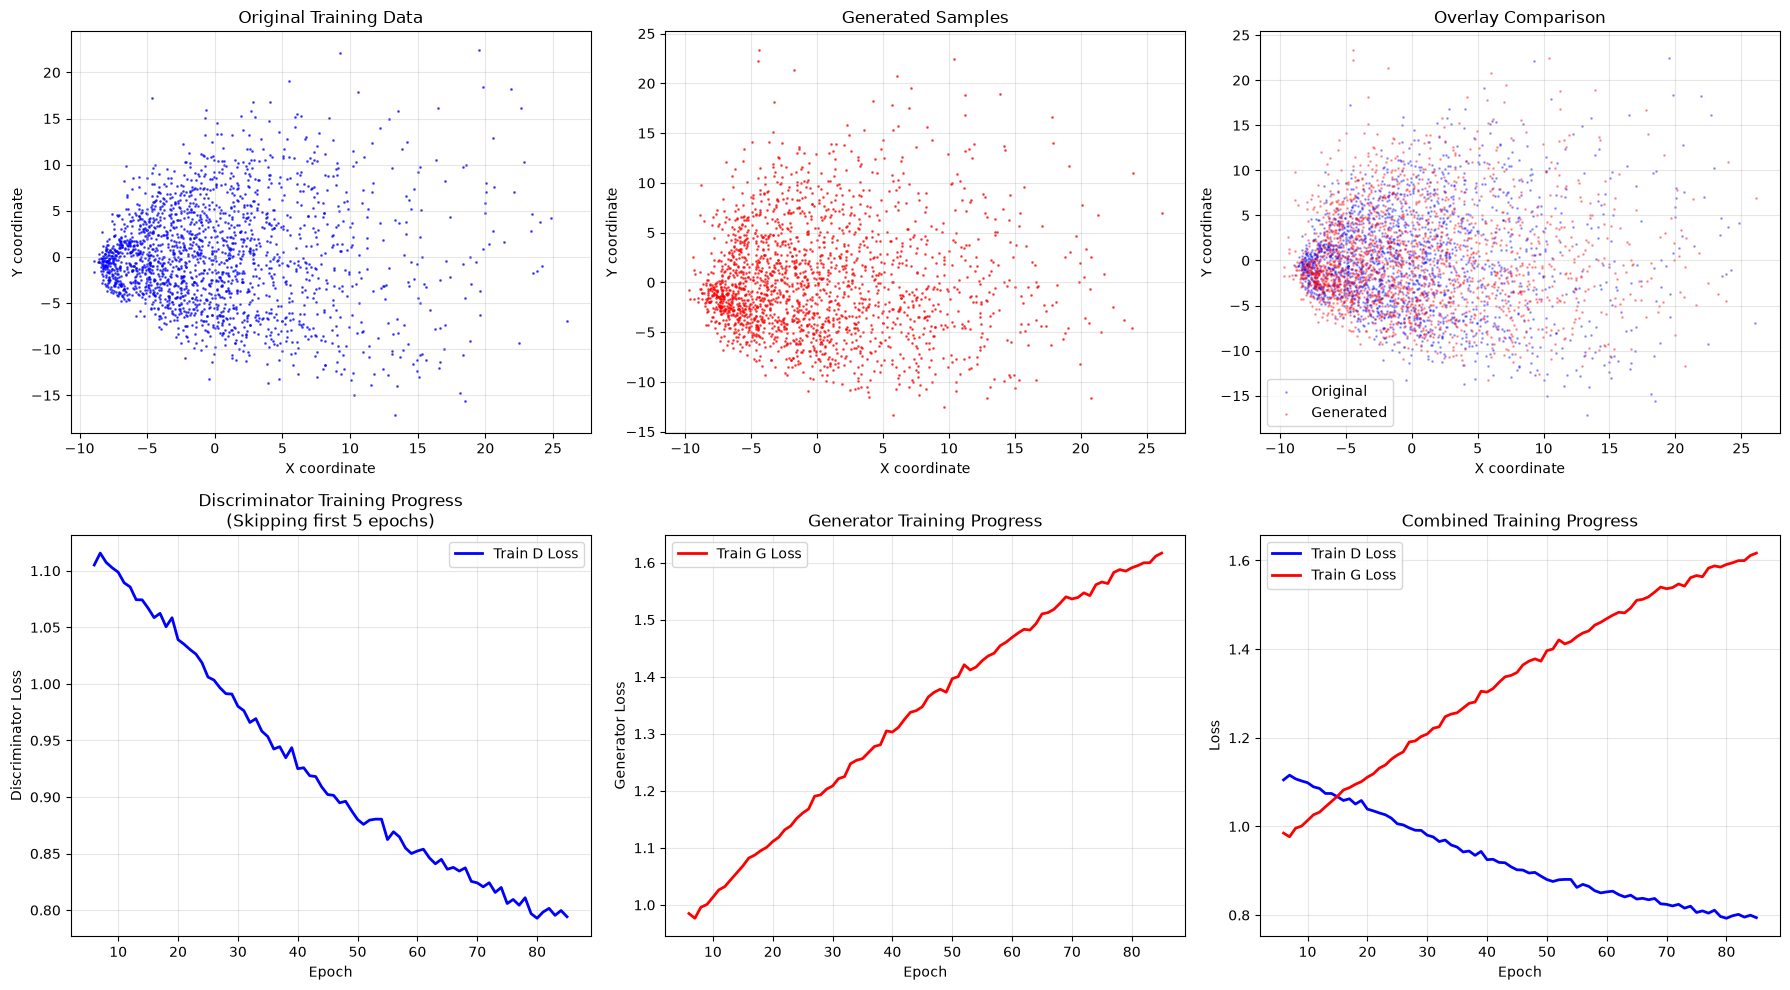

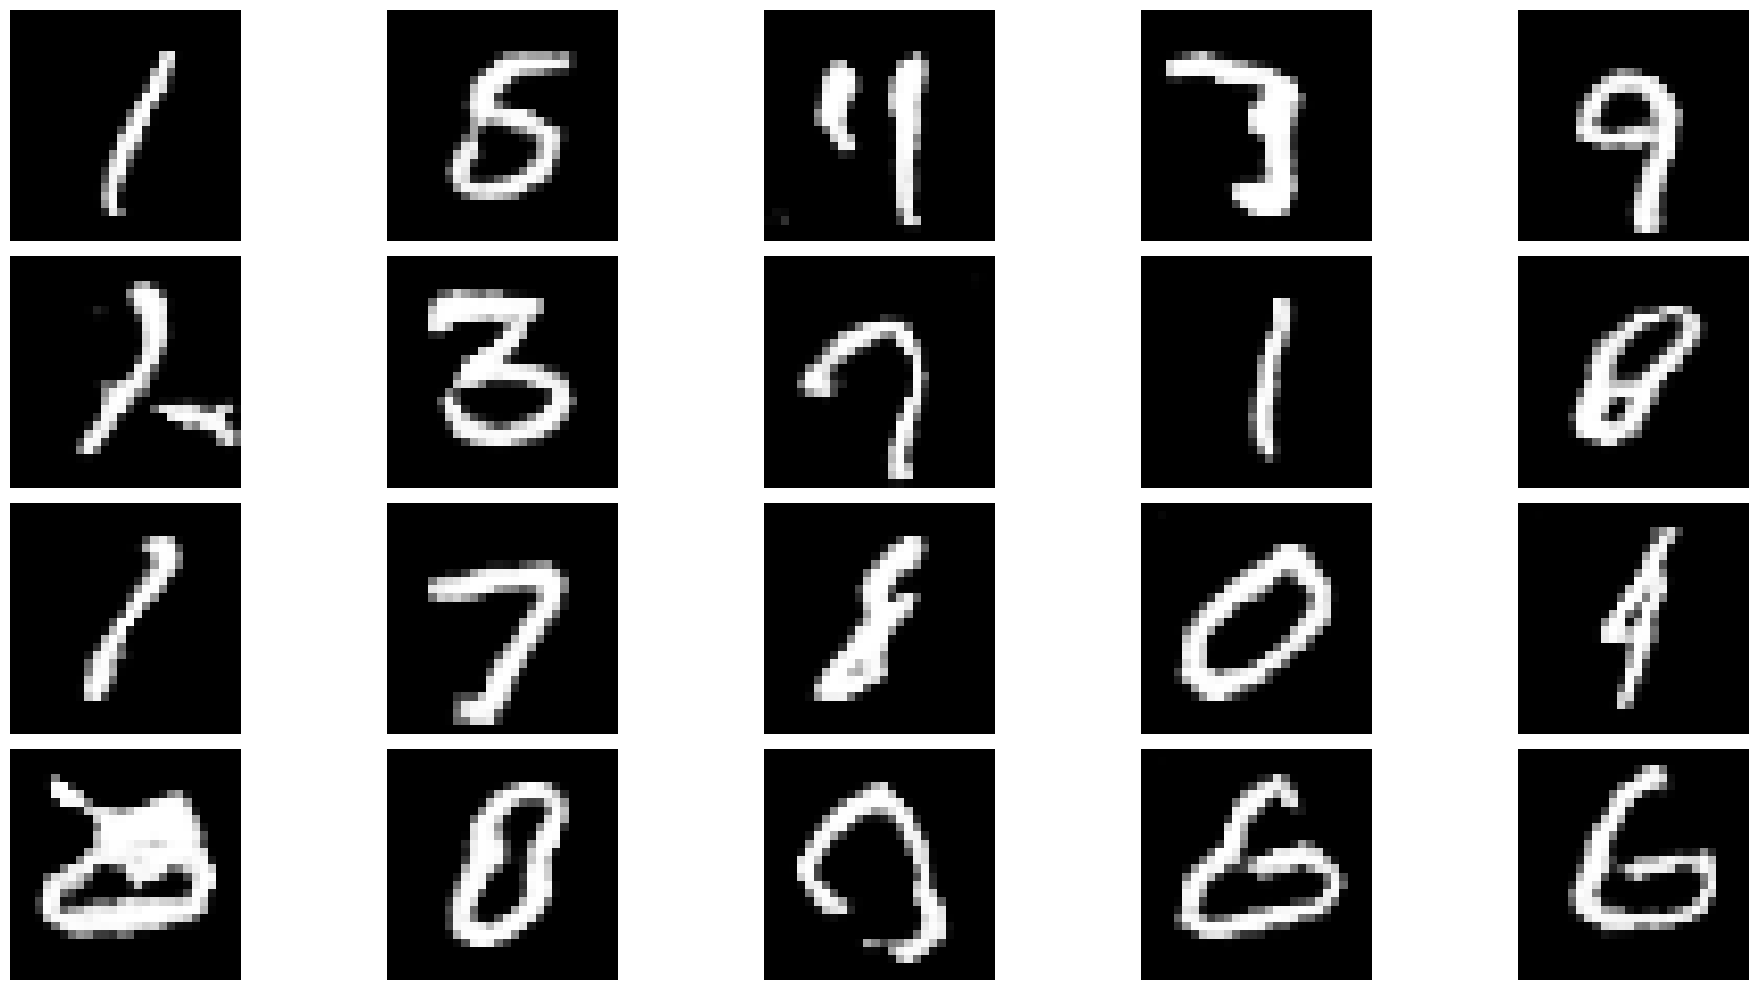

📈 Epoch 85 Summary:
   Train D Loss: 0.7942, Val D Loss: 1.1429
   Train G Loss: 1.6167, Val G Loss: 1.8094

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.775570	G_loss: 1.453852
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.679865	G_loss: 1.341127
Epoch: 86 [12800/60000 (21%)]	D_loss: 1.054252	G_loss: 3.388852
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.825188	G_loss: 1.547337
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.724653	G_loss: 1.520800
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.835594	G_loss: 2.073179
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.807970	G_loss: 1.218986
Epoch: 86 [44800/60000 (75%)]	D_loss: 1.093987	G_loss: 0.494983
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.703227	G_loss: 2.298369
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.773351	G_loss: 1.149623
====> Epoch: 86 Train D_loss: 0.7966, Train G_loss: 1.6294
====> Epoch: 86 Val D_loss: 1.1373, Val G_loss: 1.7495
📈 Epoch 86 Summary:
   Train D Loss: 0.7966, Val D Loss: 1.1373
   Train G Loss: 1.6294

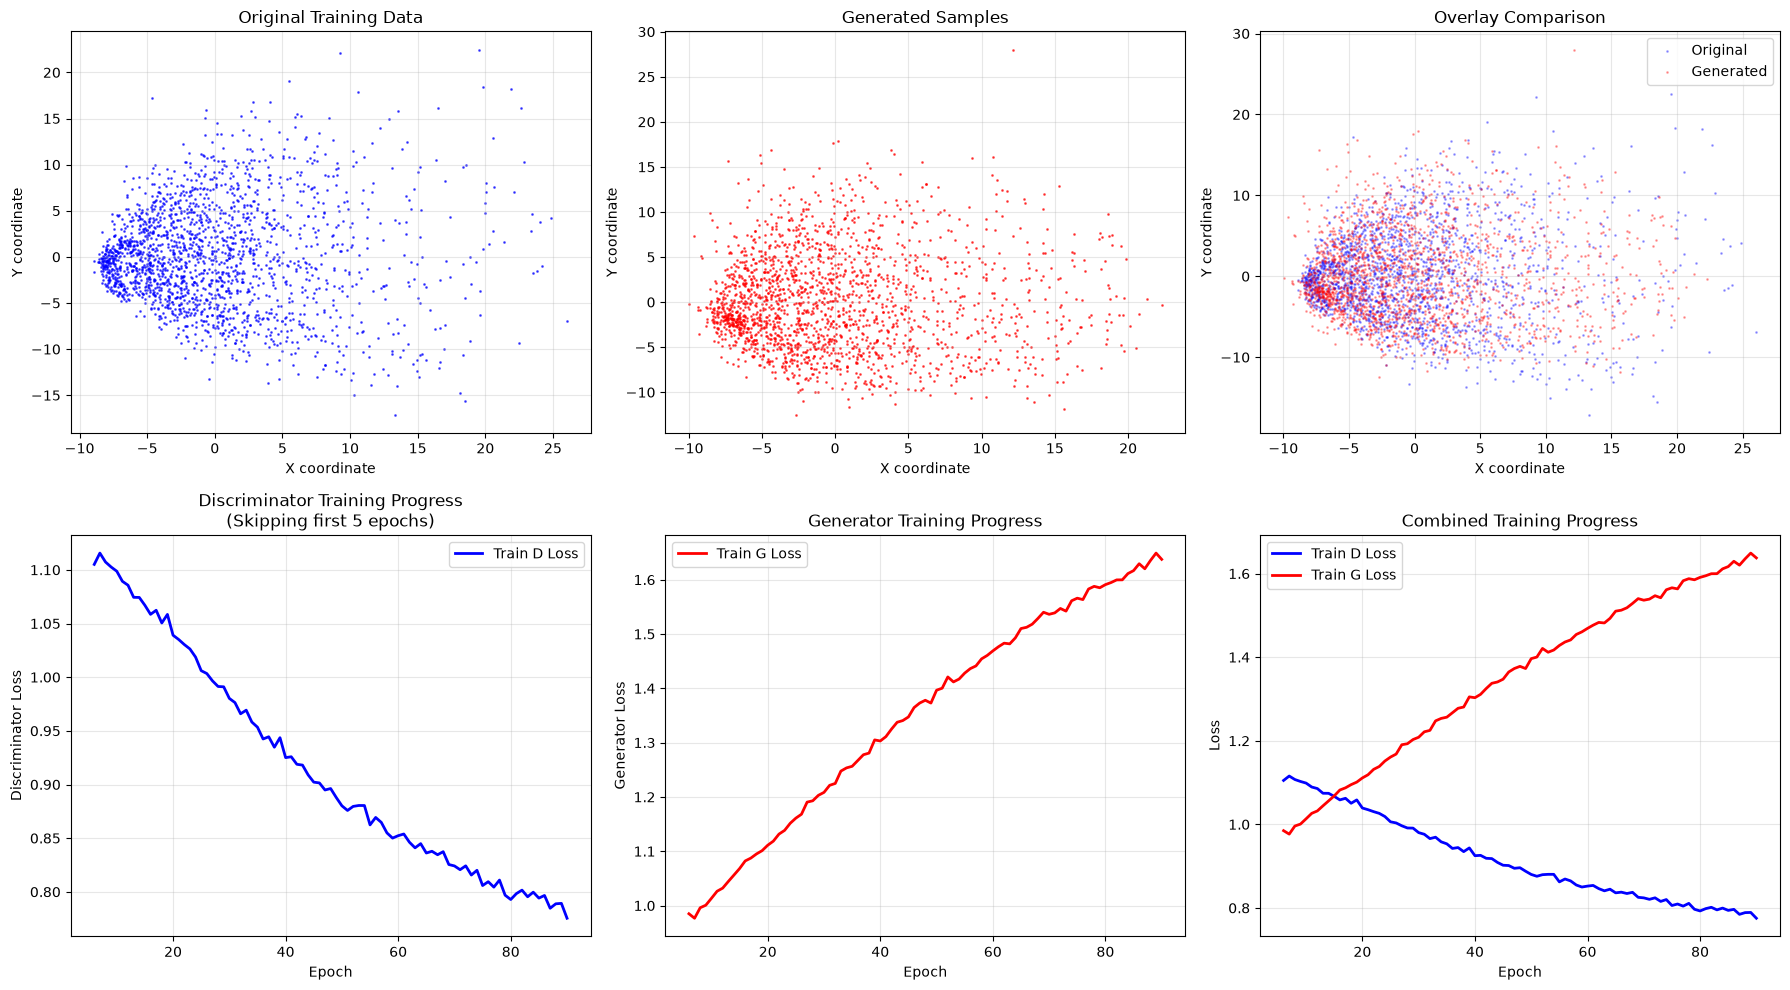

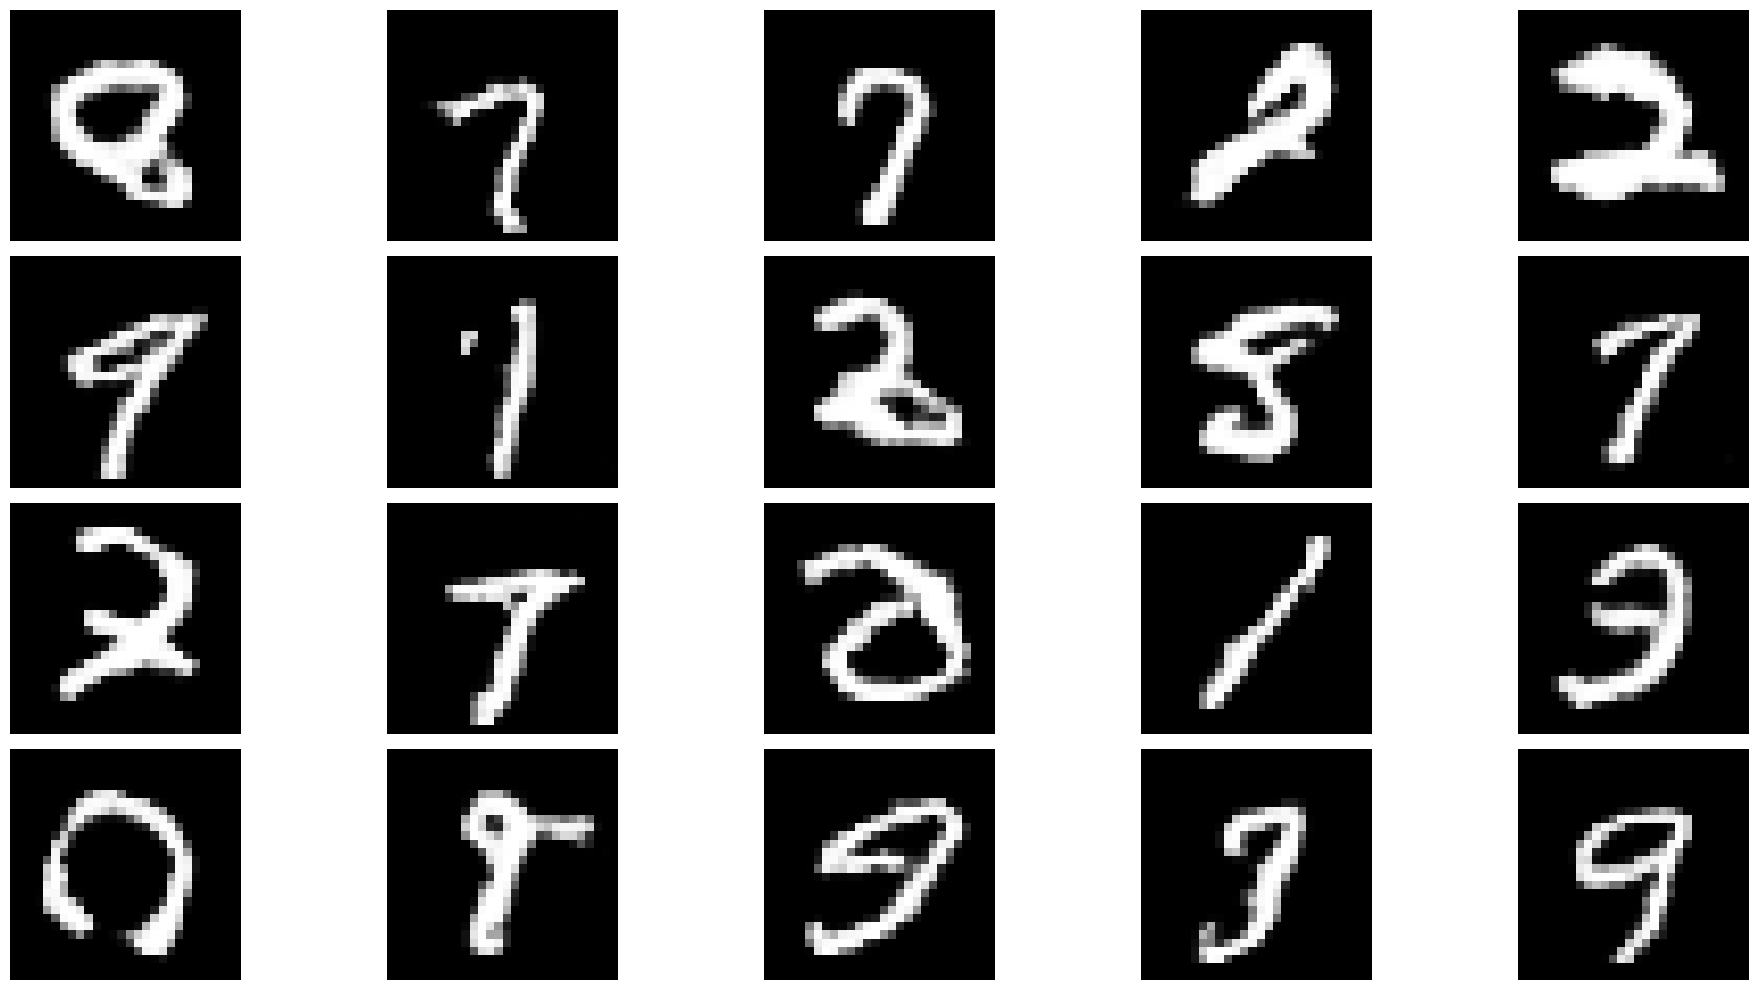

📈 Epoch 90 Summary:
   Train D Loss: 0.7754, Val D Loss: 1.0259
   Train G Loss: 1.6375, Val G Loss: 1.1699

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.716819	G_loss: 2.154144
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.815573	G_loss: 2.053547
Epoch: 91 [12800/60000 (21%)]	D_loss: 1.062743	G_loss: 2.427502
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.851771	G_loss: 0.769615
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.681570	G_loss: 1.797668
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.932170	G_loss: 2.759895
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.969379	G_loss: 2.469176
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.728916	G_loss: 1.715285
Epoch: 91 [51200/60000 (85%)]	D_loss: 0.676115	G_loss: 1.038778
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.730987	G_loss: 2.245469
====> Epoch: 91 Train D_loss: 0.7837, Train G_loss: 1.6405
====> Epoch: 91 Val D_loss: 1.1239, Val G_loss: 1.7056
📈 Epoch 91 Summary:
   Train D Loss: 0.7837, Val D Loss: 1.1239
   Train G Loss: 1.6405

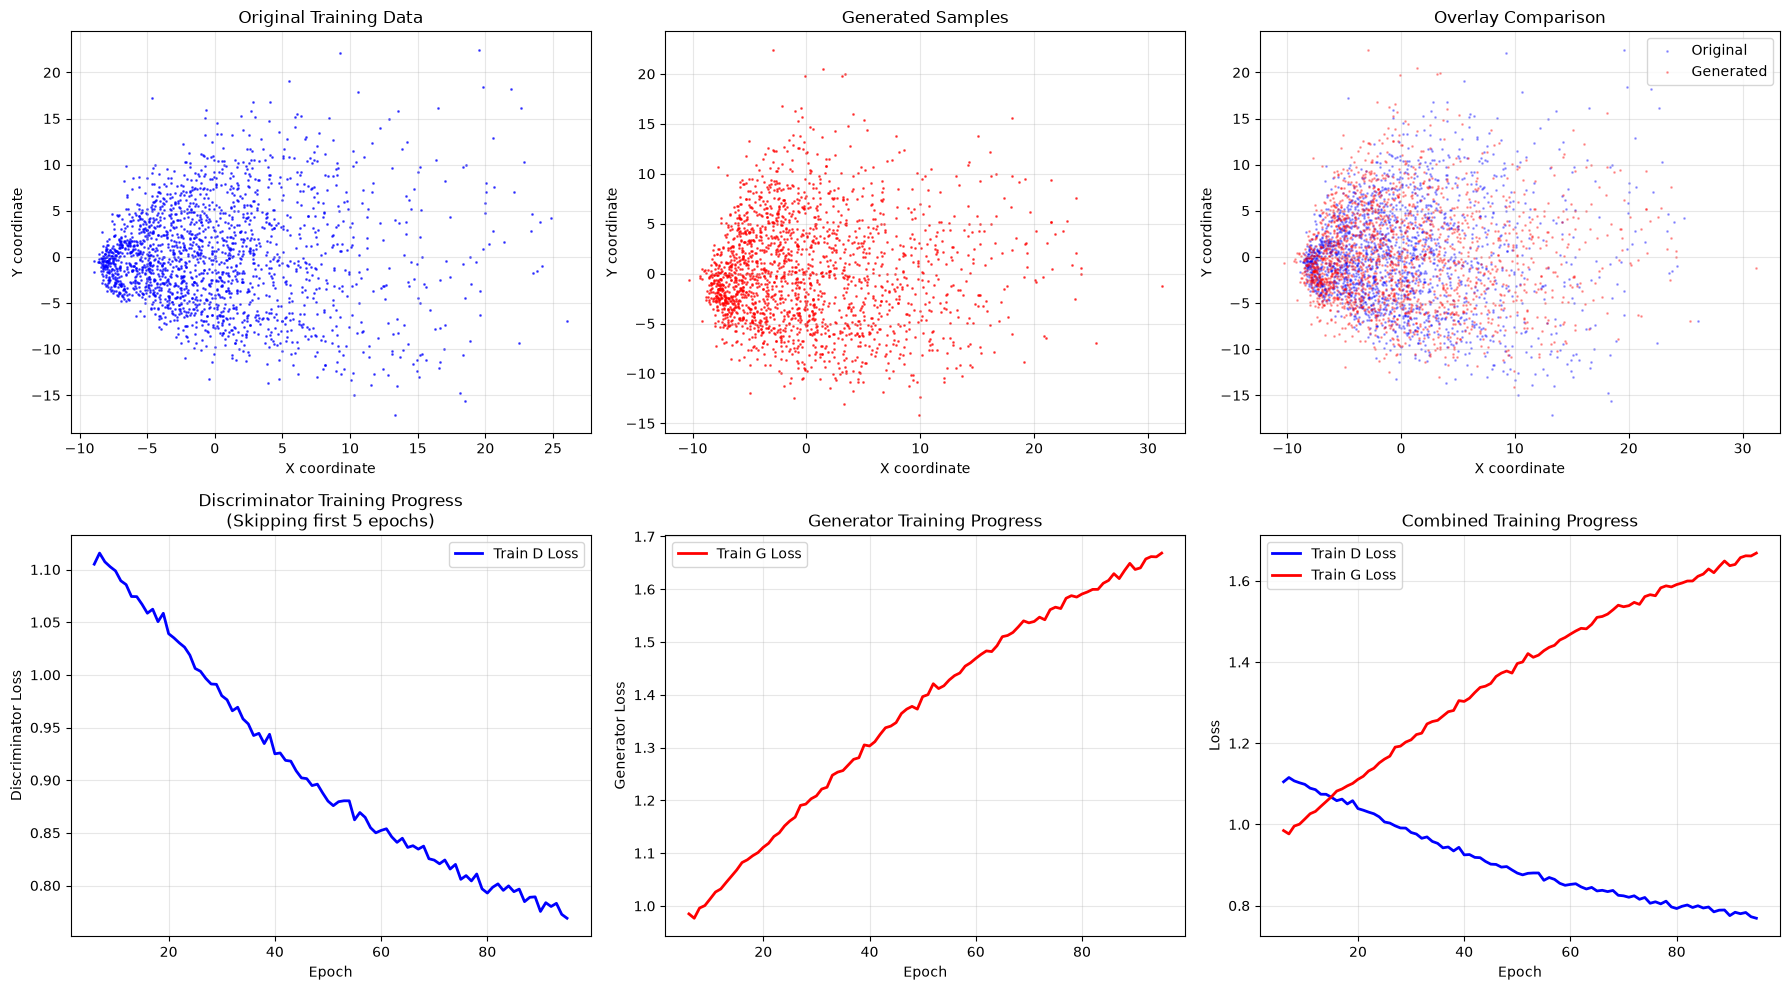

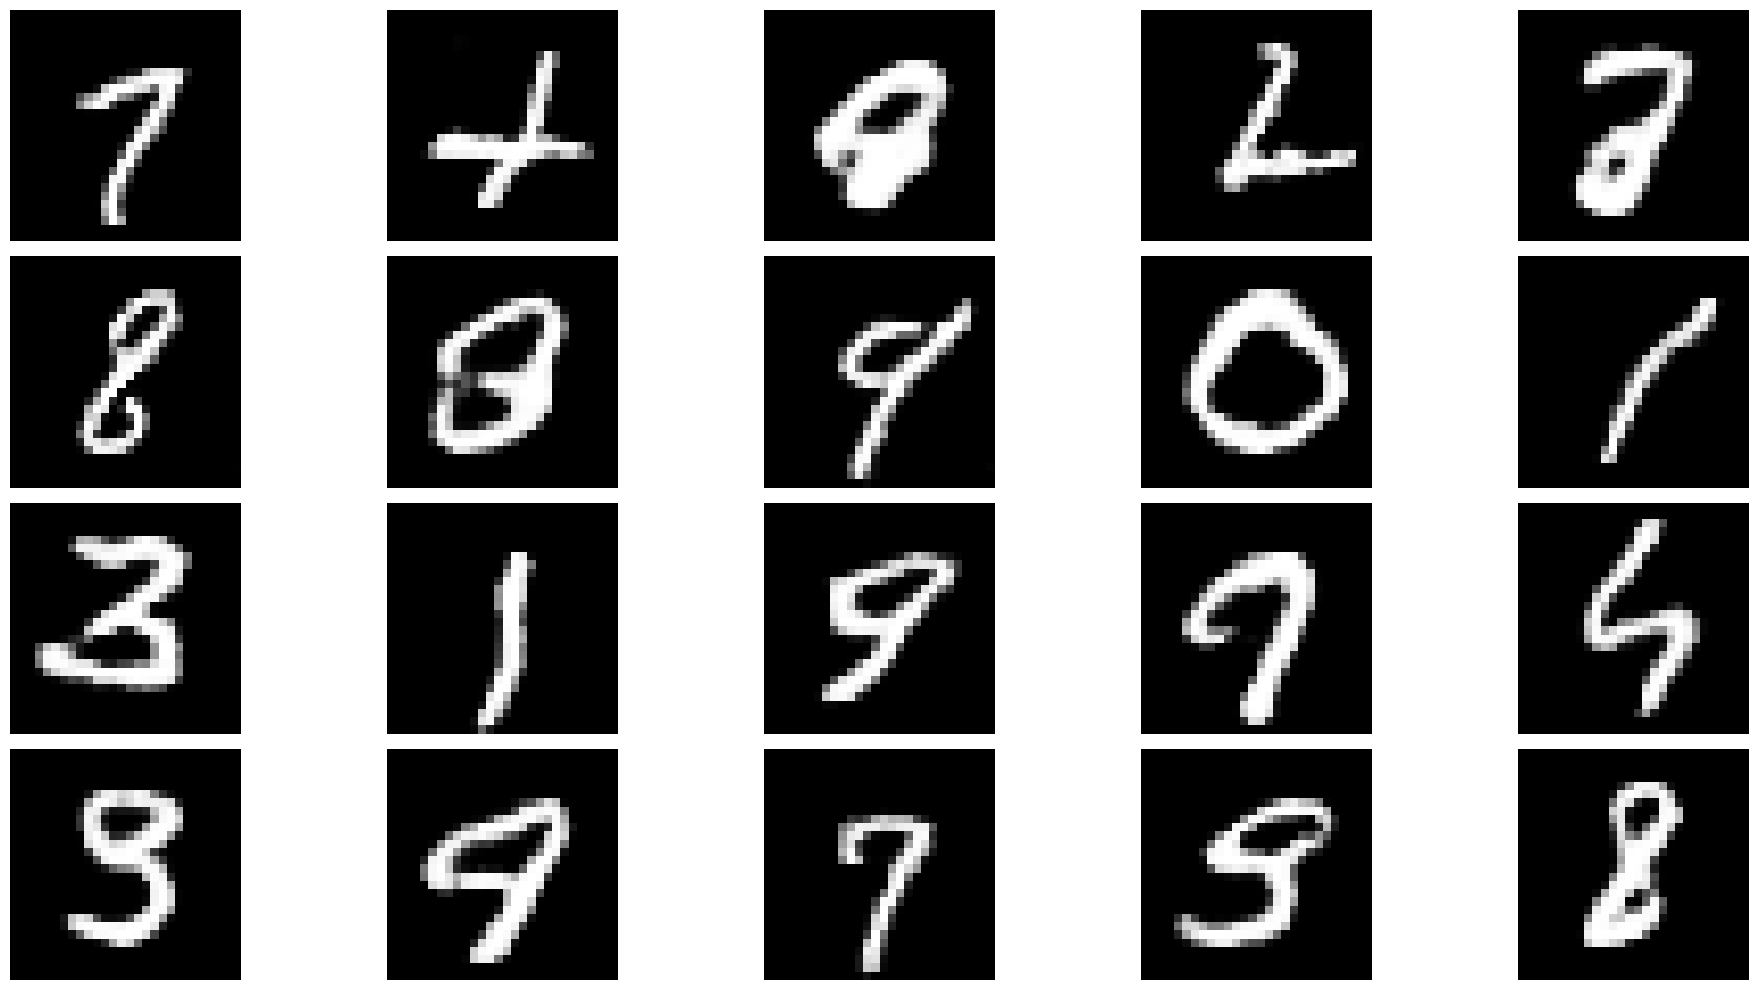

📈 Epoch 95 Summary:
   Train D Loss: 0.7689, Val D Loss: 1.0528
   Train G Loss: 1.6685, Val G Loss: 0.9496

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.836327	G_loss: 2.277893
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.678484	G_loss: 1.920729
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.721216	G_loss: 1.914657
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.923515	G_loss: 1.168475
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.726241	G_loss: 1.763143
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.724252	G_loss: 1.085647
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.833436	G_loss: 1.765524
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.745334	G_loss: 1.297801
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.701243	G_loss: 1.728889
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.842640	G_loss: 2.450518
====> Epoch: 96 Train D_loss: 0.7780, Train G_loss: 1.6782
====> Epoch: 96 Val D_loss: 1.0101, Val G_loss: 1.1733
📈 Epoch 96 Summary:
   Train D Loss: 0.7780, Val D Loss: 1.0101
   Train G Loss: 1.6782

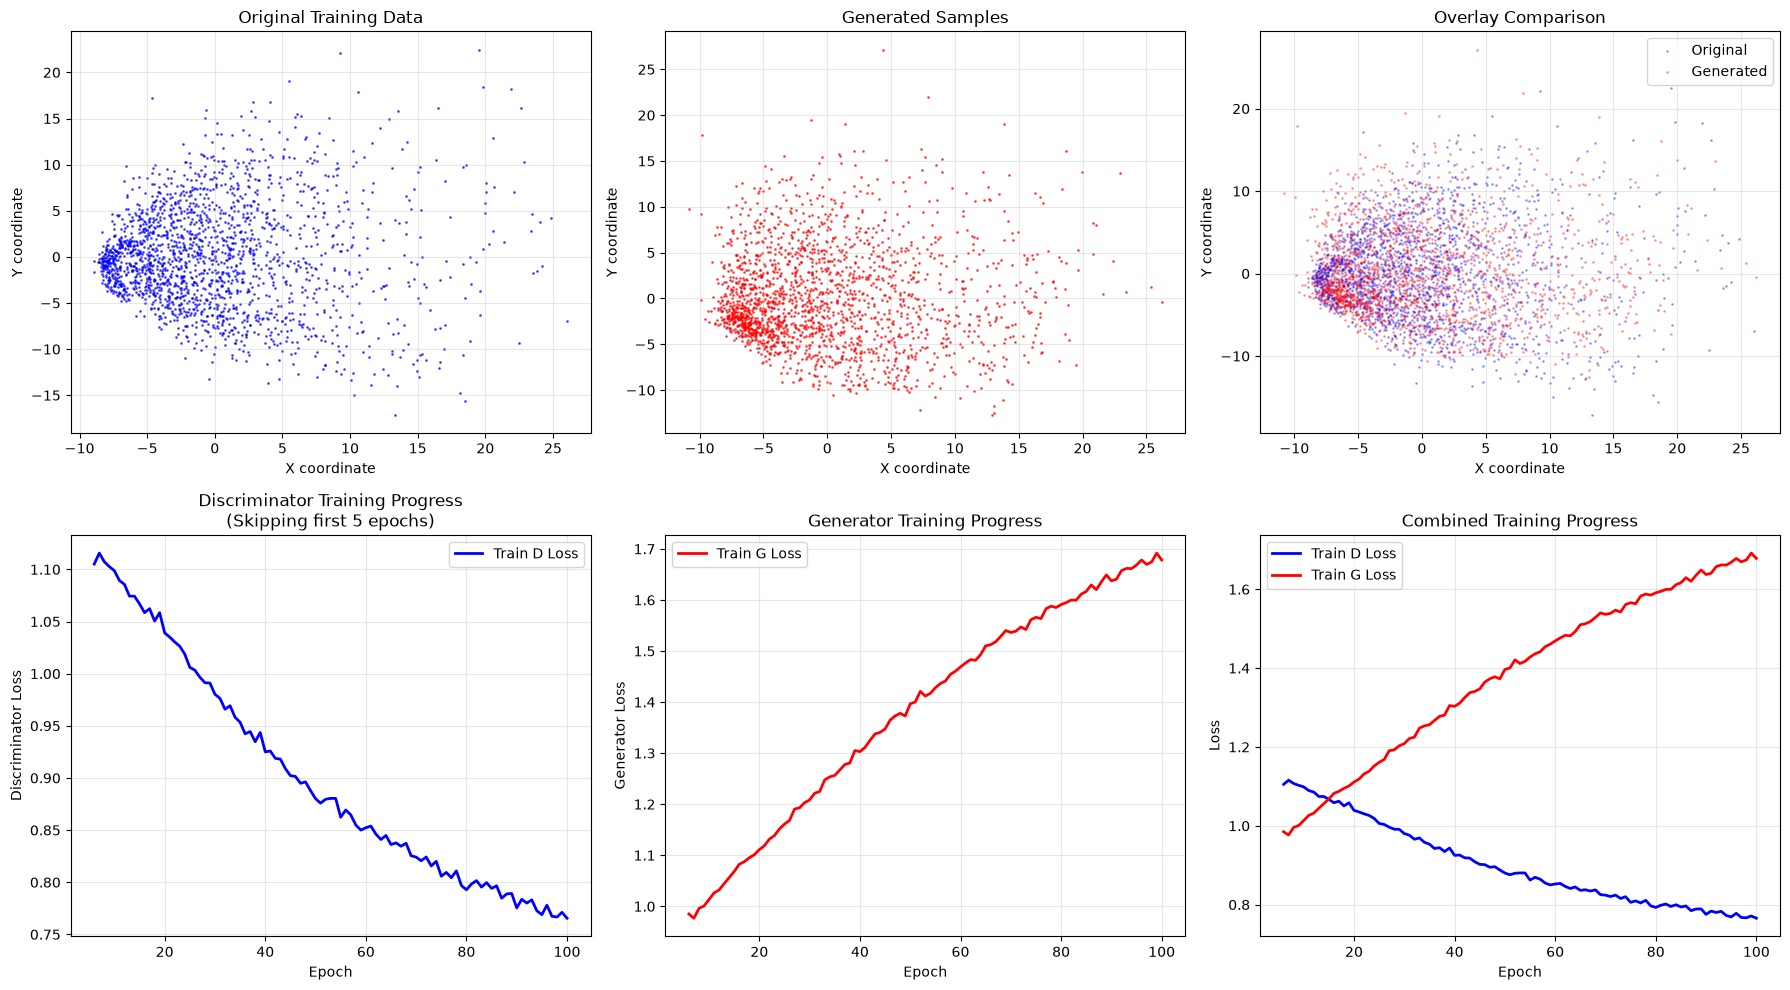

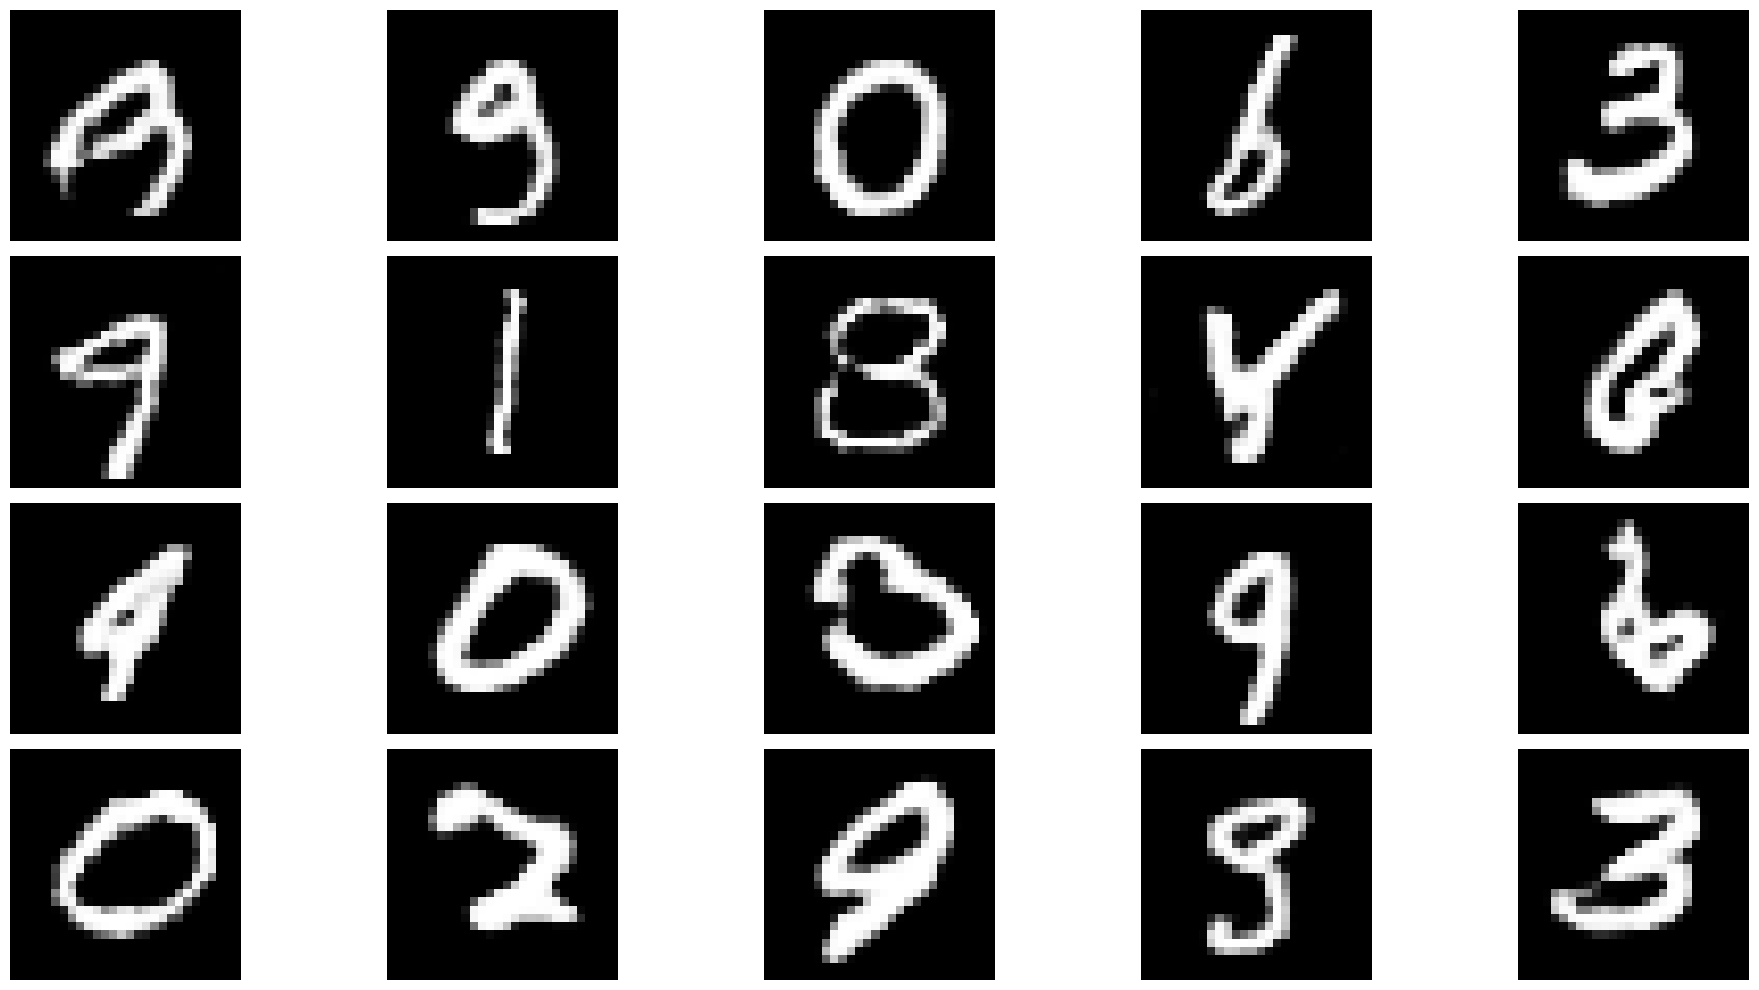

📈 Epoch 100 Summary:
   Train D Loss: 0.7655, Val D Loss: 1.1209
   Train G Loss: 1.6783, Val G Loss: 1.8567

🎉 Training completed!

🎨 Final comprehensive visualization:


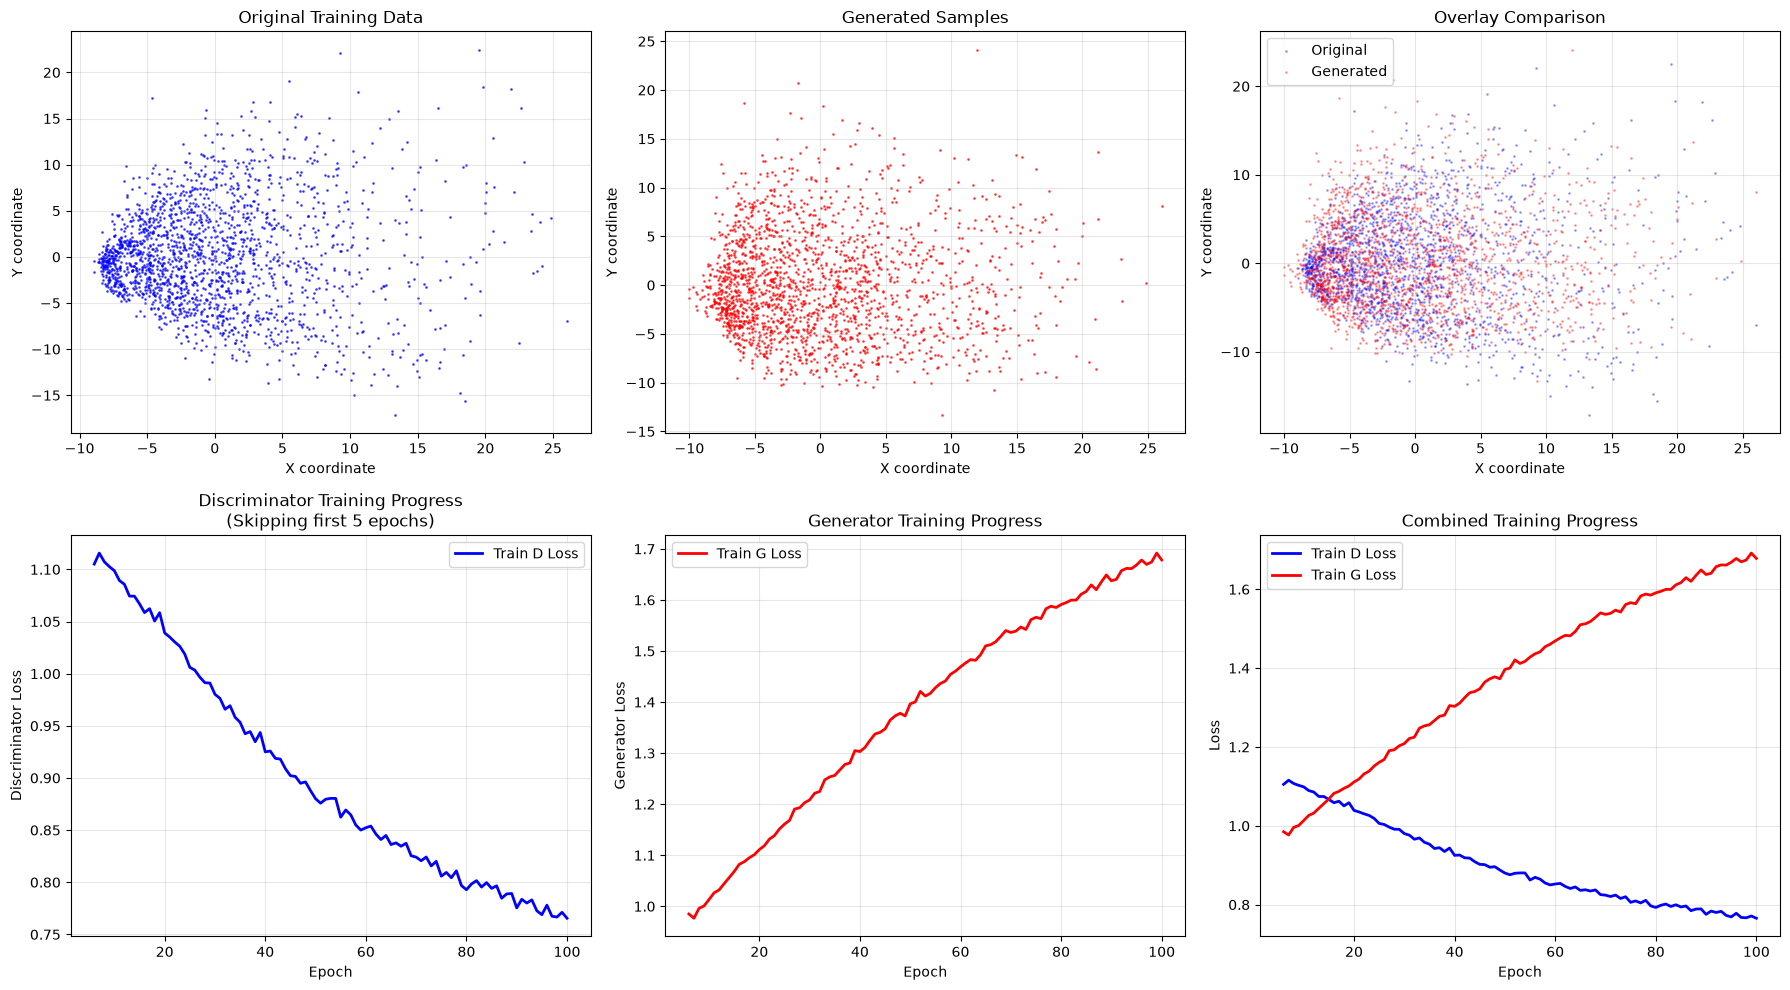

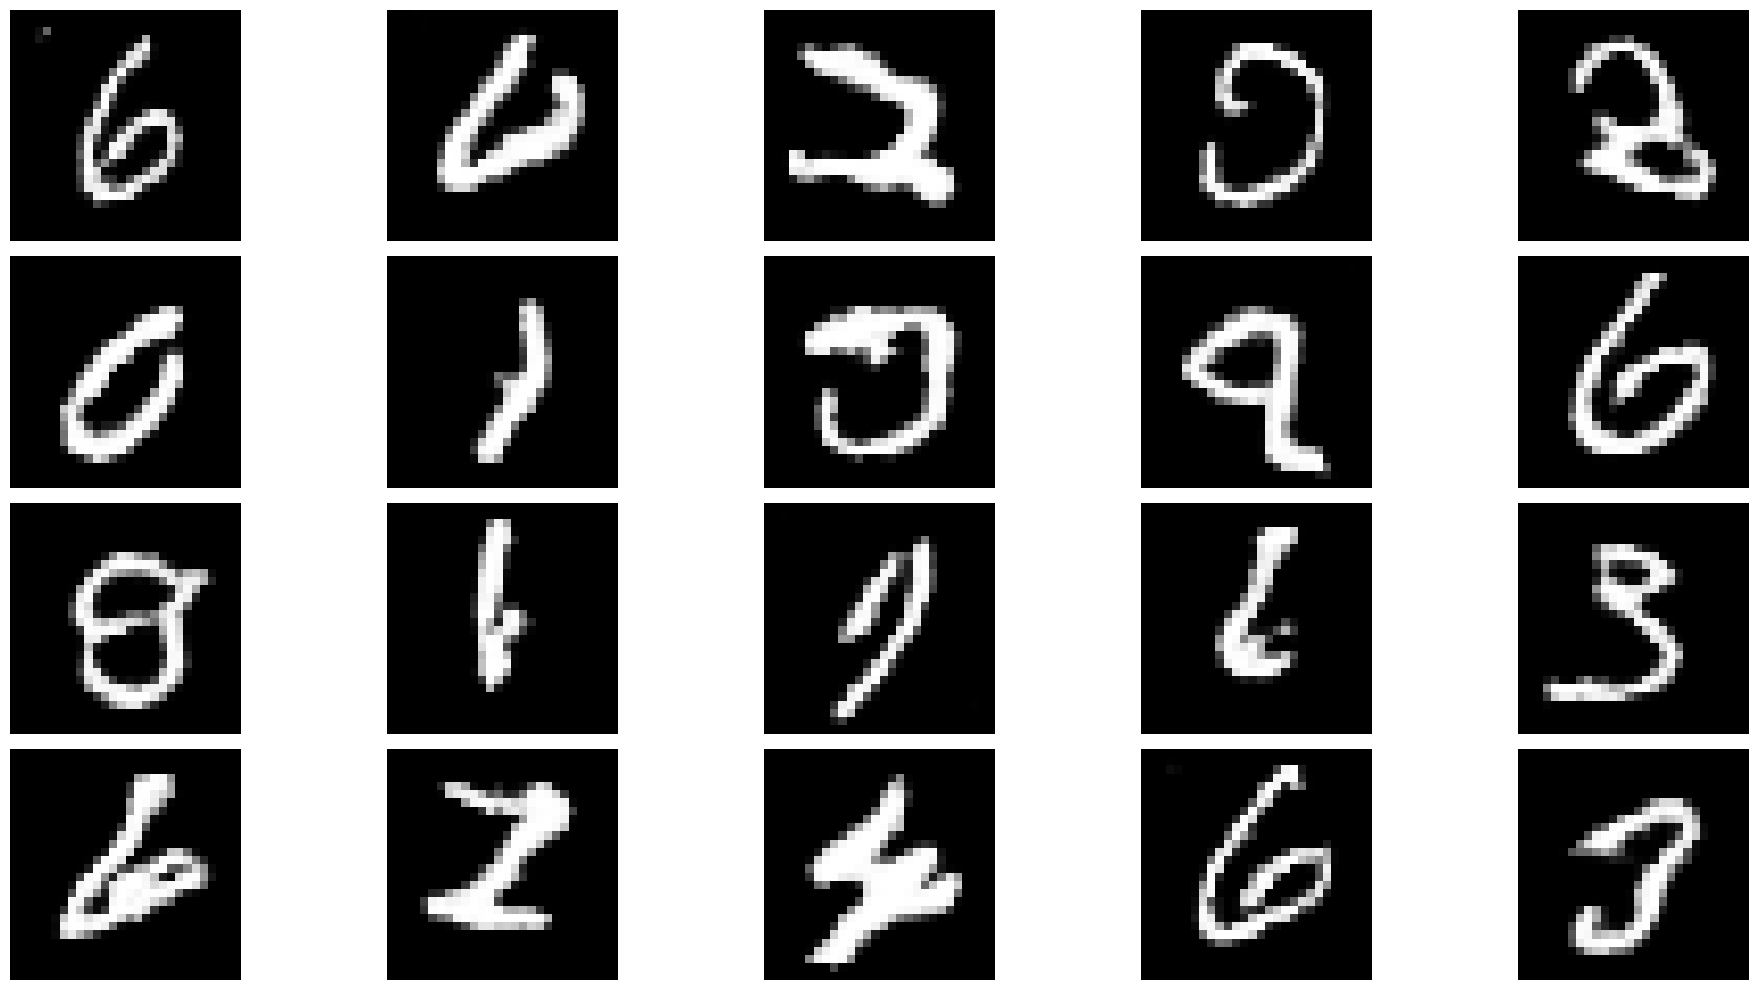

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


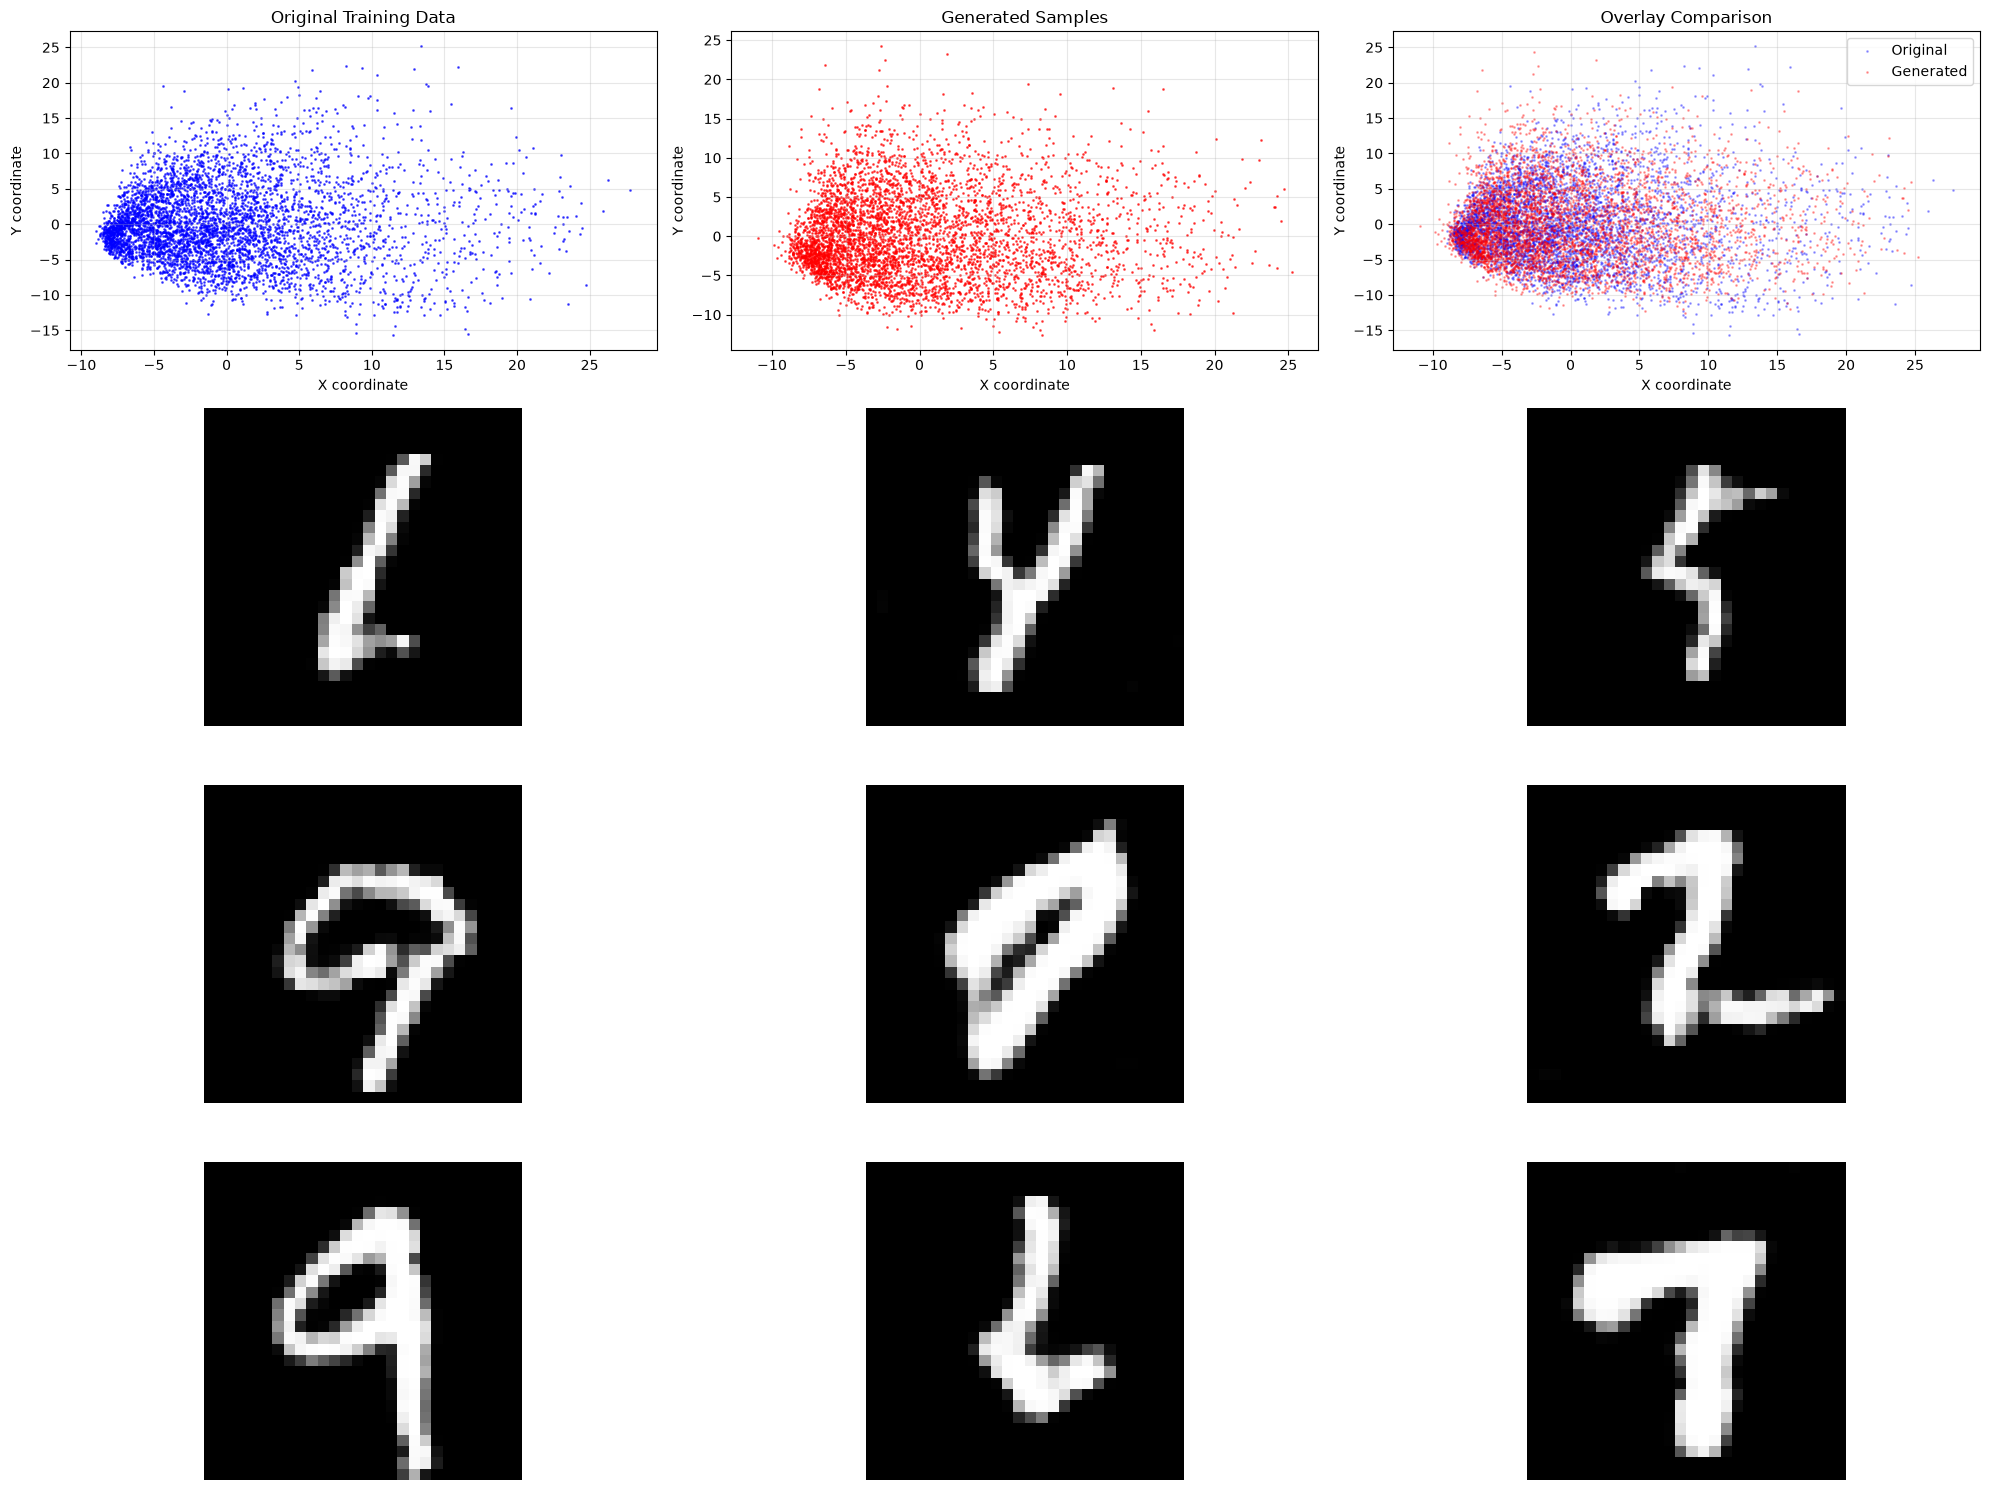

Real data confidence: 0.539
Fake data confidence: 0.243


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
